# ventilation trajectories
### copied the code for the health score trajectories to make trajectories composed of all ventilation features. We will show these to the choc doctors so that they can clarify how the data was recorded and provide some insights into how we should be handling this data.

In [36]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
training_data_filename = "combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"

experiments_dir = "/home/jake/Documents/AI_Clinician/experiments"
training_data_path = Path(experiments_dir) / training_data_filename

print(f"Loading training data from {training_data_path}")

training_data = pd.read_parquet(training_data_path)
training_data.head()

Loading training data from /home/jake/Documents/AI_Clinician/experiments/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet


,MASKED_ENCNTR_ID,EVENT_END_DT_TM,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.400000,0.0,0.0,0.0,1.0,0,0,0,1,0
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.433333,0.0,0.0,0.0,1.0,0,0,0,1,0
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.466667,0.0,0.0,0.0,1.0,0,0,0,1,0
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.500000,0.0,0.0,0.0,1.0,0,0,0,1,0
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.450000,0.0,0.0,0.0,1.0,0,0,0,1,0


In [38]:
# load features_to_use
features_to_use_path = "/home/jake/Documents/AI_Clinician/choc_code/dataframes/features_to_use.csv"
features_to_use_df = pd.read_csv(features_to_use_path)
features_to_use_df

,feature_set,feature,units,data_type,proportion_encounters,proportion_sepsis,do not use,imputation_method,state_or_action,zero_gap_hours,fill_value,note,used_in_phoenix_sepsis_score
0,airway,airway_type,NaN,ordinal,0.2954,0.4922,NaN,carry forward,NaN,12.0,0.0,"the zero gap is excessively long, but manual i...",NaN
1,airway,breath_sequence,NaN,ordinal,0.3004,0.4806,NaN,carry forward,NaN,12.0,0.0,NaN,NaN
2,airway,control_variable,NaN,ordinal,0.3004,0.4806,NaN,carry forward,NaN,12.0,0.0,NaN,NaN
3,airway,expiratory_pressure,cmH20,continuous,0.0236,0.0311,NaN,carry forward,NaN,12.0,0.0,NaN,NaN
4,airway,fio2,%,continuous,0.7368,0.8507,NaN,interpolation,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
124,demographics,white,NaN,binary,1.0000,1.0000,NaN,carry forward,NaN,NaN,NaN,NaN,NaN
125,demographics,black,NaN,binary,1.0000,1.0000,NaN,carry forward,NaN,NaN,NaN,NaN,NaN
126,demographics,hispanic,NaN,binary,1.0000,1.0000,NaN,carry forward,NaN,NaN,NaN,NaN,NaN
127,demographics,asian,NaN,binary,1.0000,1.0000,NaN,carry forward,NaN,NaN,NaN,NaN,NaN


In [39]:
encounter_col = 'MASKED_ENCNTR_ID'
time_col = 'EVENT_END_DT_TM'

In [40]:
airway_features = features_to_use_df[features_to_use_df['feature_set'] == 'airway']['feature'].tolist()
airway_features

['airway_type',
 'breath_sequence',
 'control_variable',
 'expiratory_pressure',
 'fio2',
 'inspiratory_time',
 'mean_airway_pressure',
 'mode_of_ventilation',
 'nitric_oxide',
 'oxygen_flow',
 'peep',
 'pip']

In [41]:
ecls_features = features_to_use_df[features_to_use_df['feature_set'] == 'ecls']['feature'].tolist()
ecls_features

['ecls_support_type', 'on_ecls']

In [42]:
additional_features = [
    'venous_pressure_o2',
    'end_tidal_co2',
    'oxygen_saturation',
    'respiratory_rate',
]

In [43]:
# create a list of the MASKED_ENCNTR_ID that have non-zero values for vis
vis_encounter_ids = training_data[training_data['vis'] > 0]['MASKED_ENCNTR_ID'].unique().tolist()
print(f"Number of MASKED_ENCNTR_IDs with non-zero VIS: {len(vis_encounter_ids)}")

# create a list of non-survivors
non_survivor_ids = training_data[training_data['mortality'] == 1]['MASKED_ENCNTR_ID'].unique().tolist()
print(f"Number of non-survivor MASKED_ENCNTR_IDs: {len(non_survivor_ids)}")

# make a list of survivors with non-zero VIS
survivor_ids = [enc_id for enc_id in vis_encounter_ids if enc_id not in non_survivor_ids]
print(f"Number of survivor MASKED_ENCNTR_IDs with non-zero VIS: {len(survivor_ids)}")

Number of MASKED_ENCNTR_IDs with non-zero VIS: 1208
Number of non-survivor MASKED_ENCNTR_IDs: 231
Number of survivor MASKED_ENCNTR_IDs with non-zero VIS: 1018


In [44]:
# list the columns in training_data
print("Training data columns:")
print(training_data.columns)

Training data columns:
Index(['MASKED_ENCNTR_ID', 'EVENT_END_DT_TM', 'airway_type', 'breath_sequence',
       'control_variable', 'expiratory_pressure', 'fio2',
       'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide',
       'oxygen_flow', 'peep', 'pip', 'weight_kg', 'ecls_support_type',
       'on_ecls', 'cisatracurium', 'furosemide', 'hydralazine', 'labetalol',
       'nitroglycerin', 'nitroprusside', 'intake', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'chloral_hydrate', 'chlorothiazide', 'dexamethasone', 'dobutamine_dose',
       'furosemide_med', 'hydrocortisone', 'methylprednisolone', 'metolazone',
       'prednisolone', 'spironolactone', 'cisatracurium_med', 'clonidine_med',
       'dexmedetomidine_infusion', 'dex

In [45]:
training_features_to_use = airway_features + ecls_features + additional_features + ['vis', 'intake']
print(f"{len(training_features_to_use)} features to use:")
print(training_features_to_use)

20 features to use:
['airway_type', 'breath_sequence', 'control_variable', 'expiratory_pressure', 'fio2', 'inspiratory_time', 'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide', 'oxygen_flow', 'peep', 'pip', 'ecls_support_type', 'on_ecls', 'venous_pressure_o2', 'end_tidal_co2', 'oxygen_saturation', 'respiratory_rate', 'vis', 'intake']


In [46]:
# keep only the training_features_to_use if they exist in the training data
training_features_to_use = [feat for feat in training_features_to_use if feat in training_data.columns]
print(f"{len(training_features_to_use)} features to use after filtering:")
print(training_features_to_use)

17 features to use after filtering:
['airway_type', 'breath_sequence', 'control_variable', 'expiratory_pressure', 'fio2', 'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide', 'oxygen_flow', 'peep', 'pip', 'ecls_support_type', 'on_ecls', 'oxygen_saturation', 'respiratory_rate', 'vis', 'intake']


In [47]:
# keep only the MASKED_ENCNTR_ID, EVENT_END_DT_TM, and features_to_use columns in training_data
training_data = training_data[["MASKED_ENCNTR_ID", "EVENT_END_DT_TM"] + training_features_to_use]
training_data.head()

,MASKED_ENCNTR_ID,EVENT_END_DT_TM,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,oxygen_flow,peep,pip,ecls_support_type,on_ecls,oxygen_saturation,respiratory_rate,vis,intake
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,96.0,46.0,0.0,0.00
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,94.0,32.0,0.0,0.00
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,89.0,47.0,0.0,25.00
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,96.0,55.0,0.0,28.00
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,49.0,0.0,29.95


Proportion of VIS values greater than 60: 0.0303
Number of non-zero VIS entries: 143036


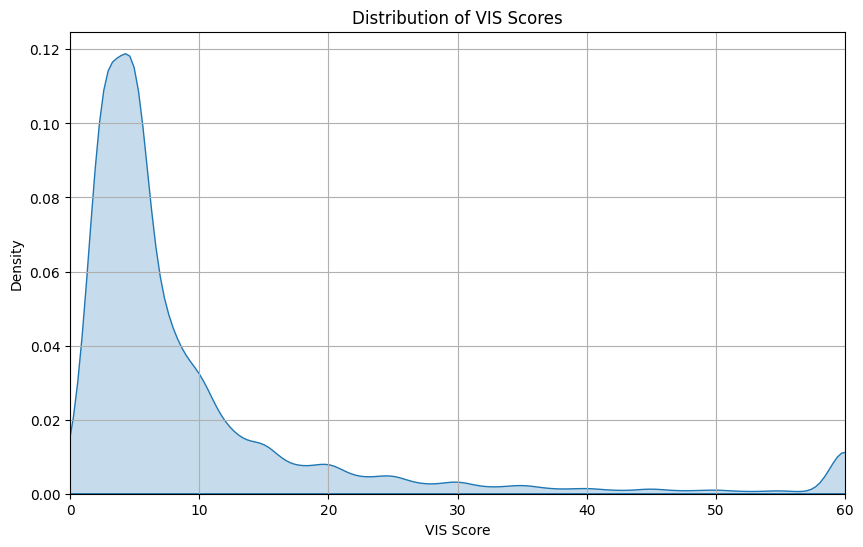

In [48]:
vis_data = training_data[training_data['vis'] > 0]['vis'].copy()

# let's squash vis to 10
x_lim = 60
# print proportion of values greater than 10
print(f"Proportion of VIS values greater than {x_lim}: {len(vis_data[vis_data > x_lim]) / len(vis_data):.4f}")

# clip vis_data at x_lim
vis_data = vis_data.clip(upper=x_lim)

print(f"Number of non-zero VIS entries: {len(vis_data)}")

# plot vis distribution as kde plot
plt.figure(figsize=(10, 6))
sns.kdeplot(vis_data, fill=True)
plt.title('Distribution of VIS Scores')
plt.xlabel('VIS Score')
plt.ylabel('Density')
plt.xlim(0, x_lim)
plt.grid(True)
plt.show()

Proportion of intake values greater than 400: 0.0135
Number of non-zero intake_data entries: 1995797


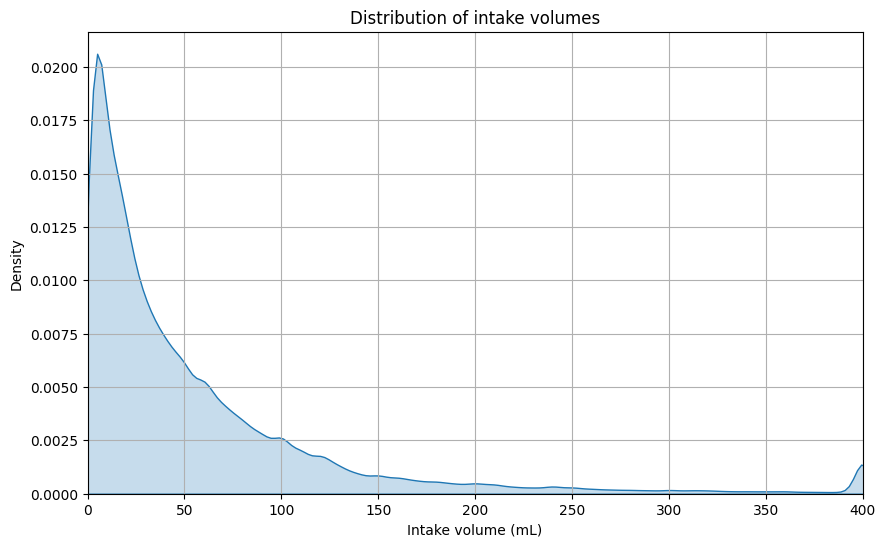

In [49]:
intake_data = training_data[training_data['intake'] > 0]['intake'].copy()

# let's squash vis to x_lim
x_lim = 400
# print proportion of values greater than 10
print(f"Proportion of intake values greater than {x_lim}: {len(intake_data[intake_data > x_lim]) / len(intake_data):.4f}")

# clip vis_data at x_lim
intake_data = intake_data.clip(upper=x_lim)

print(f"Number of non-zero intake_data entries: {len(intake_data)}")

# plot vis distribution as kde plot
plt.figure(figsize=(10, 6))
sns.kdeplot(intake_data, fill=True)
plt.title('Distribution of intake volumes')
plt.xlabel('Intake volume (mL)')
plt.ylabel('Density')
plt.xlim(0, x_lim)
plt.grid(True)
plt.show()

In [50]:
training_features_to_use

['airway_type',
 'breath_sequence',
 'control_variable',
 'expiratory_pressure',
 'fio2',
 'mean_airway_pressure',
 'mode_of_ventilation',
 'nitric_oxide',
 'oxygen_flow',
 'peep',
 'pip',
 'ecls_support_type',
 'on_ecls',
 'oxygen_saturation',
 'respiratory_rate',
 'vis',
 'intake']

In [51]:
# create dictionary of min and max values for each feature
feature_min_max = {
    'airway_type': (0, 2),  # Categorical, but keep range for heatmap
    'breath_sequence': (0, 4),
    'control_variable': (0, 2), 
    'expiratory_pressure': (0, 70), 
    'fio2': (0.21, 1.0),    
    'mean_airway_pressure': (5, 30),
    'mode_of_ventilation': (0, 3),  # Categorical, but keep range for heatmap
    'nitric_oxide': (0, 40),
    'oxygen_flow': (0, 30),
    'peep': (0, 15),
    'pip': (5, 45),
    'ecls_support_type': (0, 2),
    'on_ecls': (0, 1),
    'oxygen_saturation': (70, 100),
    'respiratory_rate': (5, 100),
    'vis': (0, 30),  # Vasoactive-Inotropic Score
    'intake': (0, 200)
}

In [52]:
# loop through the feature_min_max dictionary, and for each feature, clip the values in training_data to the min and max values
# and then min max scale the values to be between 0 and 1
training_data = training_data.copy()
for feature, (min_val, max_val) in feature_min_max.items():
    training_data[feature] = training_data[feature].clip(lower=min_val, upper=max_val)
    training_data[feature] = (training_data[feature] - min_val) / (max_val - min_val)   

training_data.head()

,MASKED_ENCNTR_ID,EVENT_END_DT_TM,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,oxygen_flow,peep,pip,ecls_support_type,on_ecls,oxygen_saturation,respiratory_rate,vis,intake
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.866667,0.431579,0.0,0.00000
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.800000,0.284211,0.0,0.00000
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.633333,0.442105,0.0,0.12500
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.866667,0.526316,0.0,0.14000
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.463158,0.0,0.14975


In [56]:
plt.rcParams.update({
    'font.size': 20,           # Default text size
    'axes.titlesize': 24,      # Title font size
    'axes.labelsize': 20,      # Axis label font size
    'xtick.labelsize': 18,     # X tick label size
    'ytick.labelsize': 18,     # Y tick label size
    'legend.fontsize': 18,     # Legend font size
    'figure.titlesize': 26     # Figure title size
})

In [57]:
def plot_encounter_heatmap(training_data, non_survivor_ids, encounter_id, plot_dir=None):
    """
    """

    print(f"Using example encounter ID: {encounter_id}")

    # check if encounter_id is in non_survivor_ids
    if encounter_id in non_survivor_ids:
        outcome = "non-survivor"
        print(f"Encounter ID {encounter_id} is a non-survivor.")
    else:
        outcome = "survivor"
        print(f"Encounter ID {encounter_id} is a survivor.")

    # training featrues 
    example_training_traj = training_data[training_data['MASKED_ENCNTR_ID'] == encounter_id]

    # drop the MASKED_ENCNTR_ID and EVENT_END_DT_TM columns
    example_training_traj = example_training_traj.drop(columns=['MASKED_ENCNTR_ID', 'EVENT_END_DT_TM'])

    # fill NaN values (if any) with 0
    example_training_traj = example_training_traj.fillna(0)

    # 2. Transpose so features are rows, timepoints are columns
    heatmap_data = example_training_traj.T

    # Set x-axis to days (assuming each column is an hour)
    n_timepoints = heatmap_data.shape[1]

    # 3. Plot heatmap
    plt.figure(figsize=(19.2, 10.8), dpi=100)
    sns.heatmap(heatmap_data, cmap='viridis', cbar=True)
    plt.xlabel("Time (days)")
    plt.ylabel("Feature")
    plt.title("Normalized Ventilation Trajectory - encounter ID: {} ({})".format(encounter_id, outcome))

    # Set x-ticks every 24 timepoints (every day)
    xtick_positions = list(range(0, n_timepoints, 24))
    xtick_labels = [int(i / 24) for i in xtick_positions]

    if len(xtick_positions) > 30:
        while len(xtick_positions) > 30:
            xtick_positions = xtick_positions[::2]
            xtick_labels = xtick_labels[::2]

    plt.xticks(ticks=xtick_positions, labels=xtick_labels)

    plt.tight_layout()

    # Save the plot if plot_dir is provided
    if plot_dir:
        os.makedirs(plot_dir, exist_ok=True)
        plot_path = os.path.join(plot_dir, f"encounter_id_{encounter_id}_{outcome}.png")
        plt.savefig(plot_path)
        print(f"Heatmap saved to {plot_path}")

    plt.show()

    return example_training_traj


In [58]:
plot_dir = "/home/jake/Documents/AI_Clinician/experiments/vent_trajectories"

Using example encounter ID: 1165397252
Encounter ID 1165397252 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165397252_survivor.png


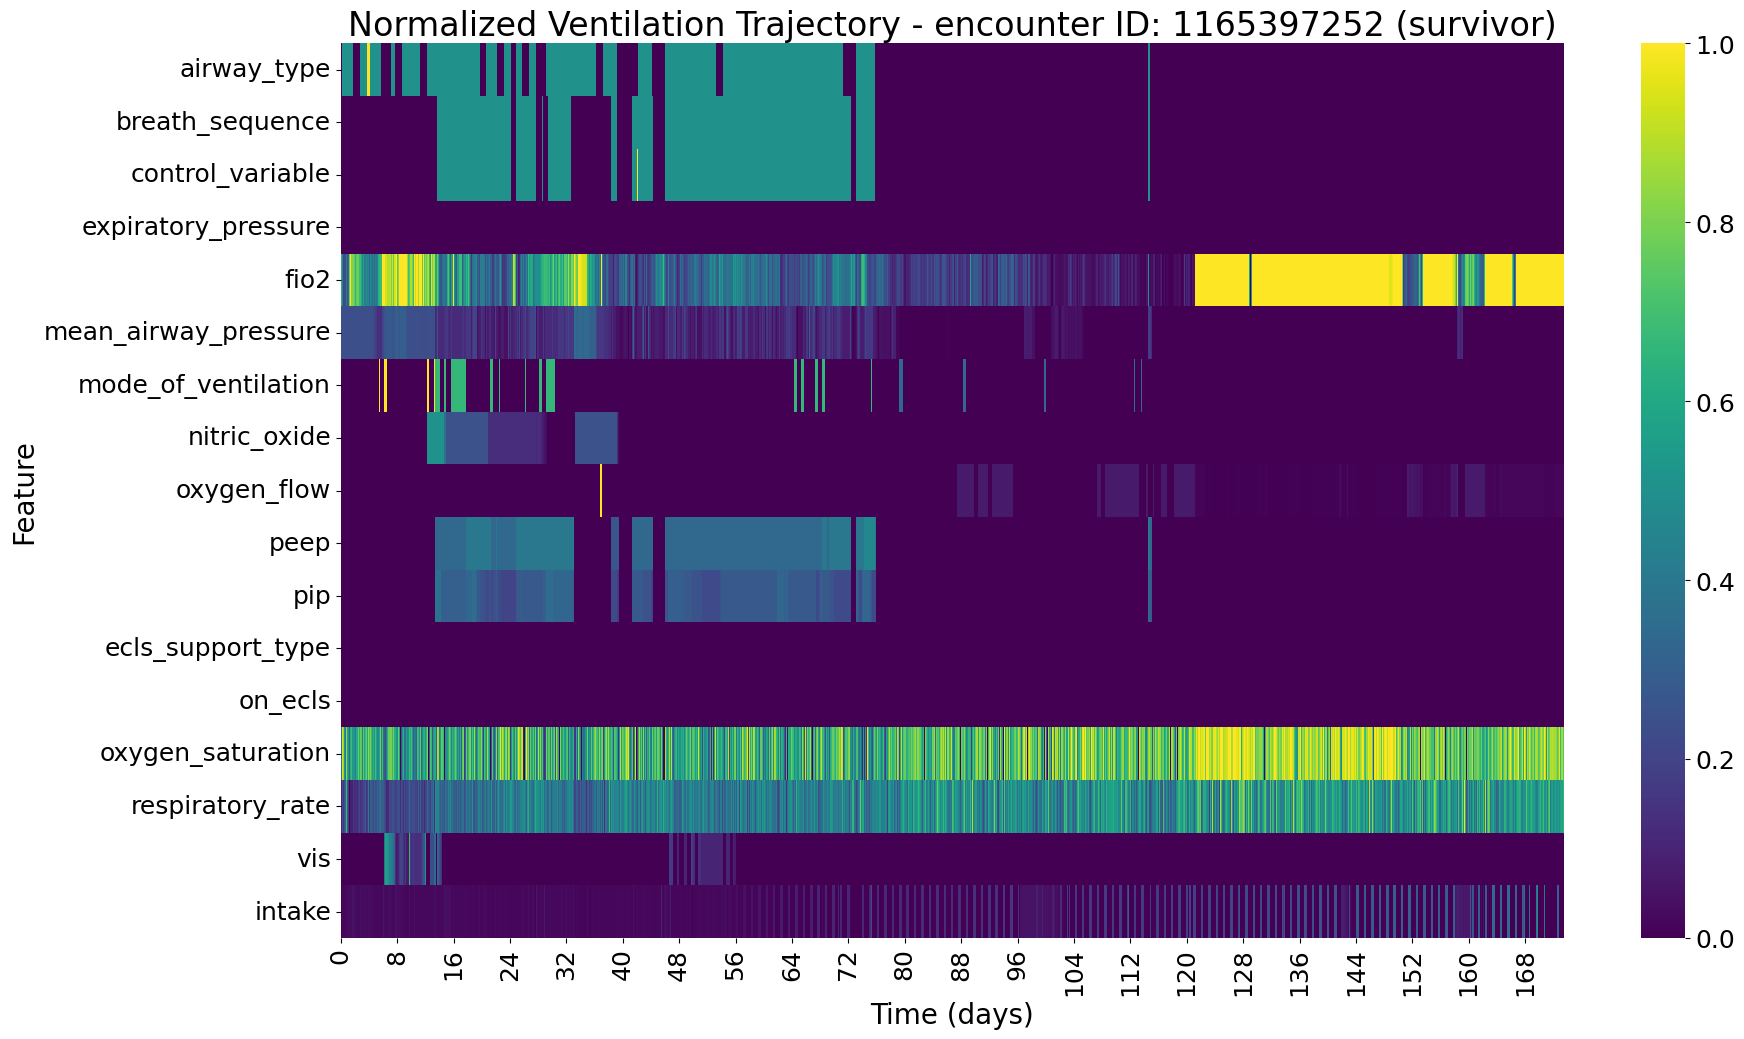

Using example encounter ID: 1165608832
Encounter ID 1165608832 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165608832_survivor.png


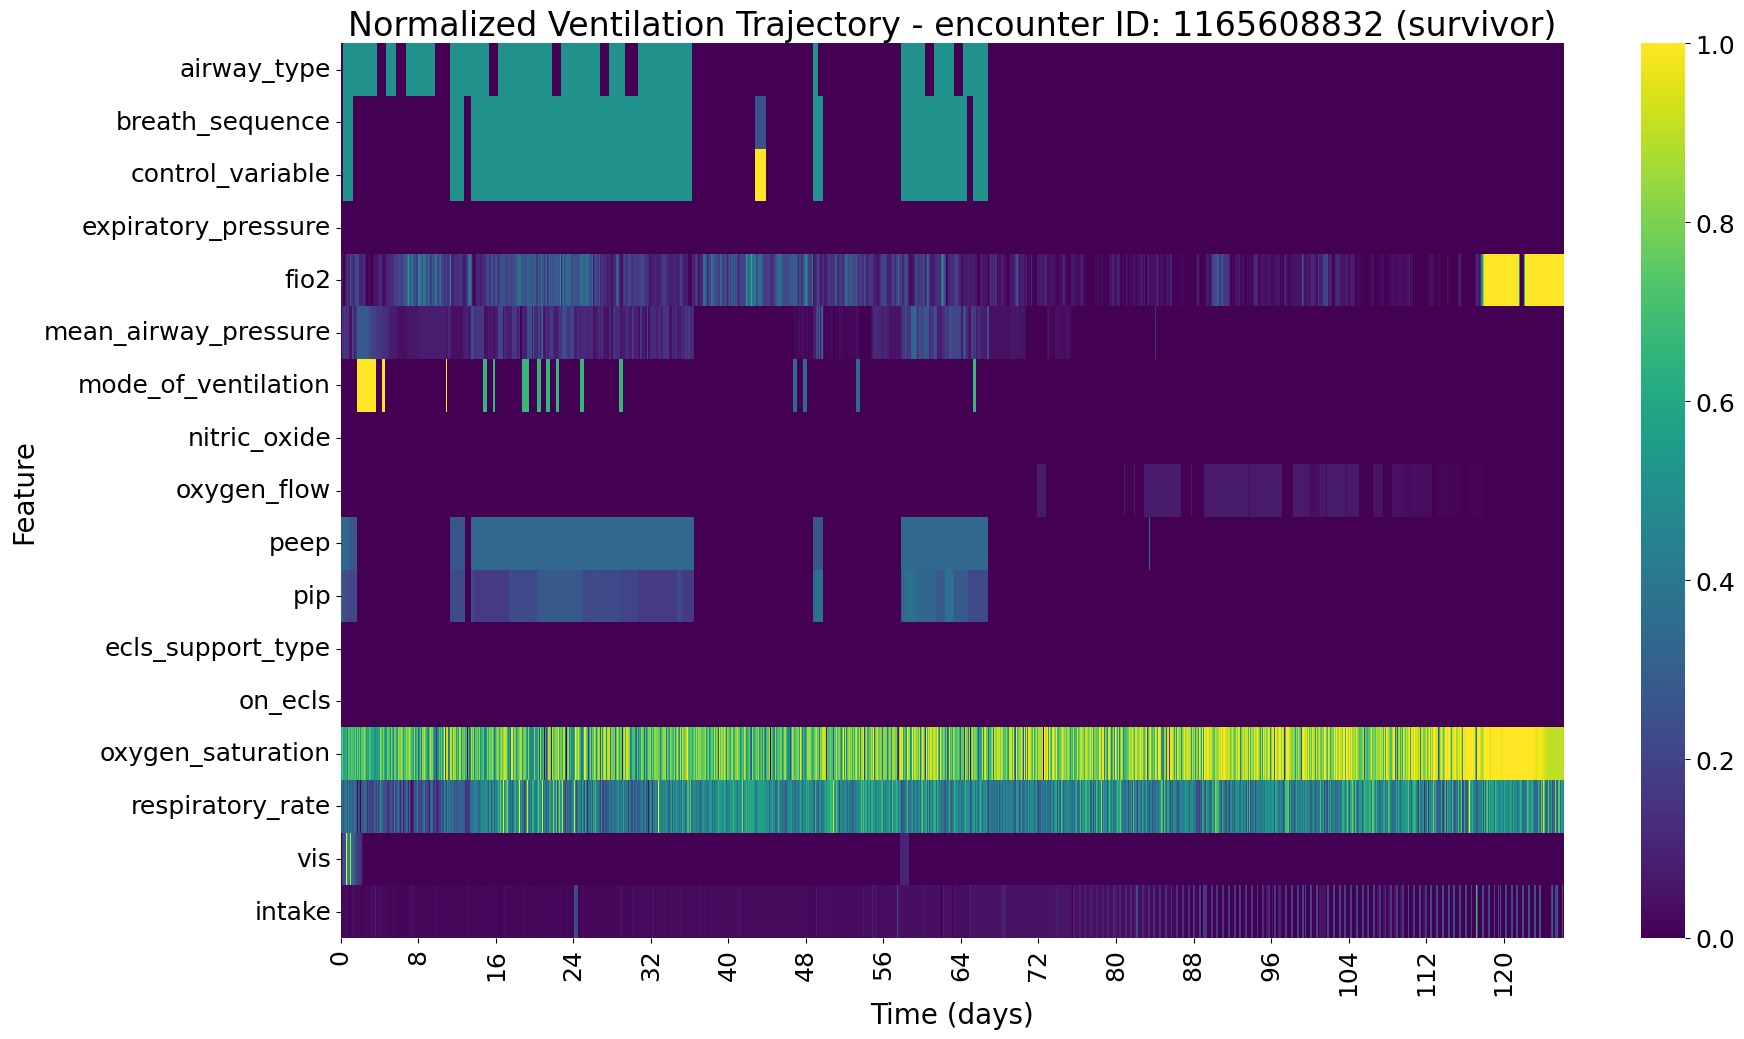

Using example encounter ID: 1165746083
Encounter ID 1165746083 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165746083_survivor.png


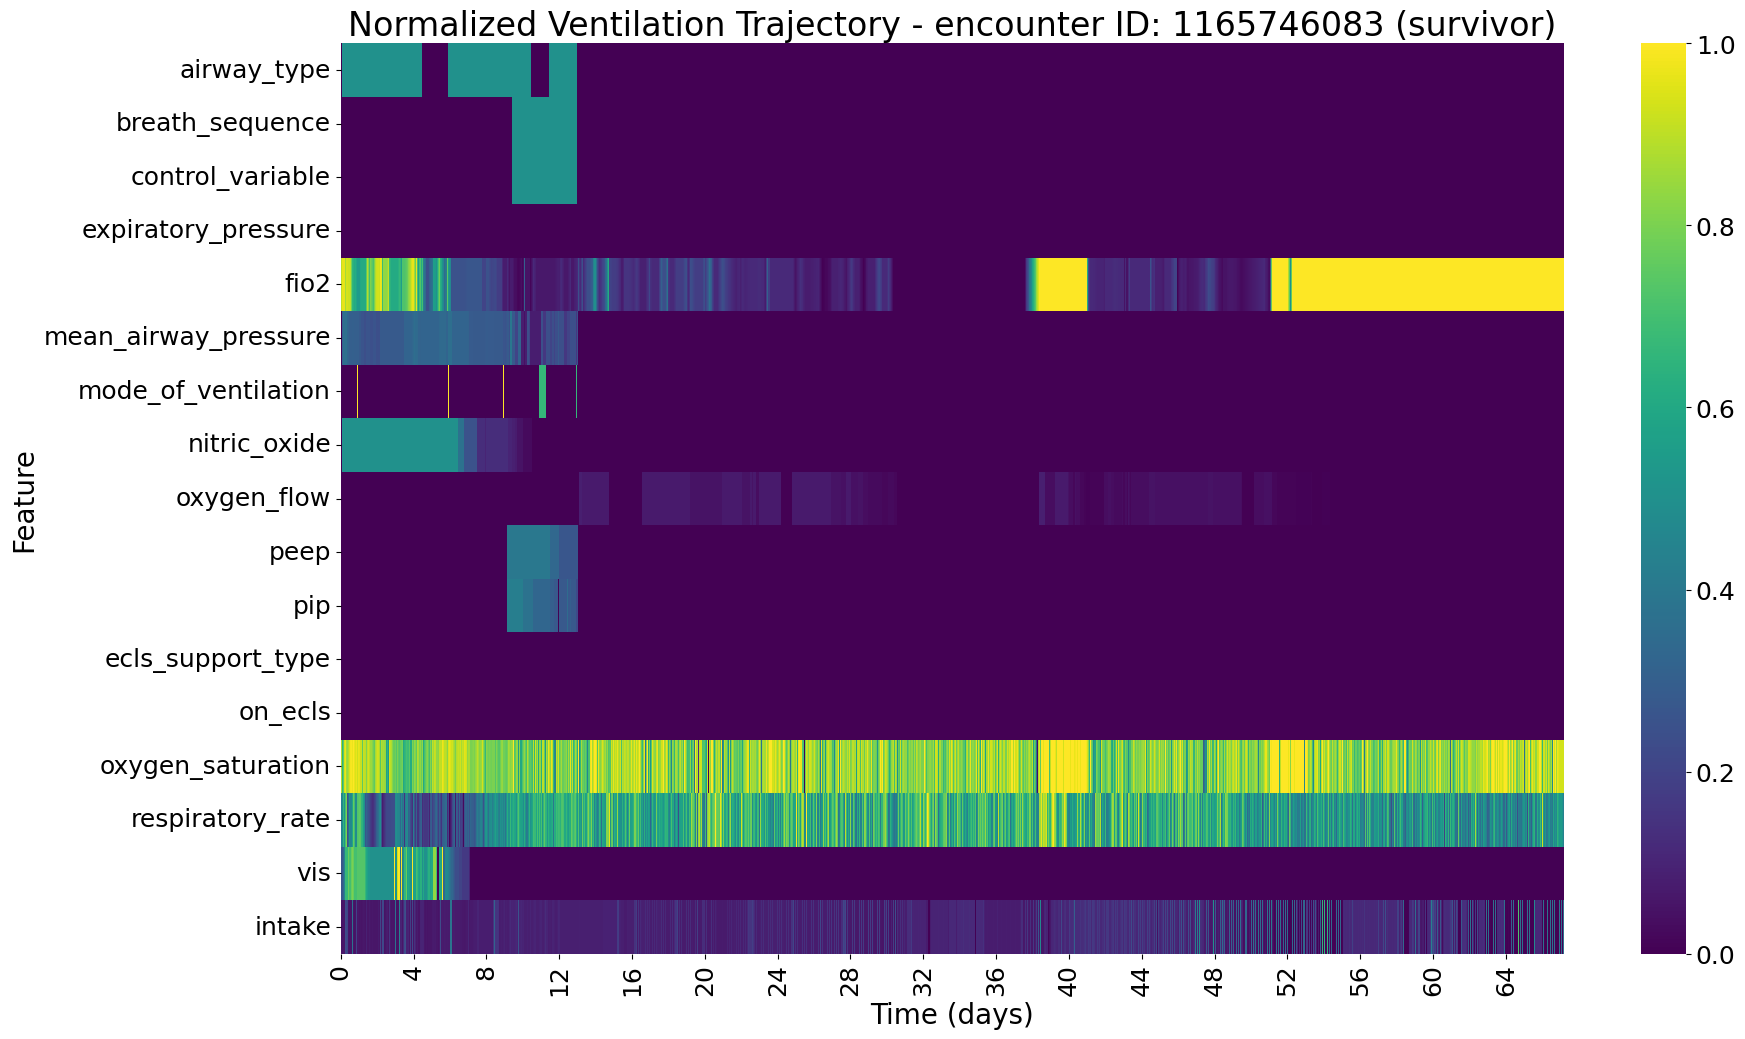

Using example encounter ID: 1165842435
Encounter ID 1165842435 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165842435_survivor.png


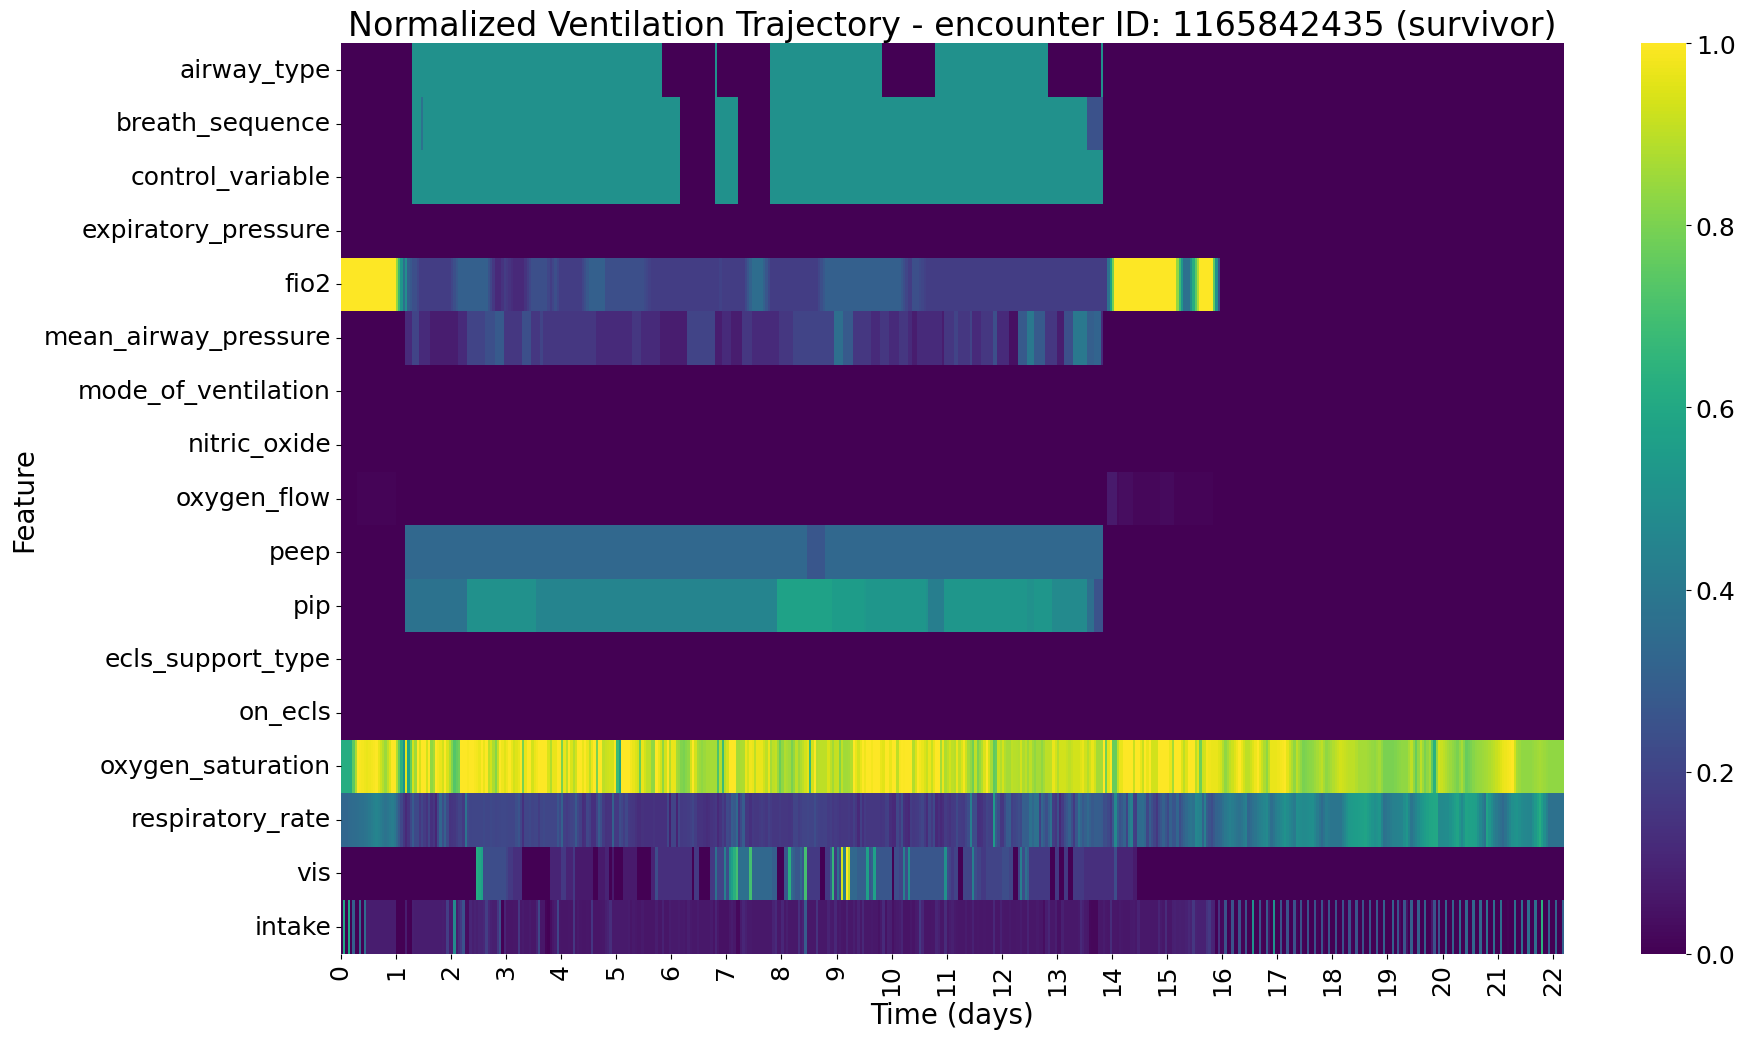

Using example encounter ID: 1165872386
Encounter ID 1165872386 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165872386_survivor.png


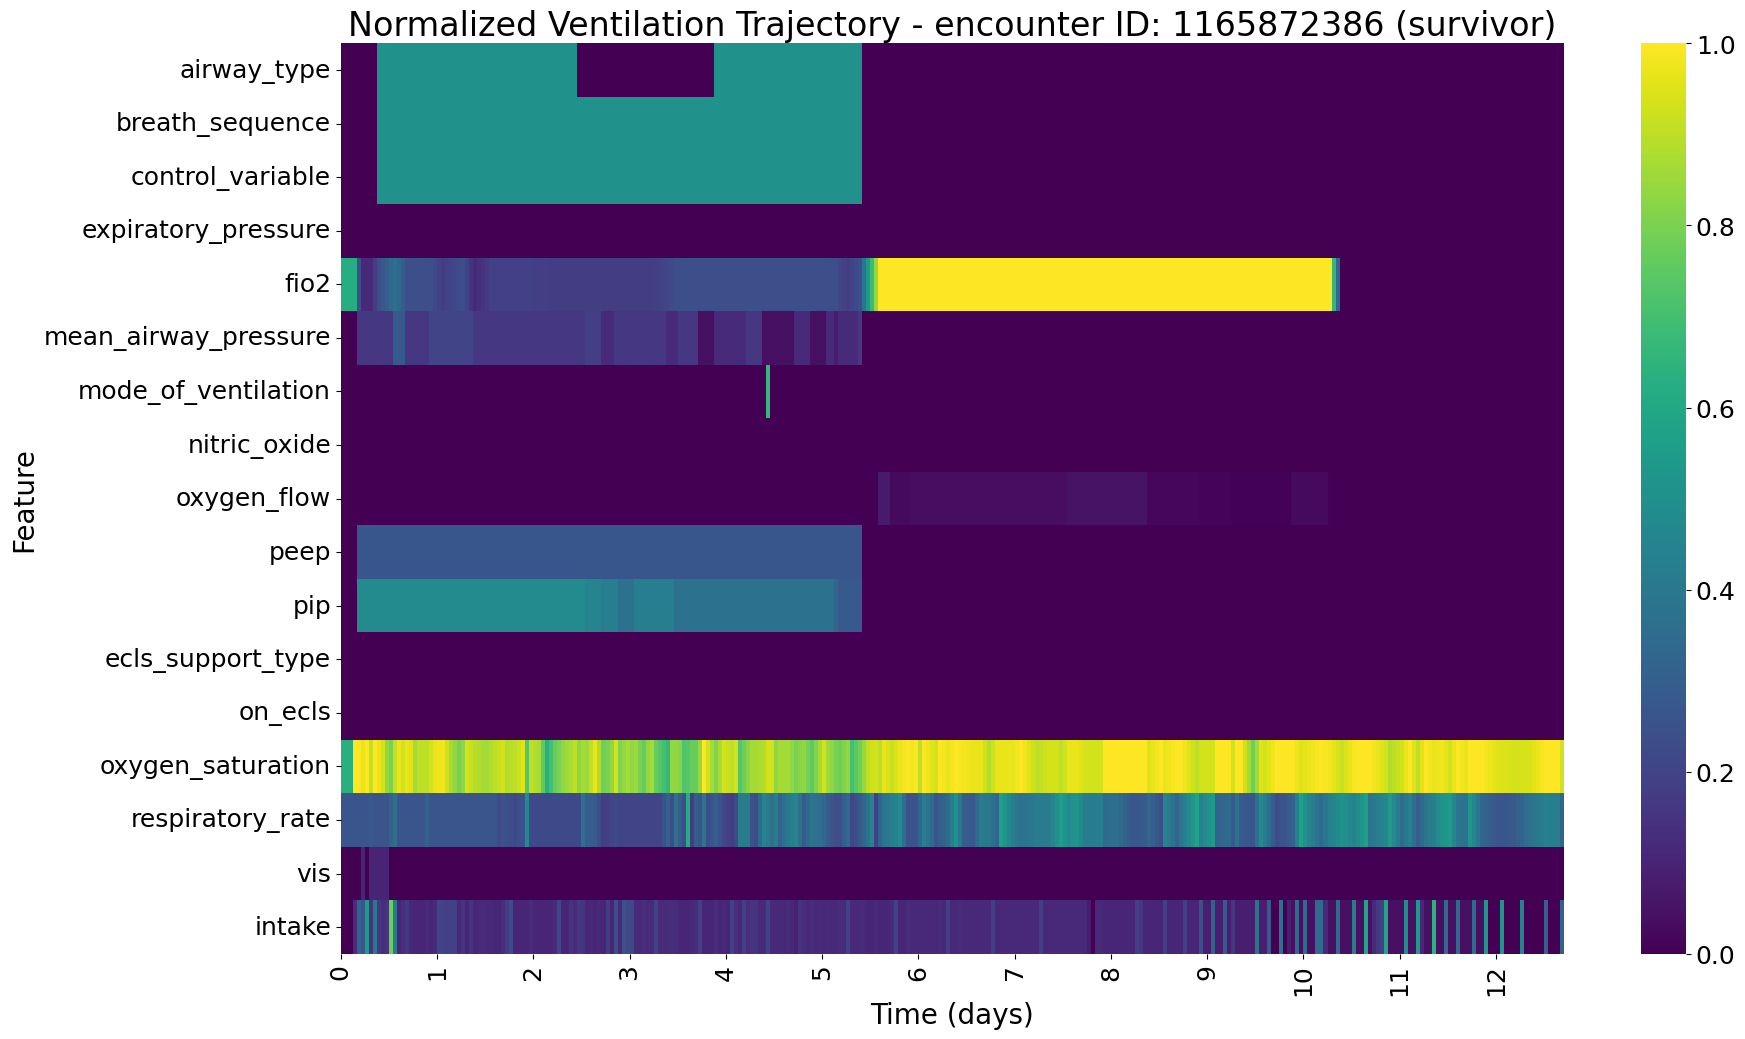

Using example encounter ID: 1165881806
Encounter ID 1165881806 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165881806_survivor.png


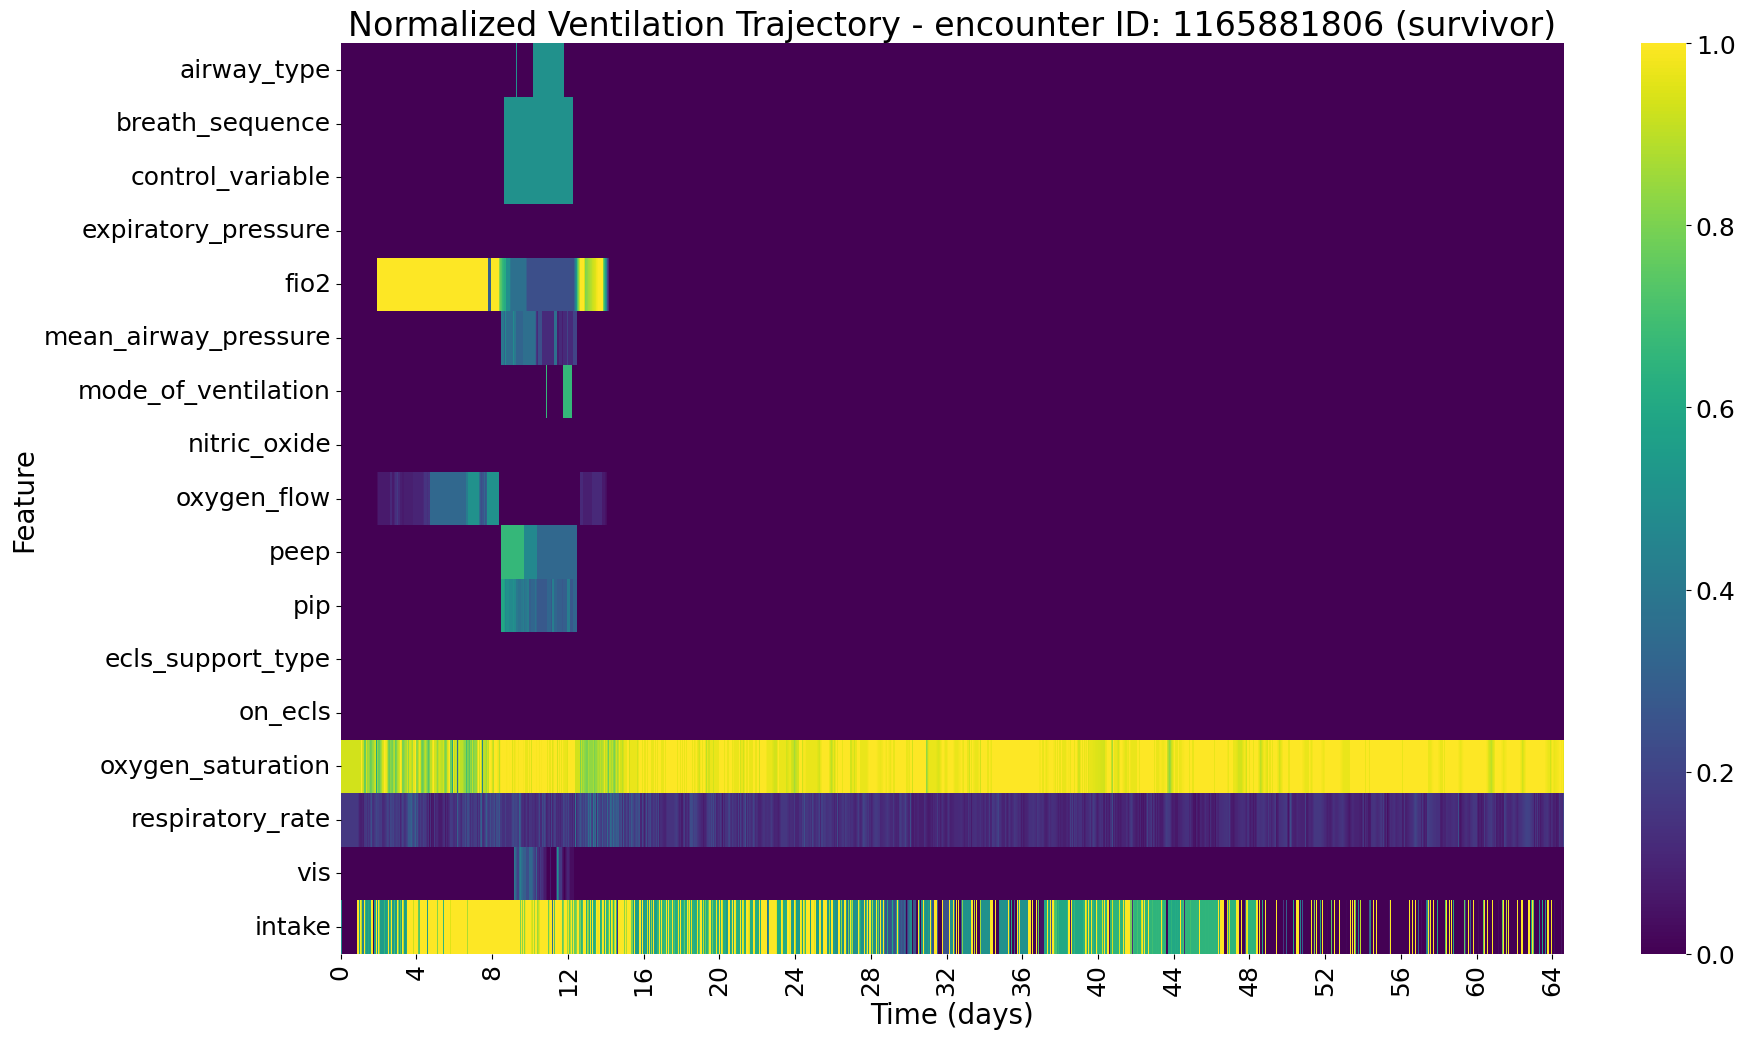

Using example encounter ID: 1165892898
Encounter ID 1165892898 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165892898_survivor.png


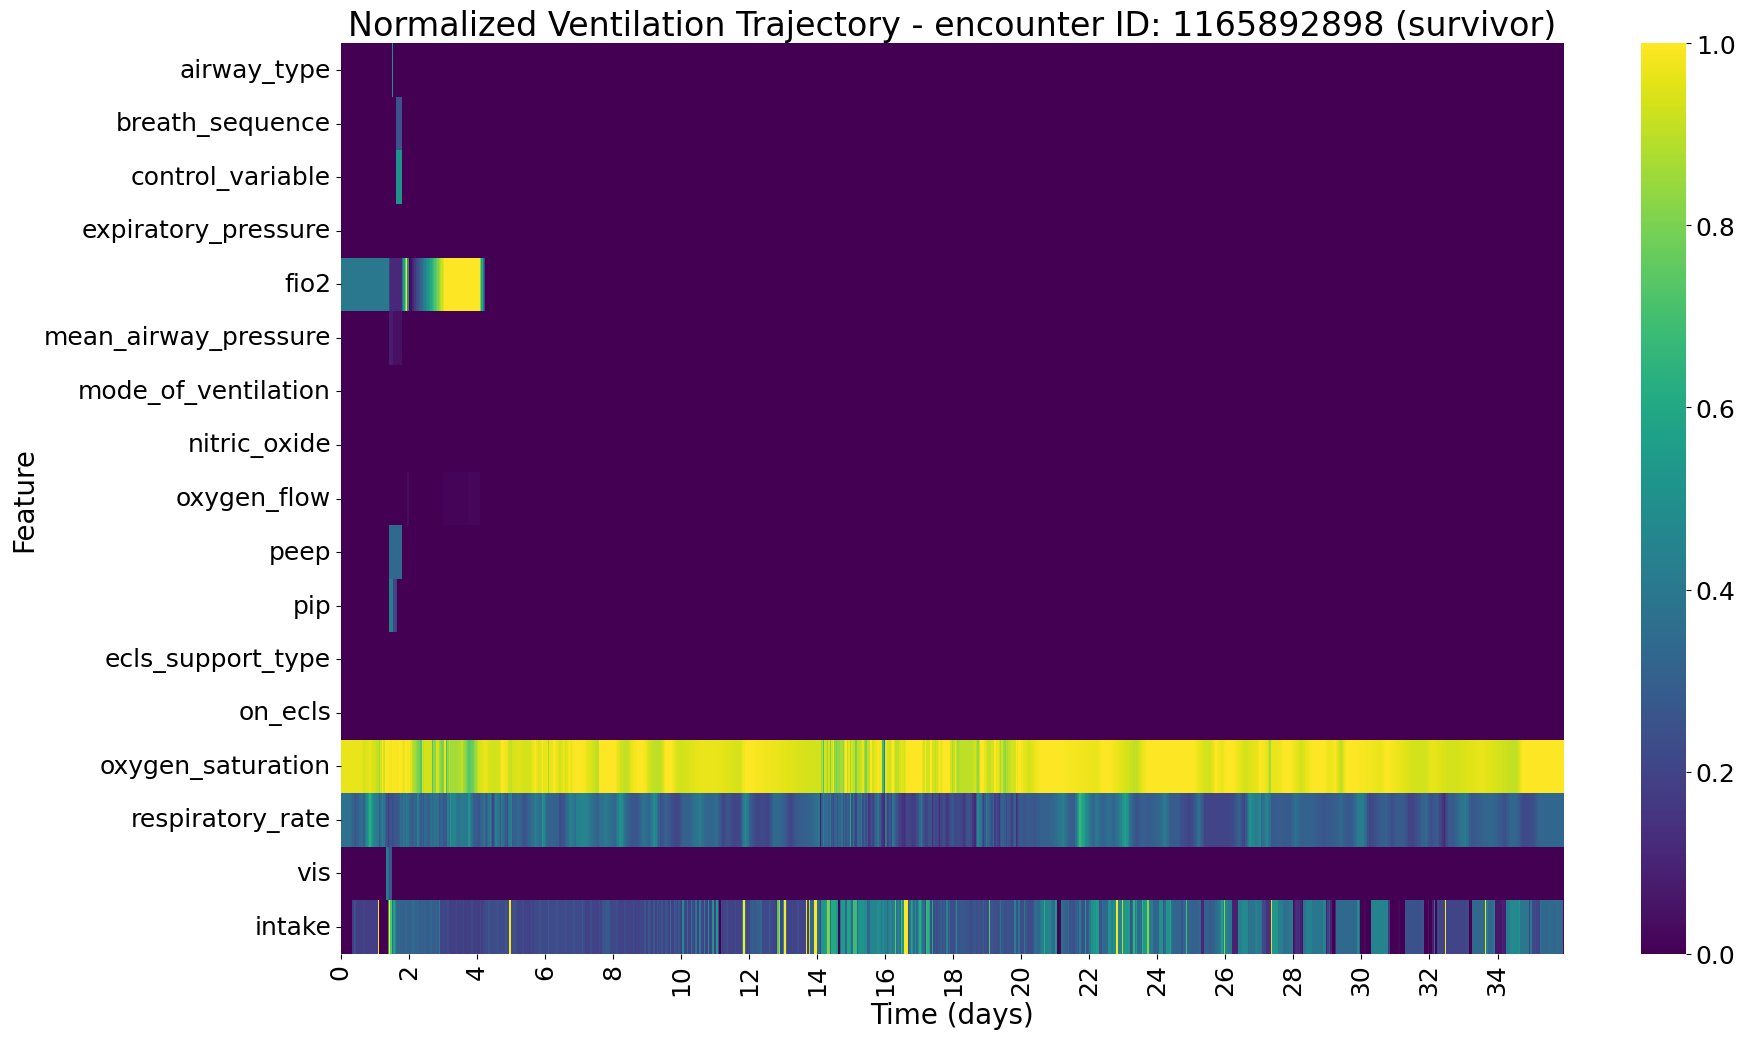

Using example encounter ID: 1165893034
Encounter ID 1165893034 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165893034_survivor.png


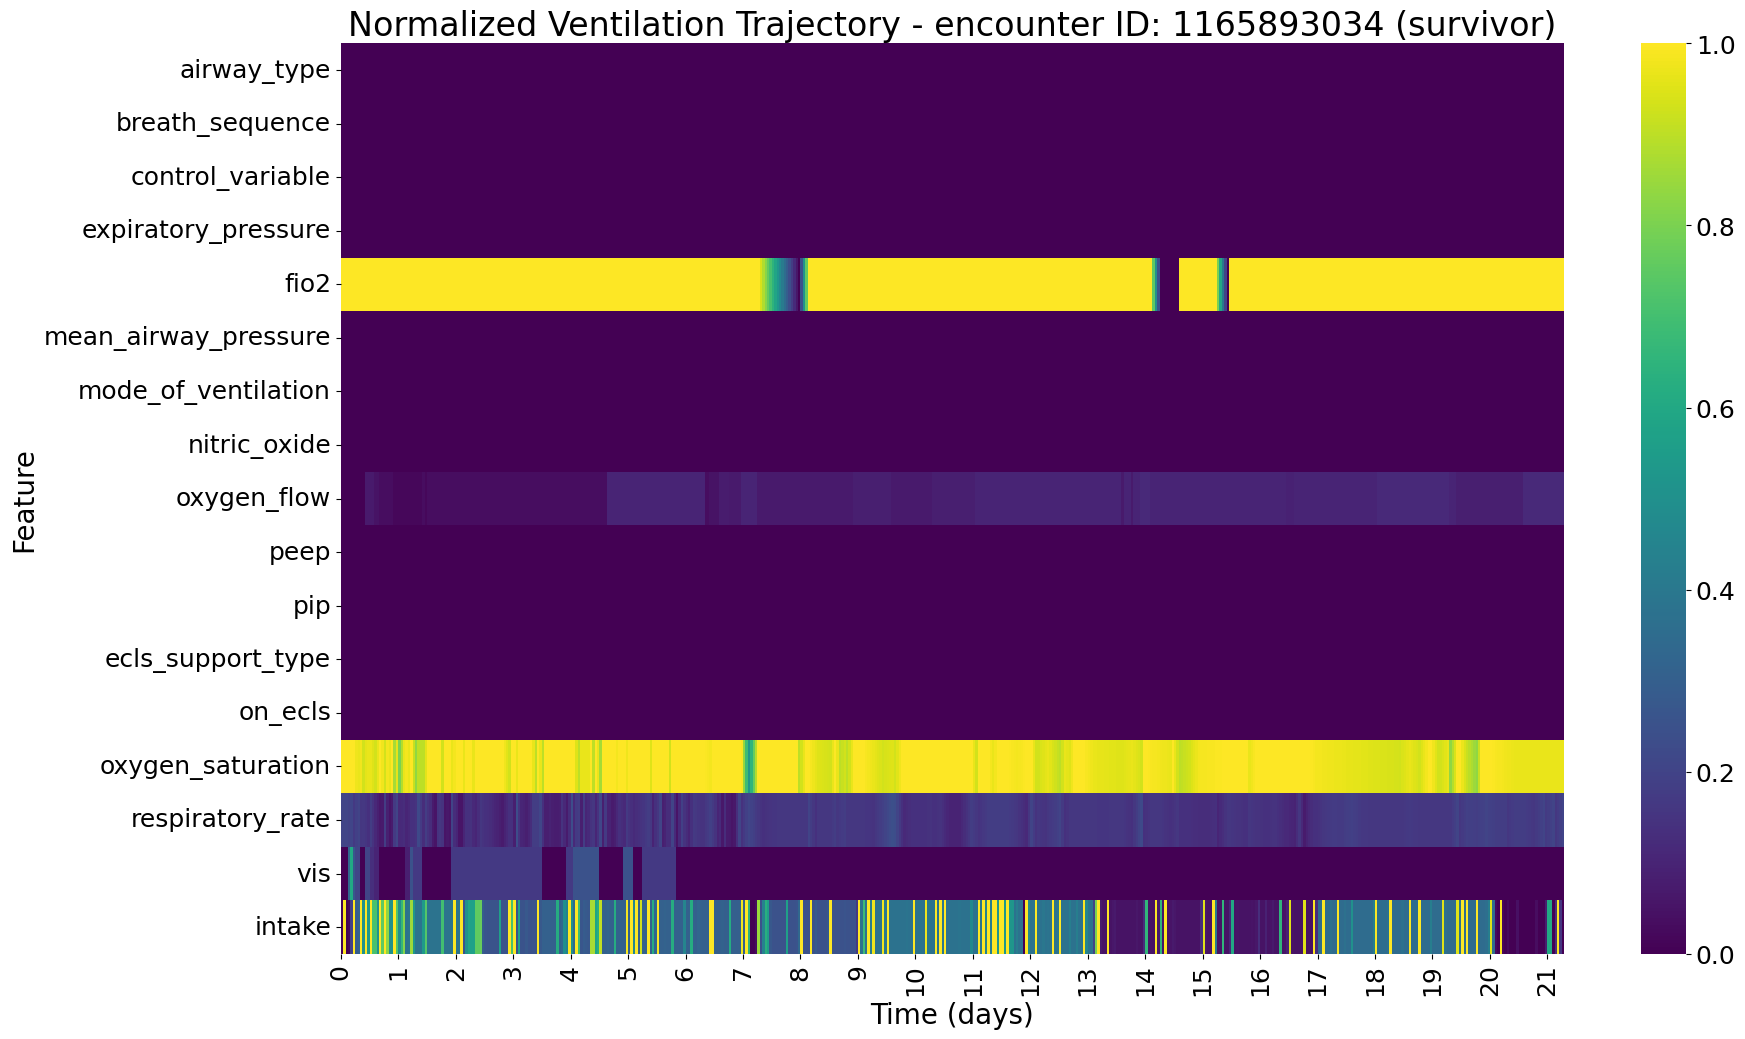

Using example encounter ID: 1165959412
Encounter ID 1165959412 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165959412_survivor.png


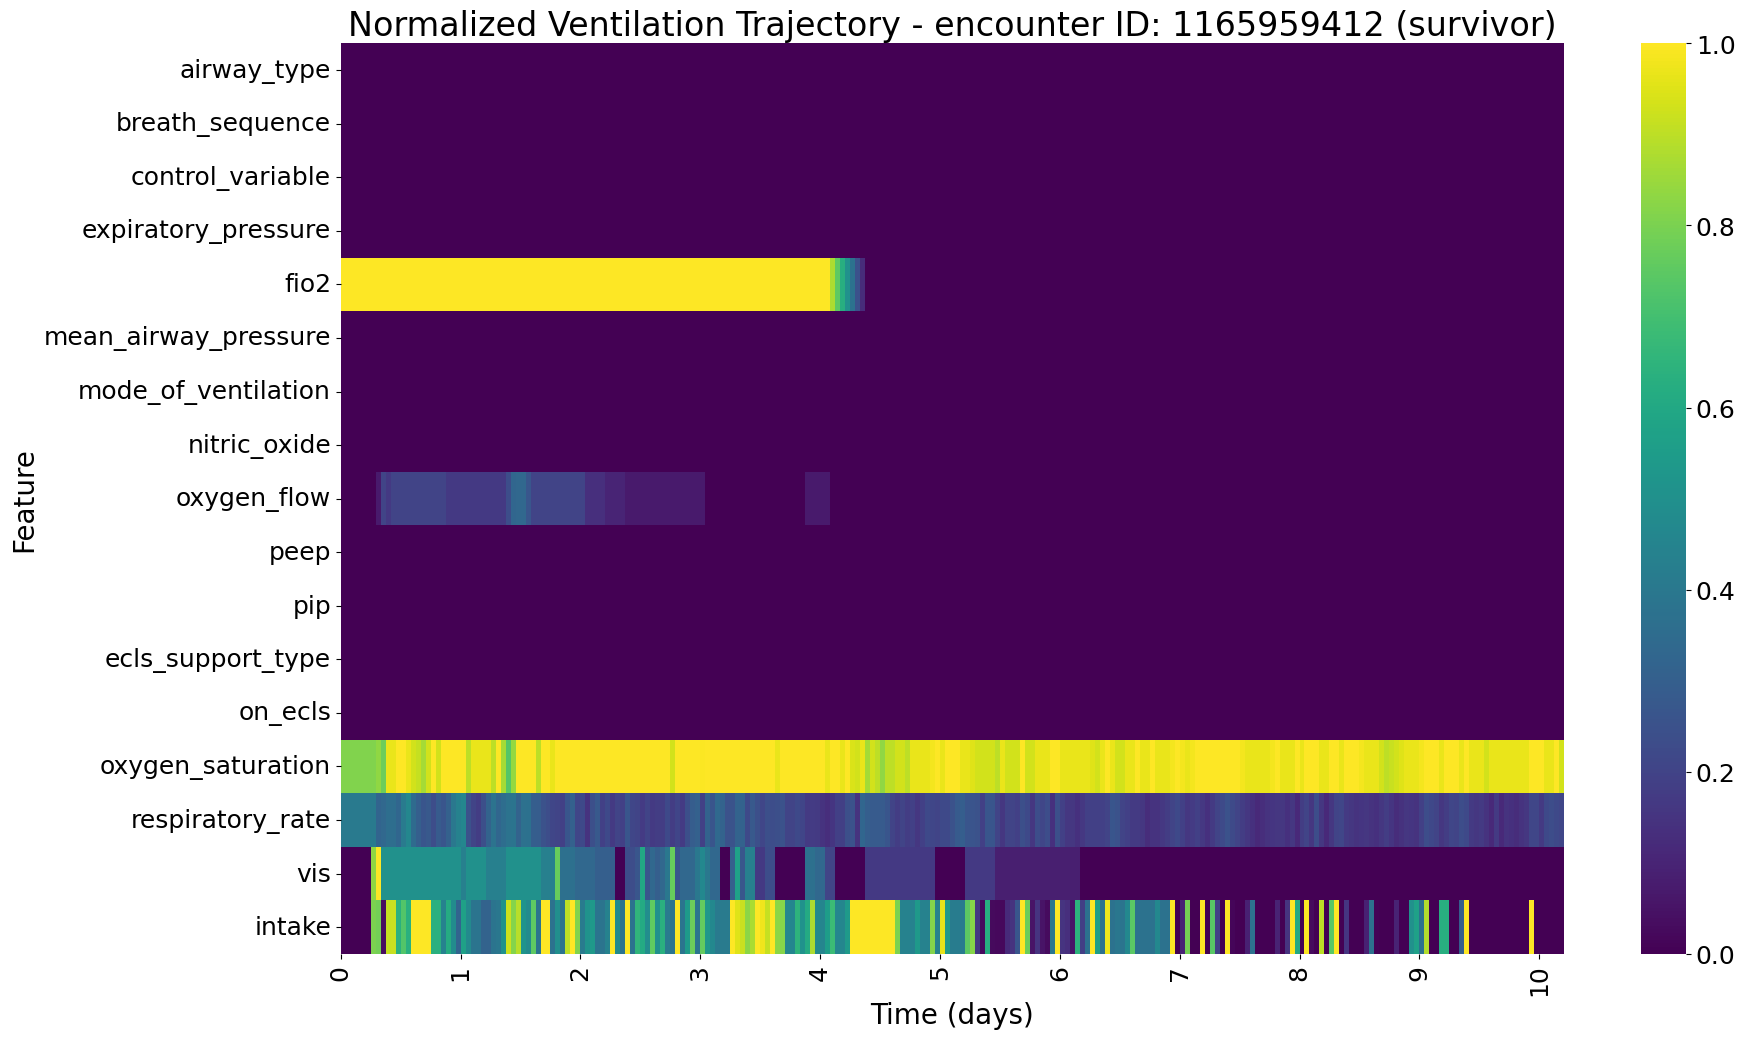

Using example encounter ID: 1165992819
Encounter ID 1165992819 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165992819_survivor.png


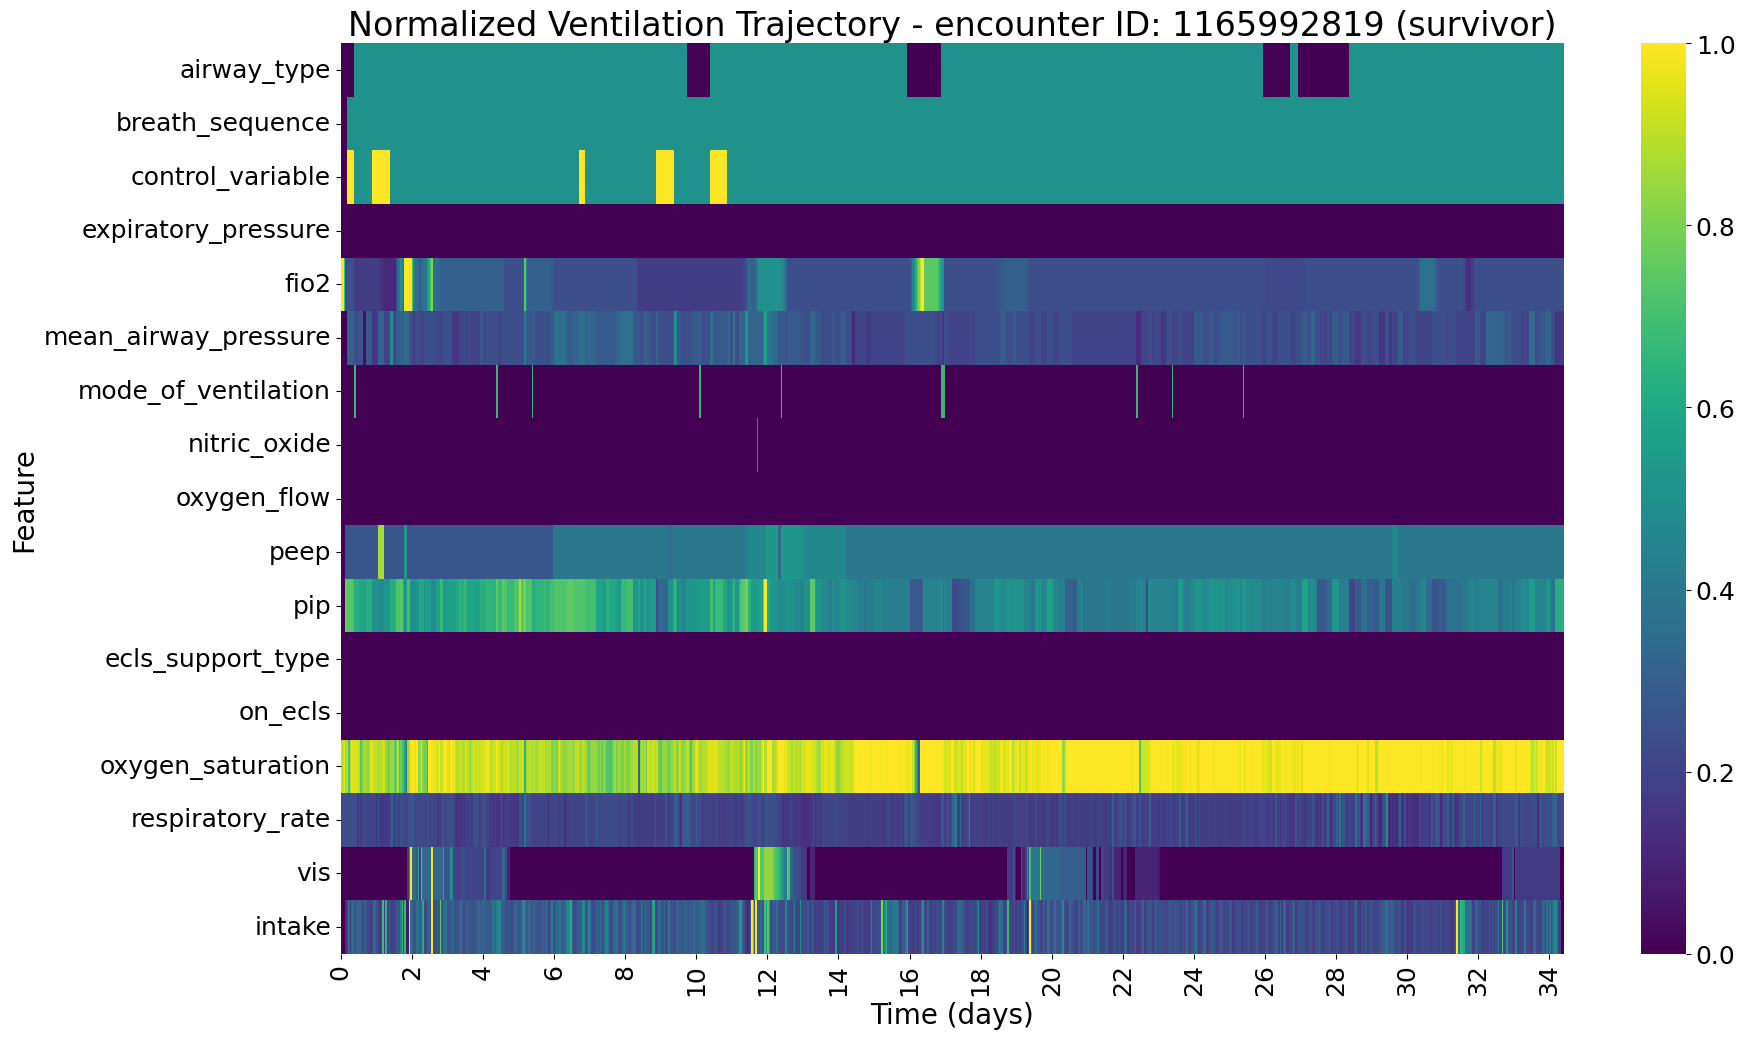

Using example encounter ID: 1166016271
Encounter ID 1166016271 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166016271_survivor.png


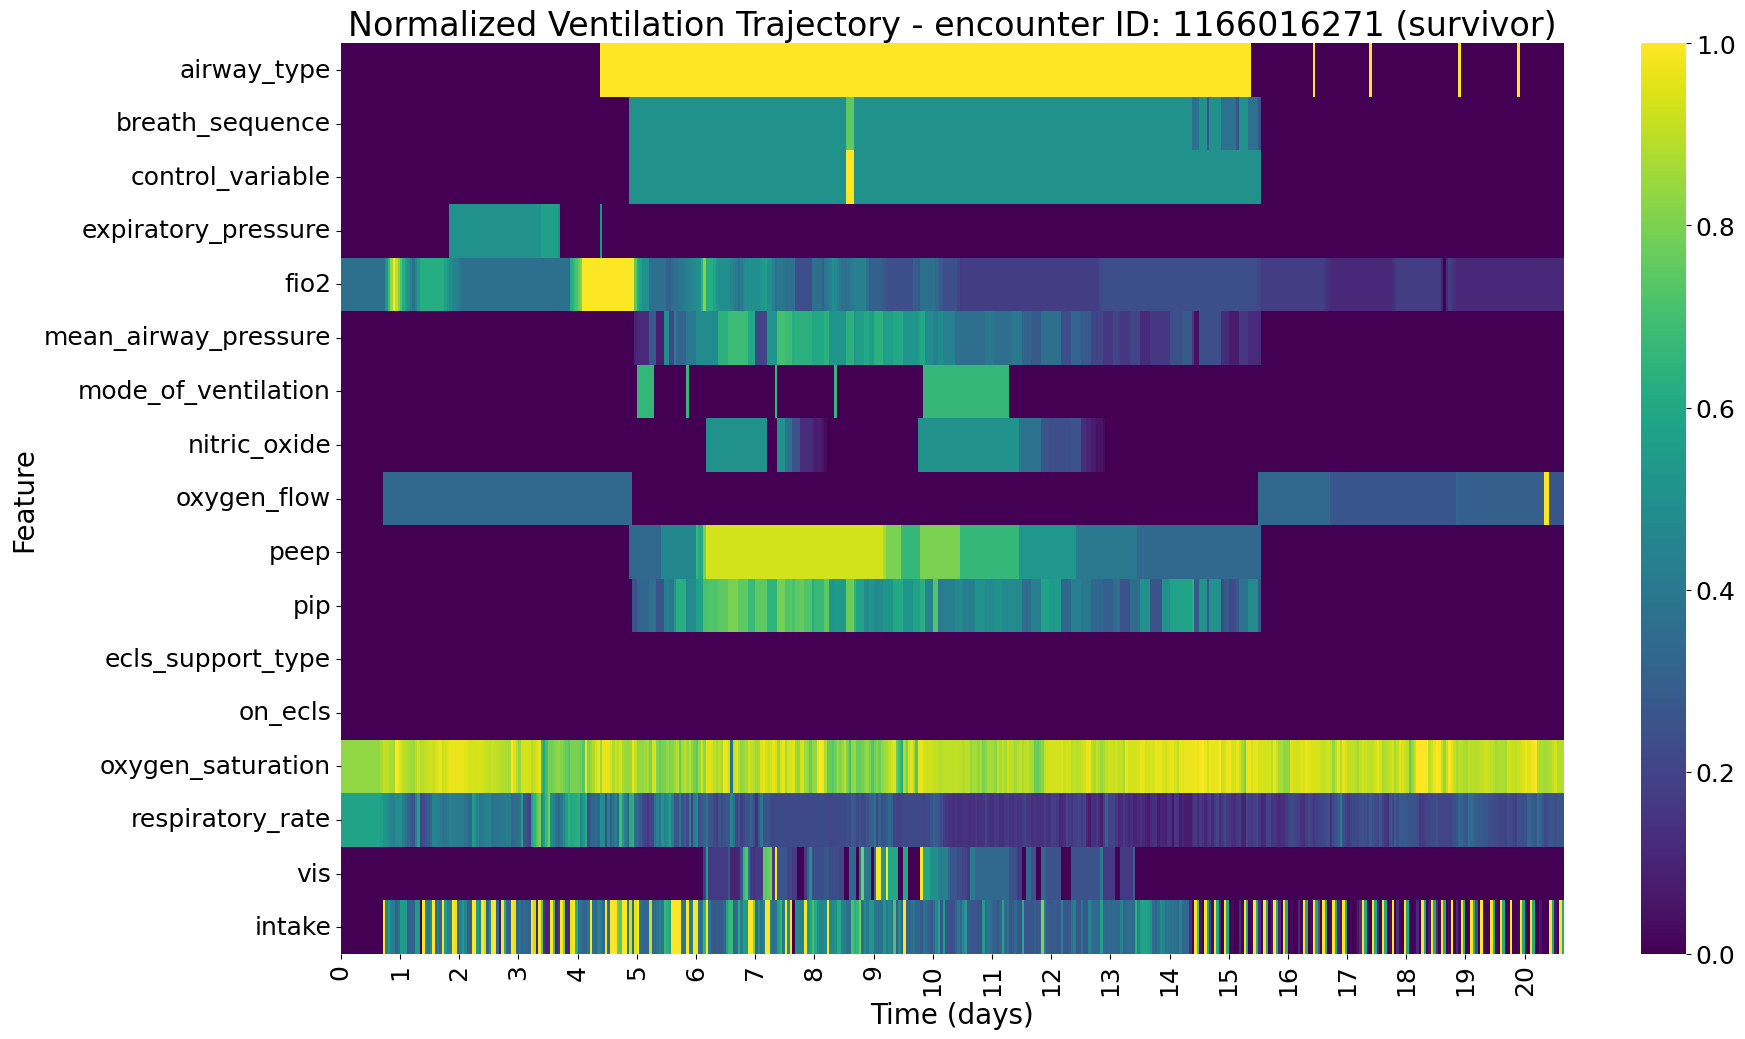

Using example encounter ID: 1166081806
Encounter ID 1166081806 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166081806_survivor.png


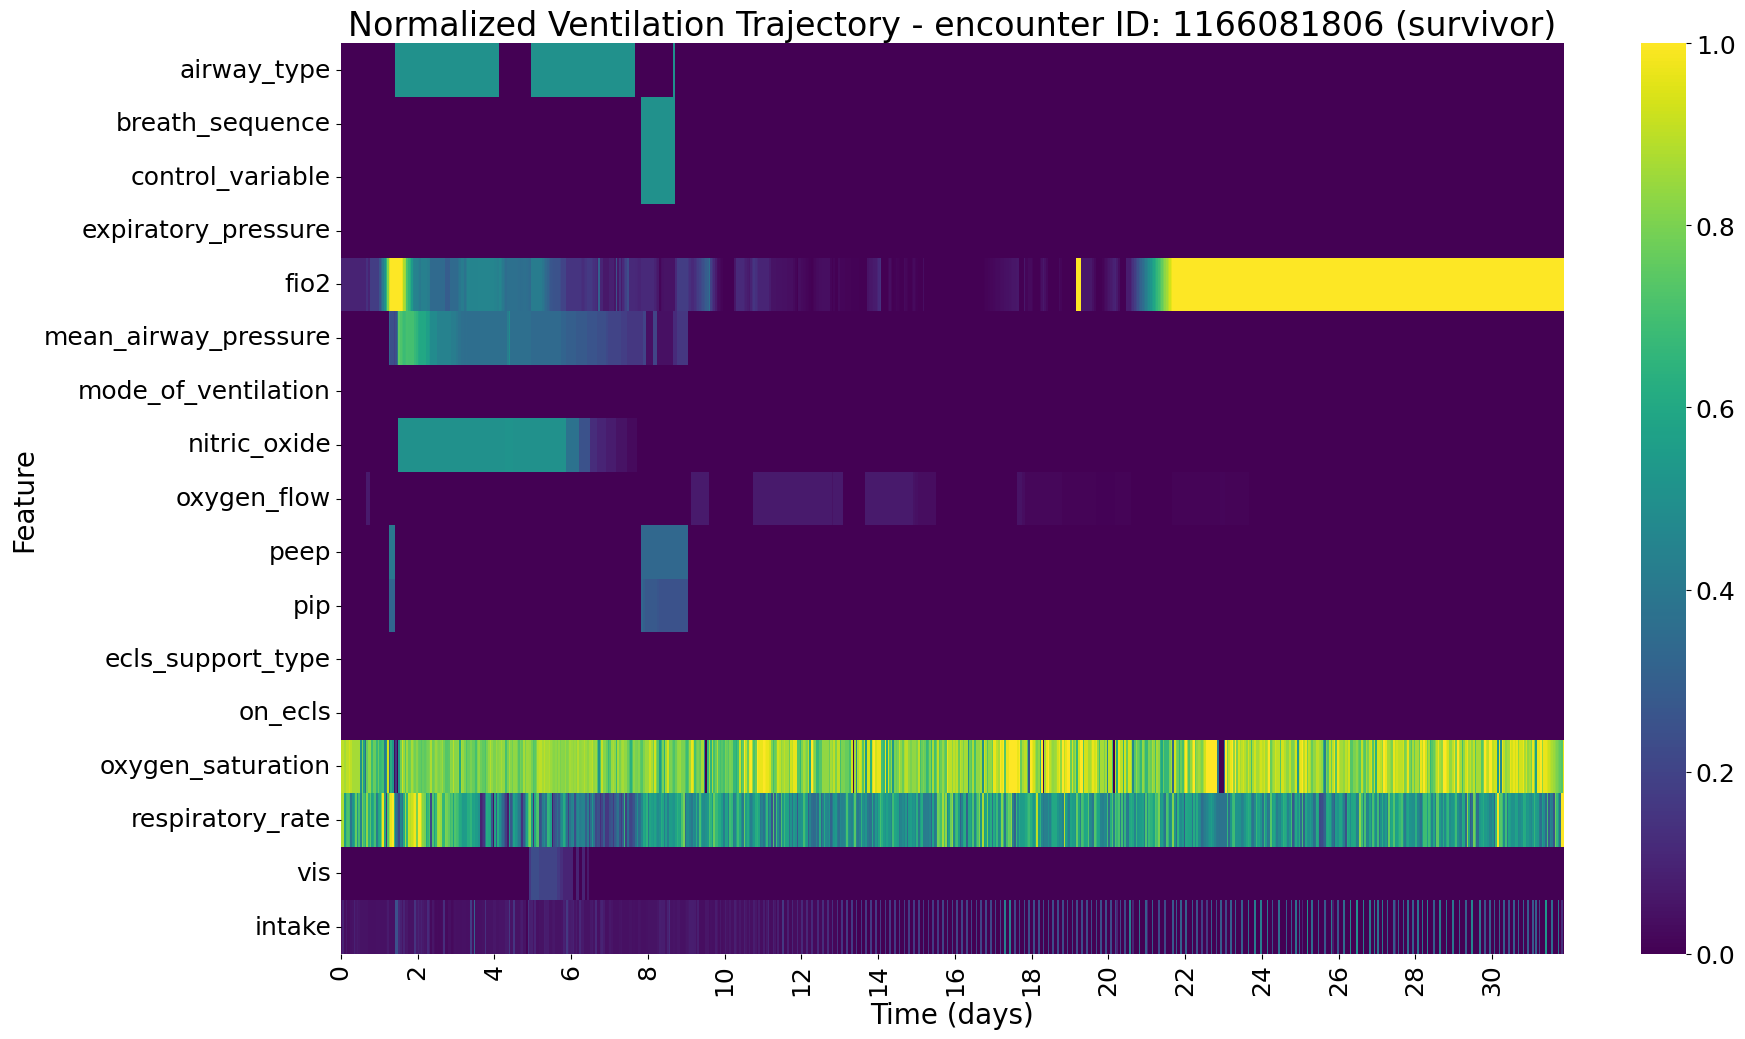

Using example encounter ID: 1166182411
Encounter ID 1166182411 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166182411_survivor.png


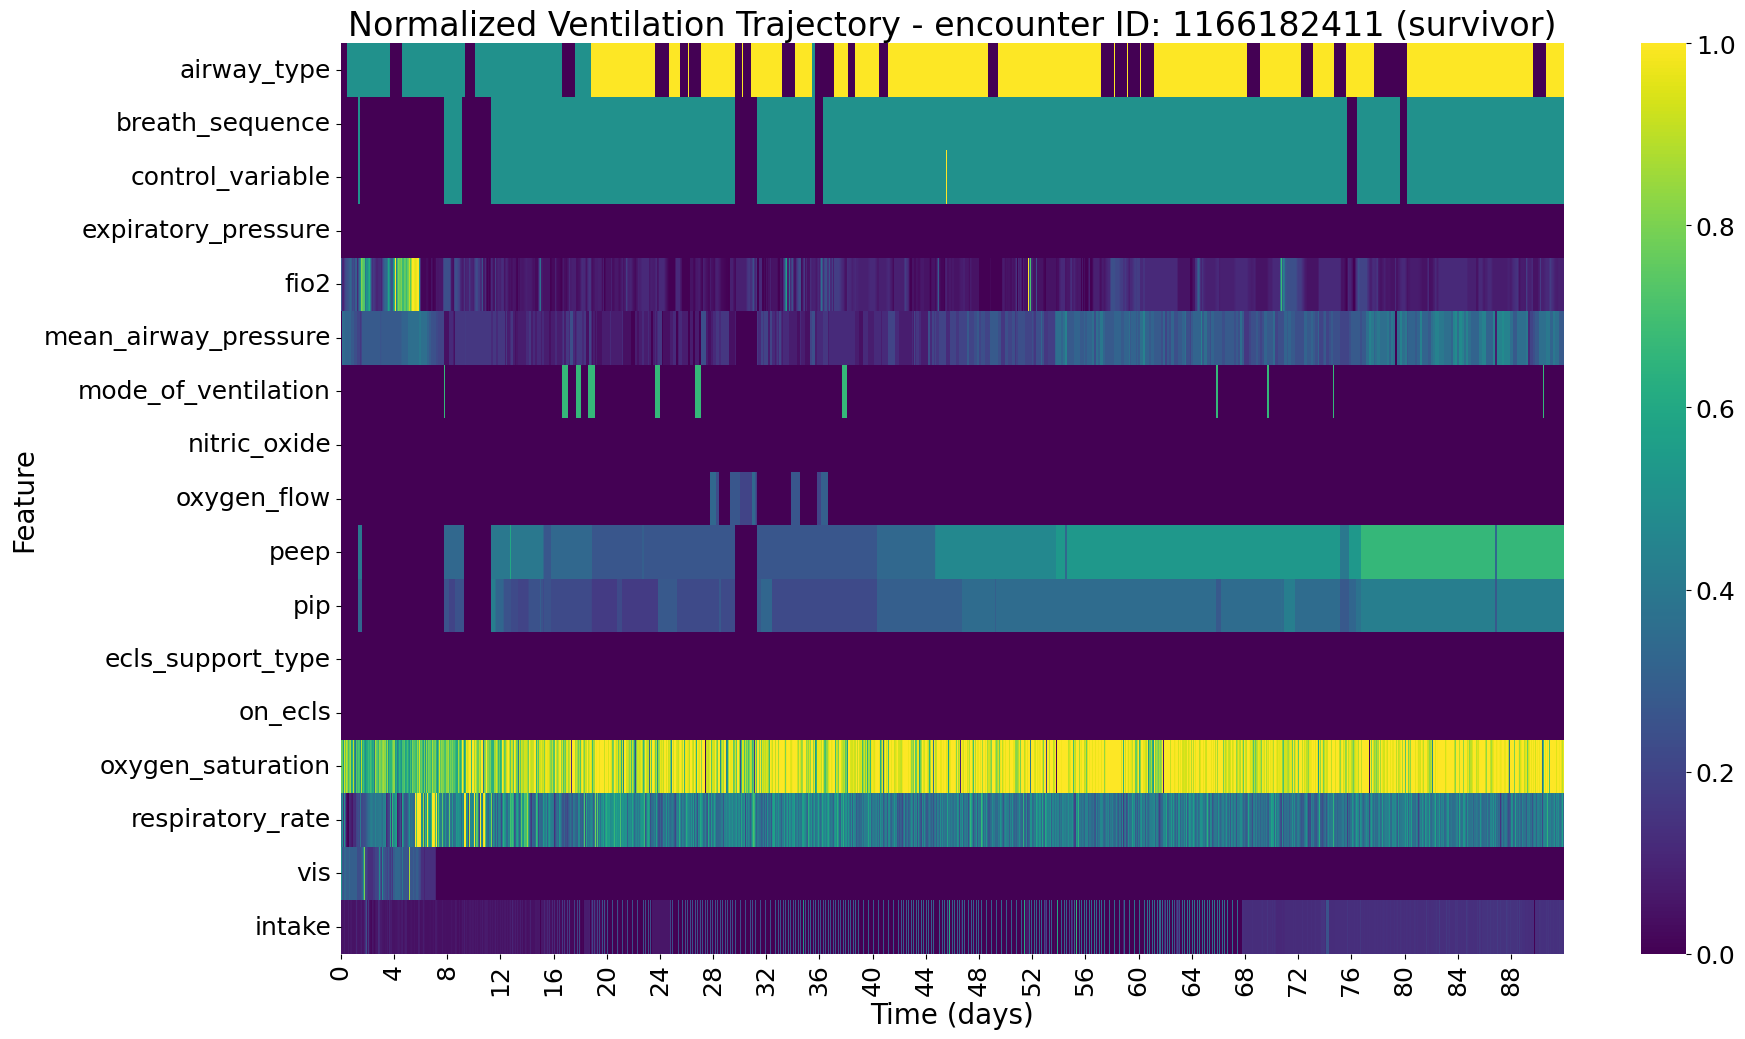

Using example encounter ID: 1166197098
Encounter ID 1166197098 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166197098_survivor.png


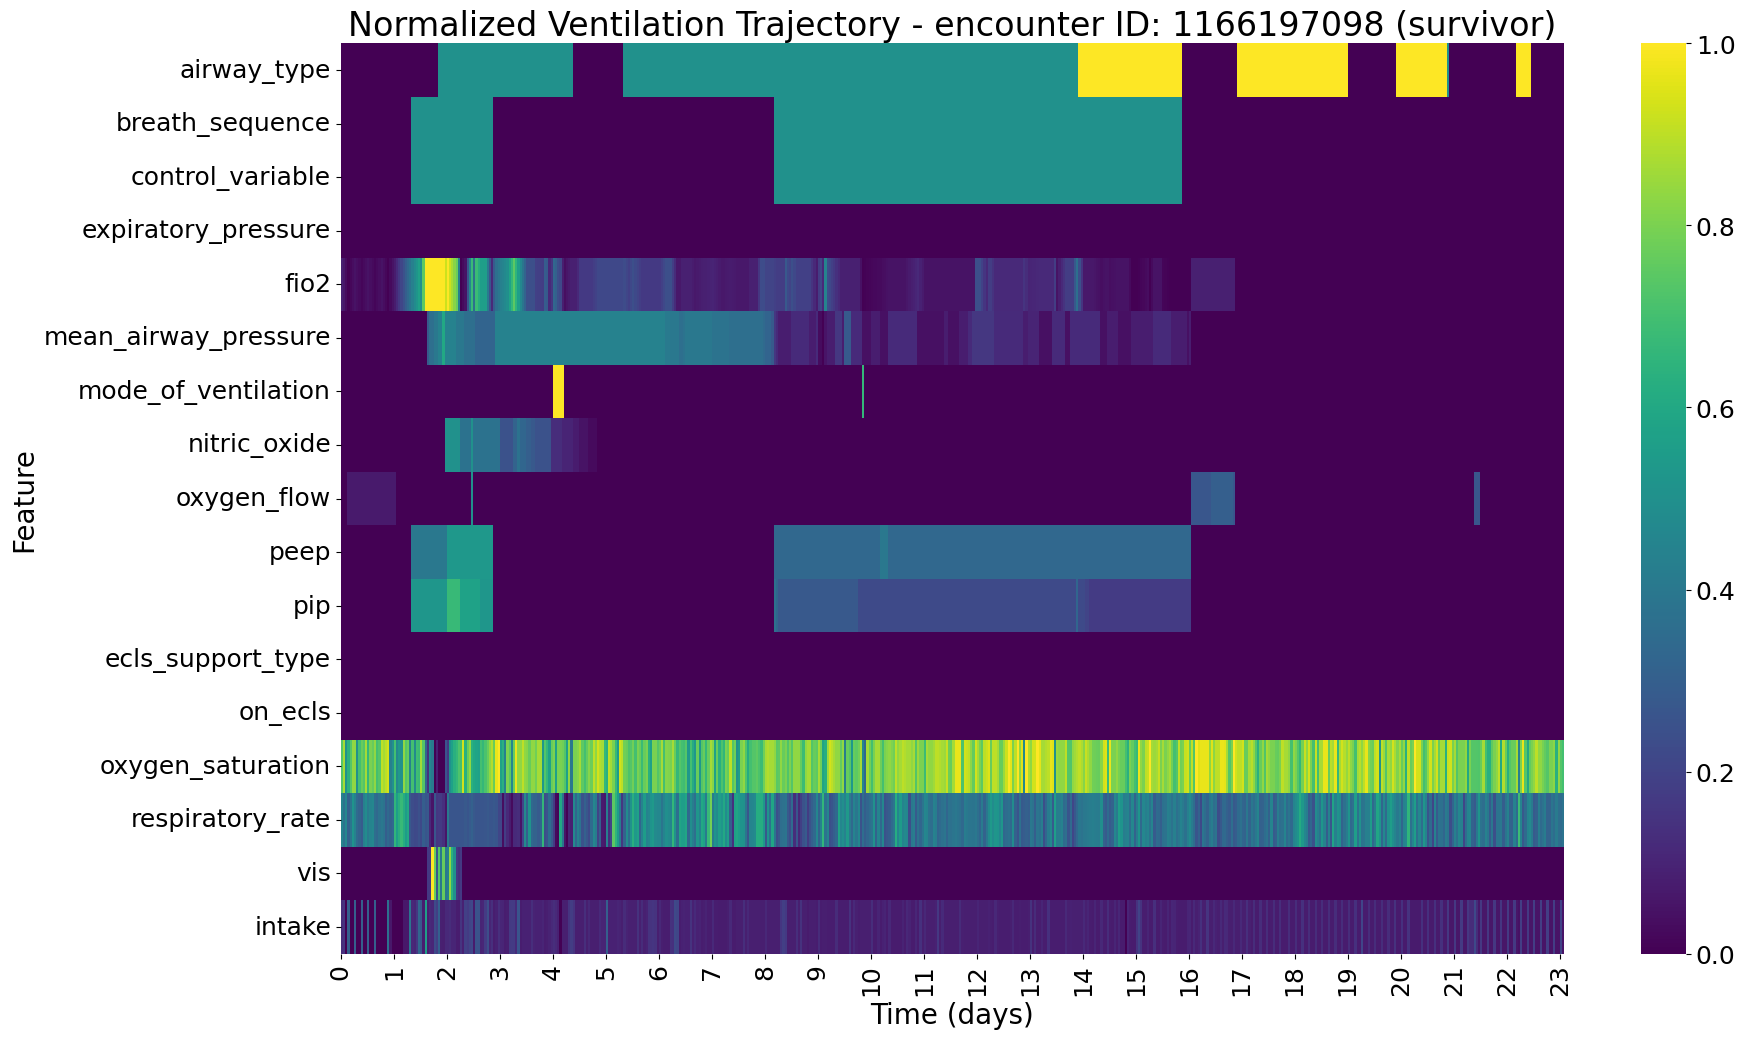

Using example encounter ID: 1166197537
Encounter ID 1166197537 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166197537_survivor.png


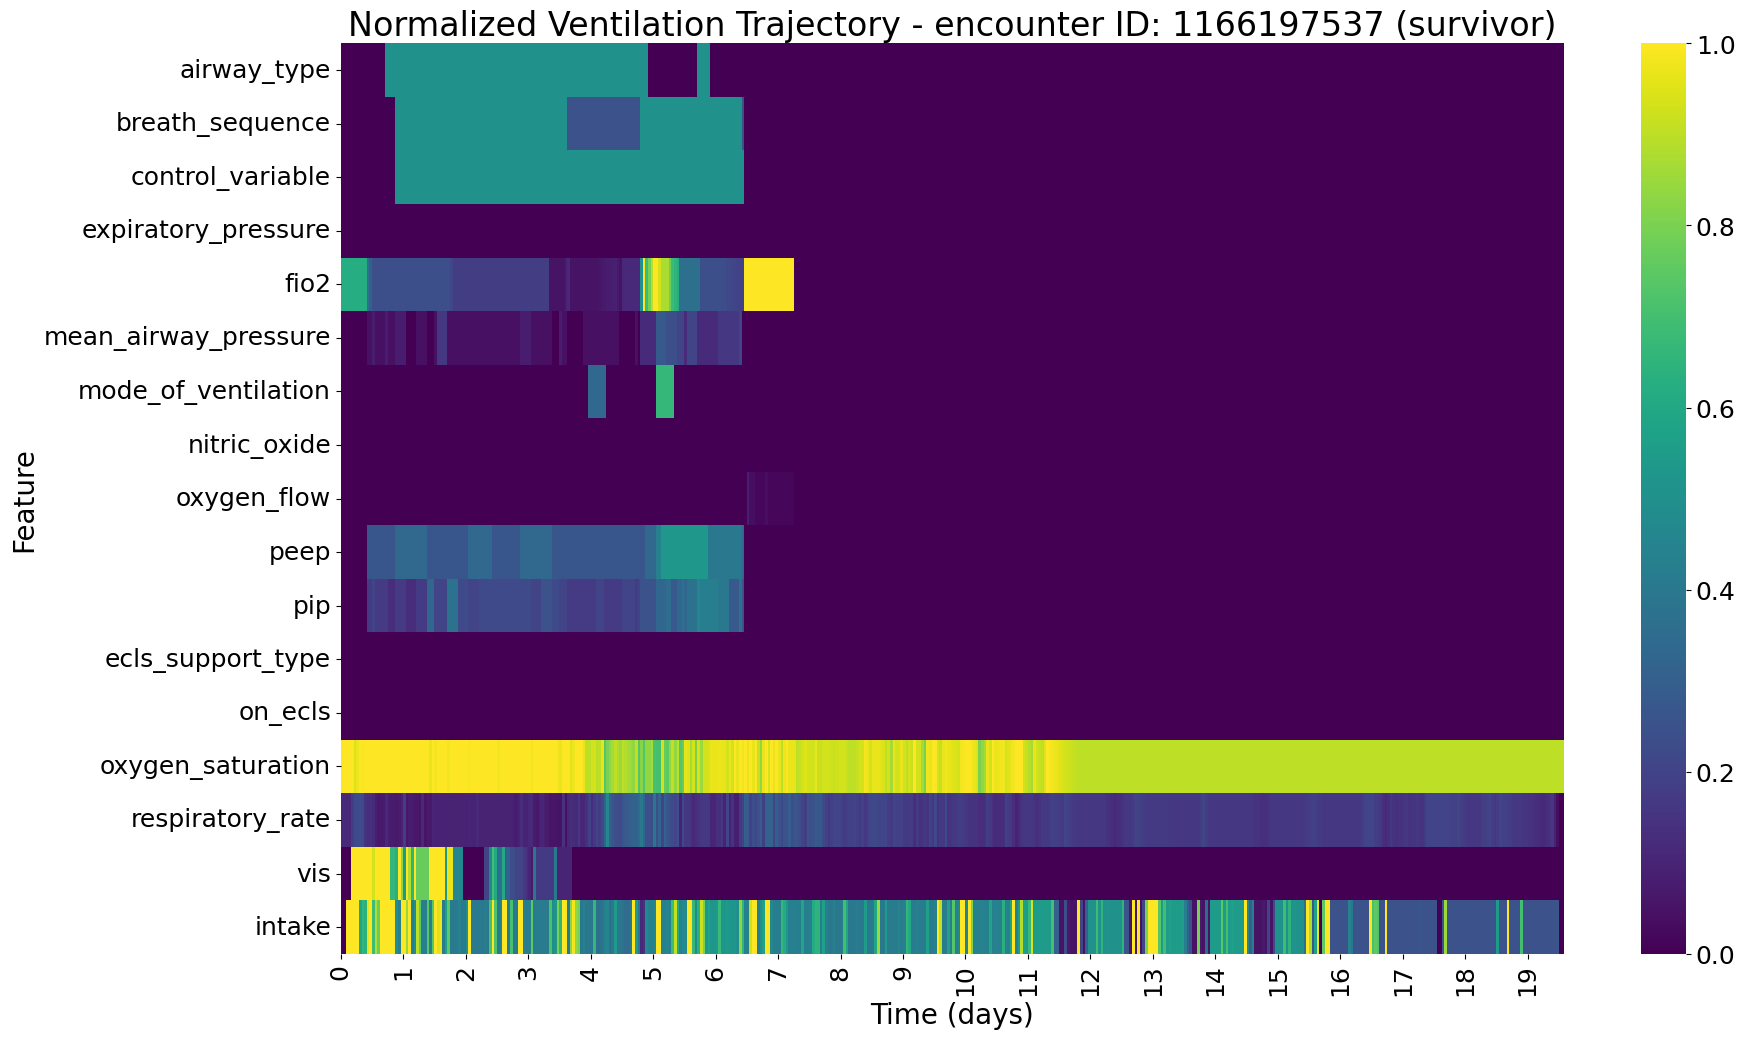

Using example encounter ID: 1166213245
Encounter ID 1166213245 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166213245_survivor.png


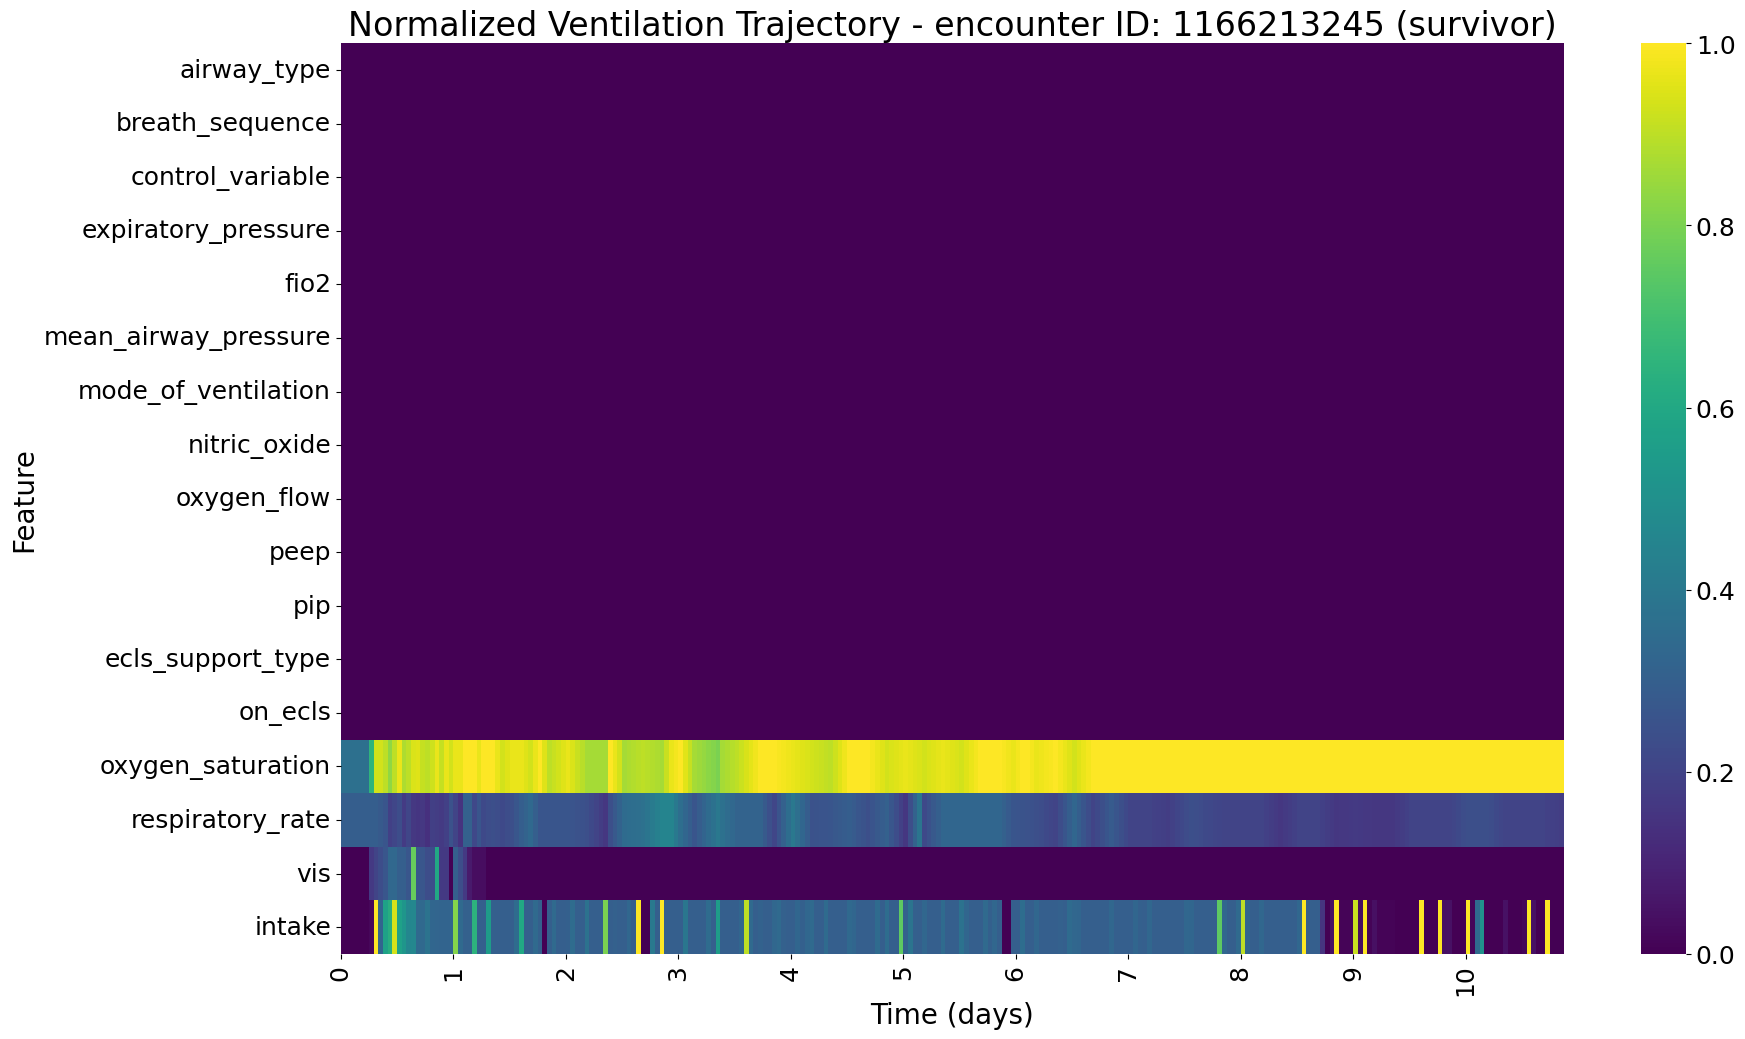

Using example encounter ID: 1166218428
Encounter ID 1166218428 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166218428_survivor.png


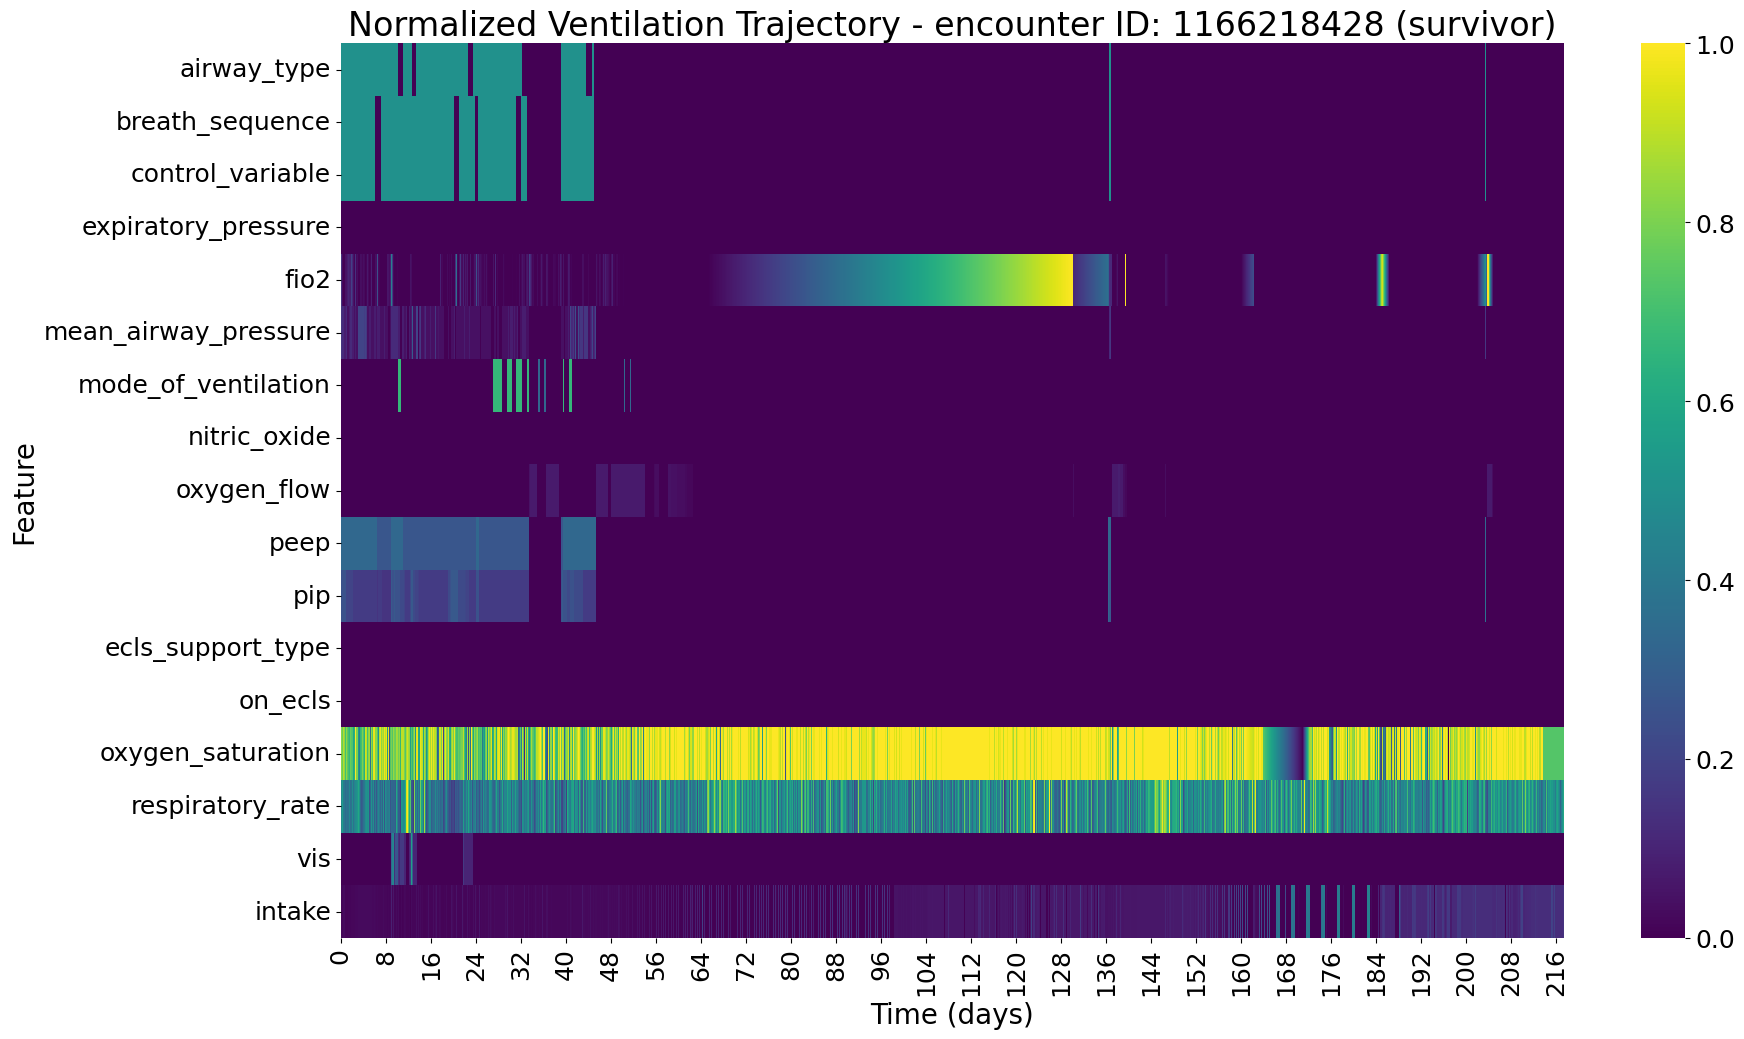

Using example encounter ID: 1166237657
Encounter ID 1166237657 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166237657_survivor.png


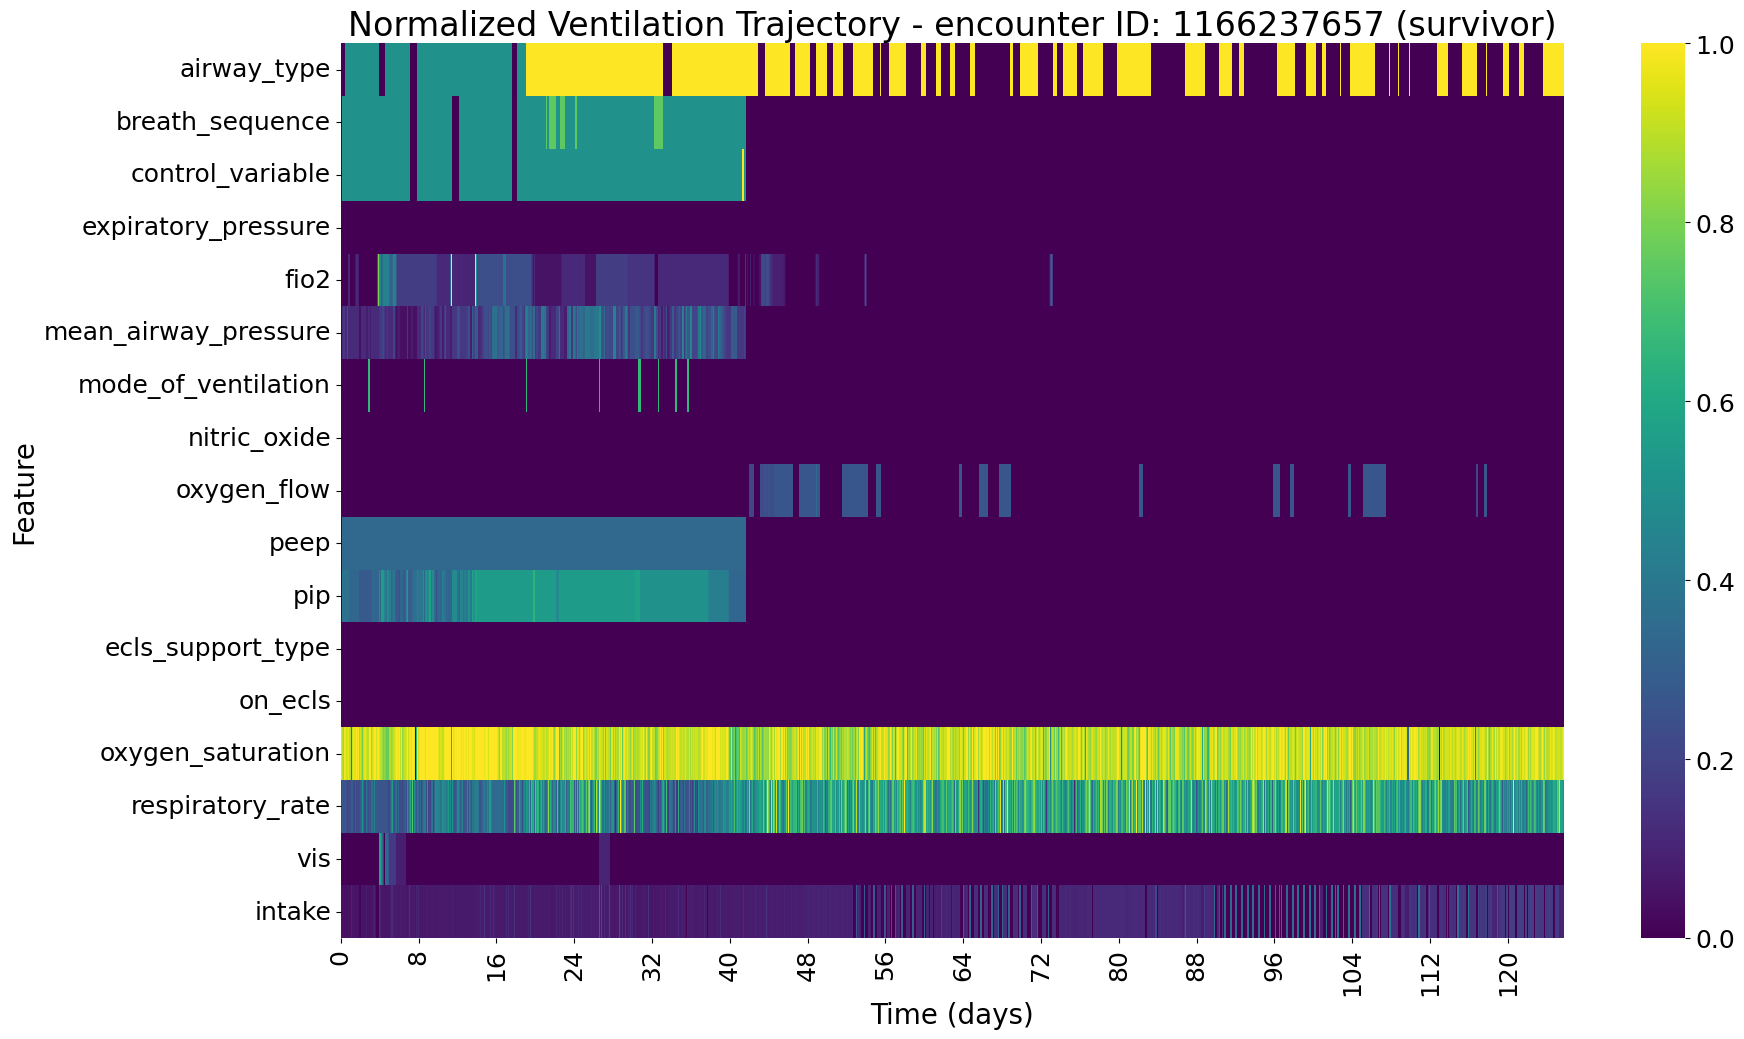

Using example encounter ID: 1166259717
Encounter ID 1166259717 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166259717_survivor.png


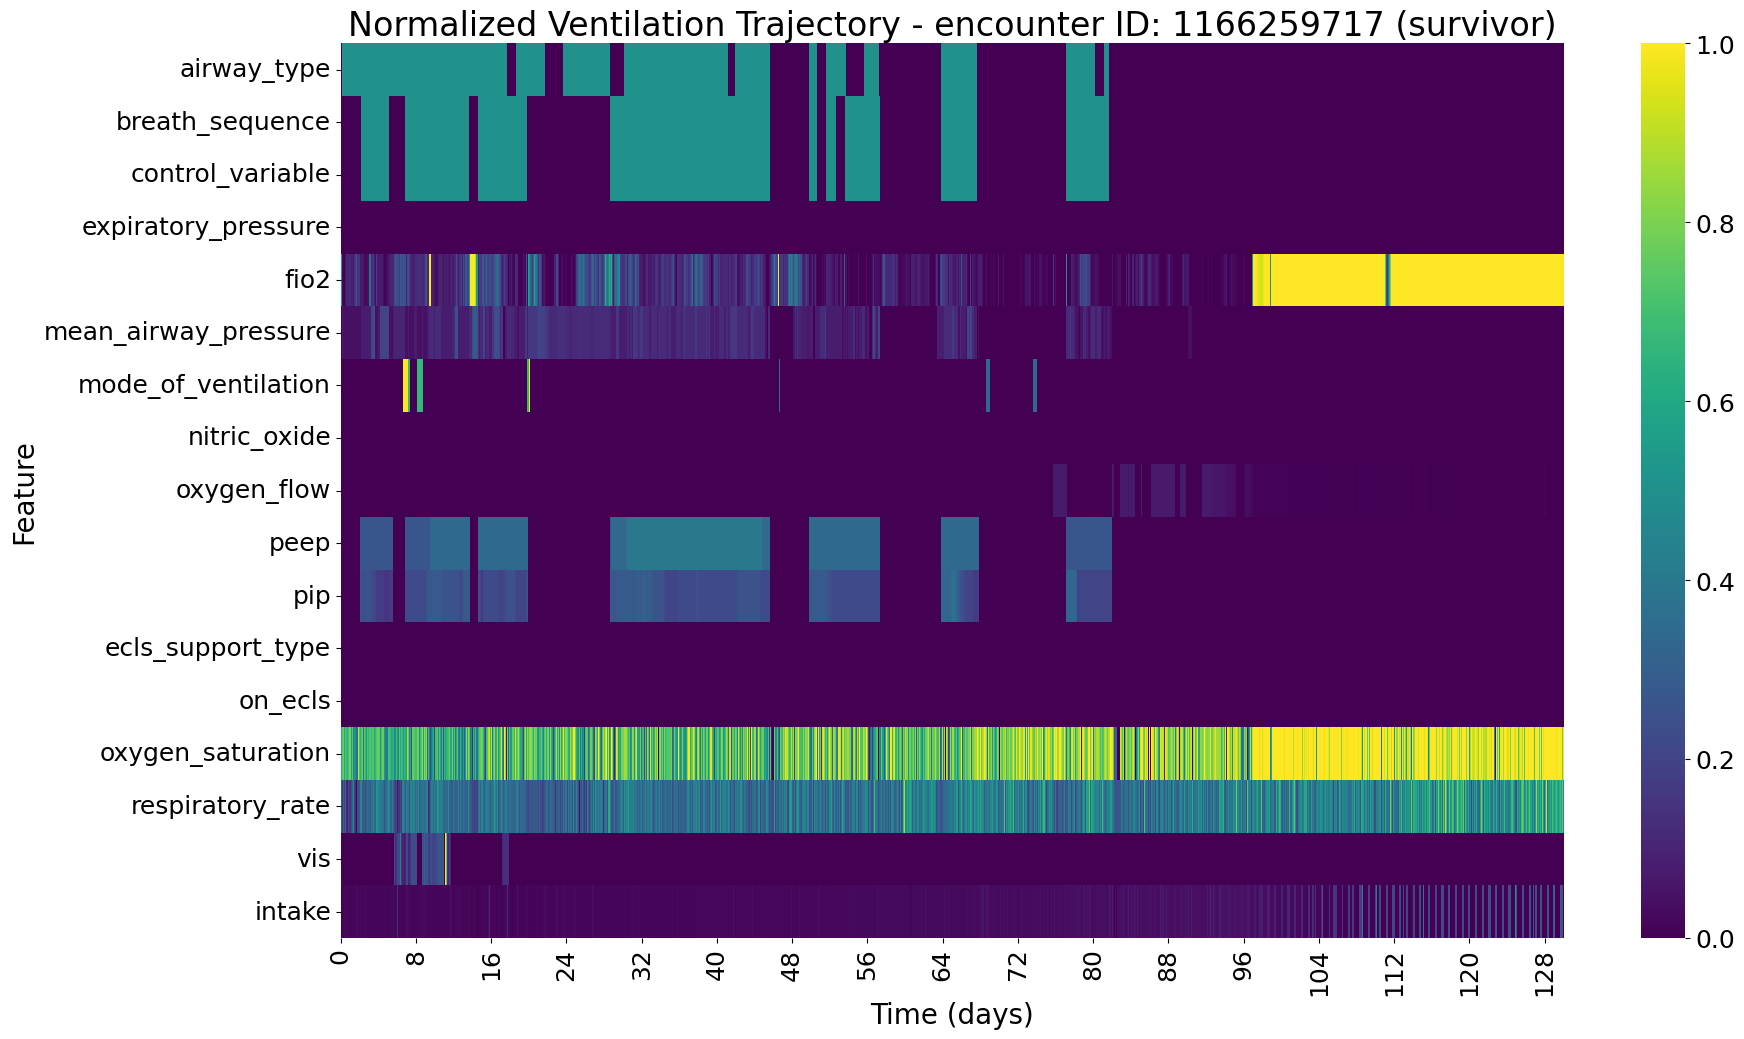

Using example encounter ID: 1166264194
Encounter ID 1166264194 is a survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166264194_survivor.png


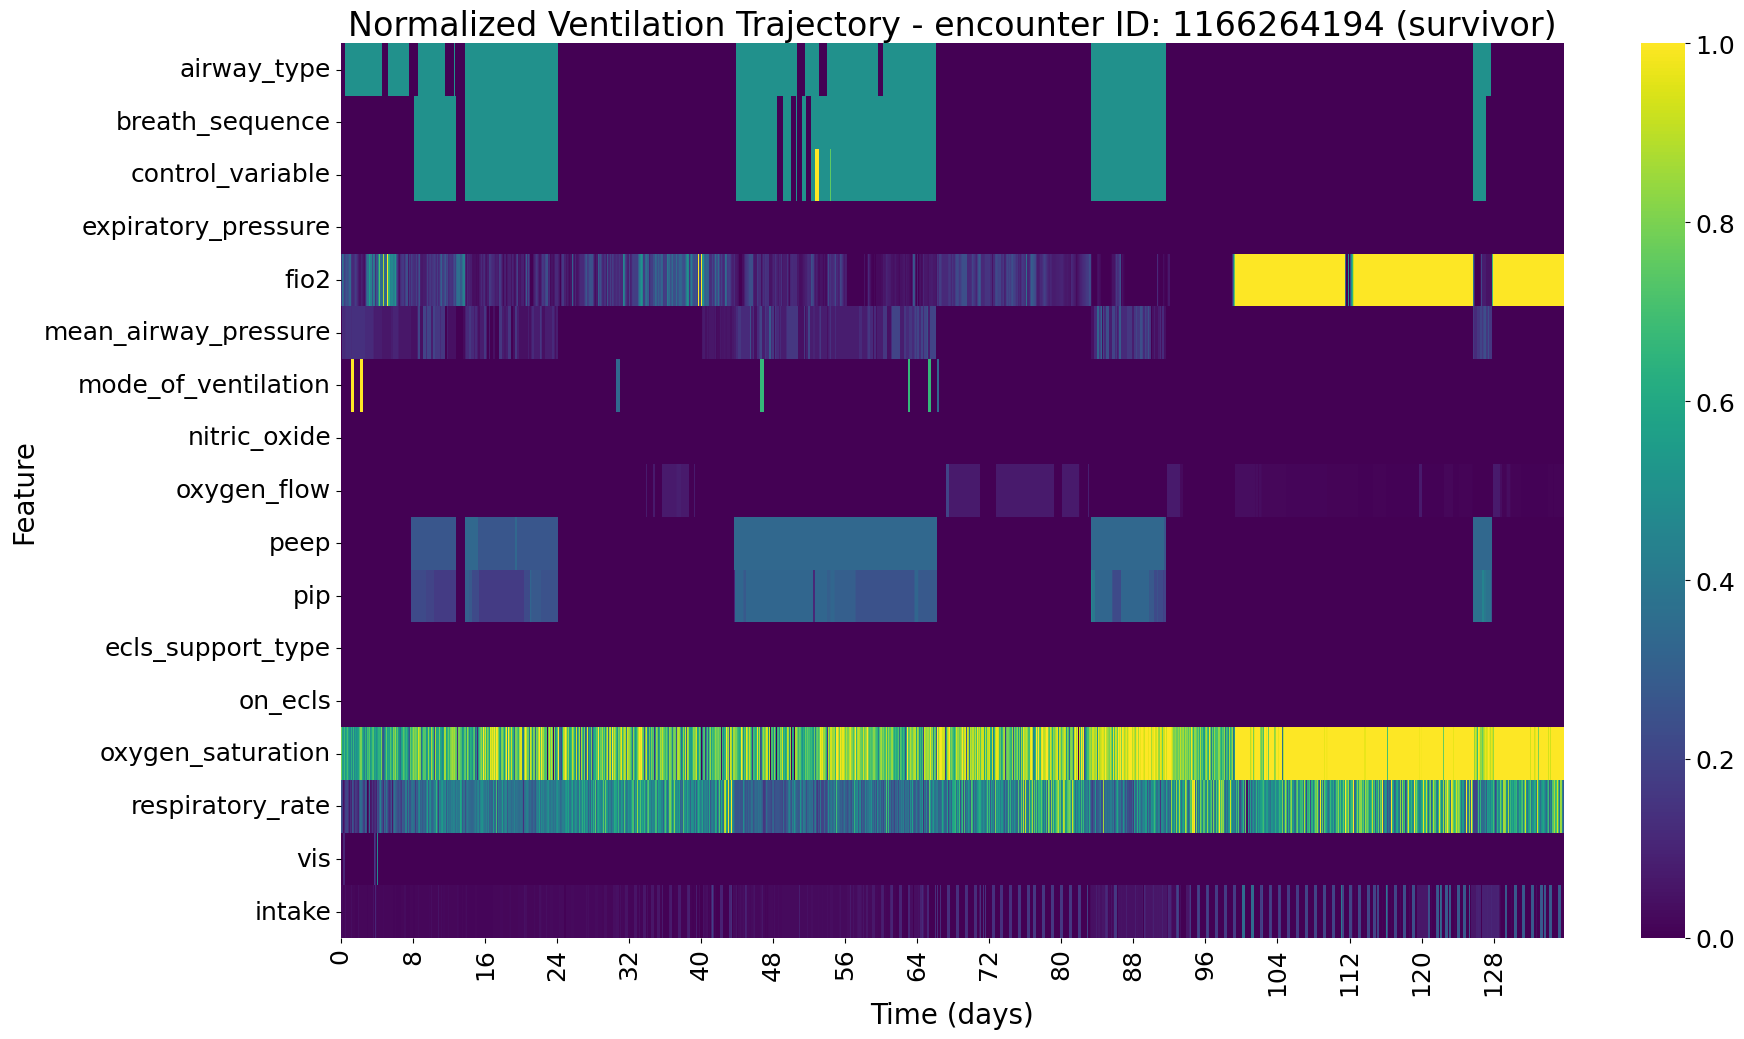

In [59]:
# plot 20 survivor encounters with non-zero VIS
survive_encounter_id = 0
for _ in range(20):
    encounter_id = survivor_ids[survive_encounter_id]
    plot_encounter_heatmap(training_data, non_survivor_ids, encounter_id, plot_dir=plot_dir)
    survive_encounter_id += 1

Using example encounter ID: 1165293630
Encounter ID 1165293630 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165293630_non-survivor.png


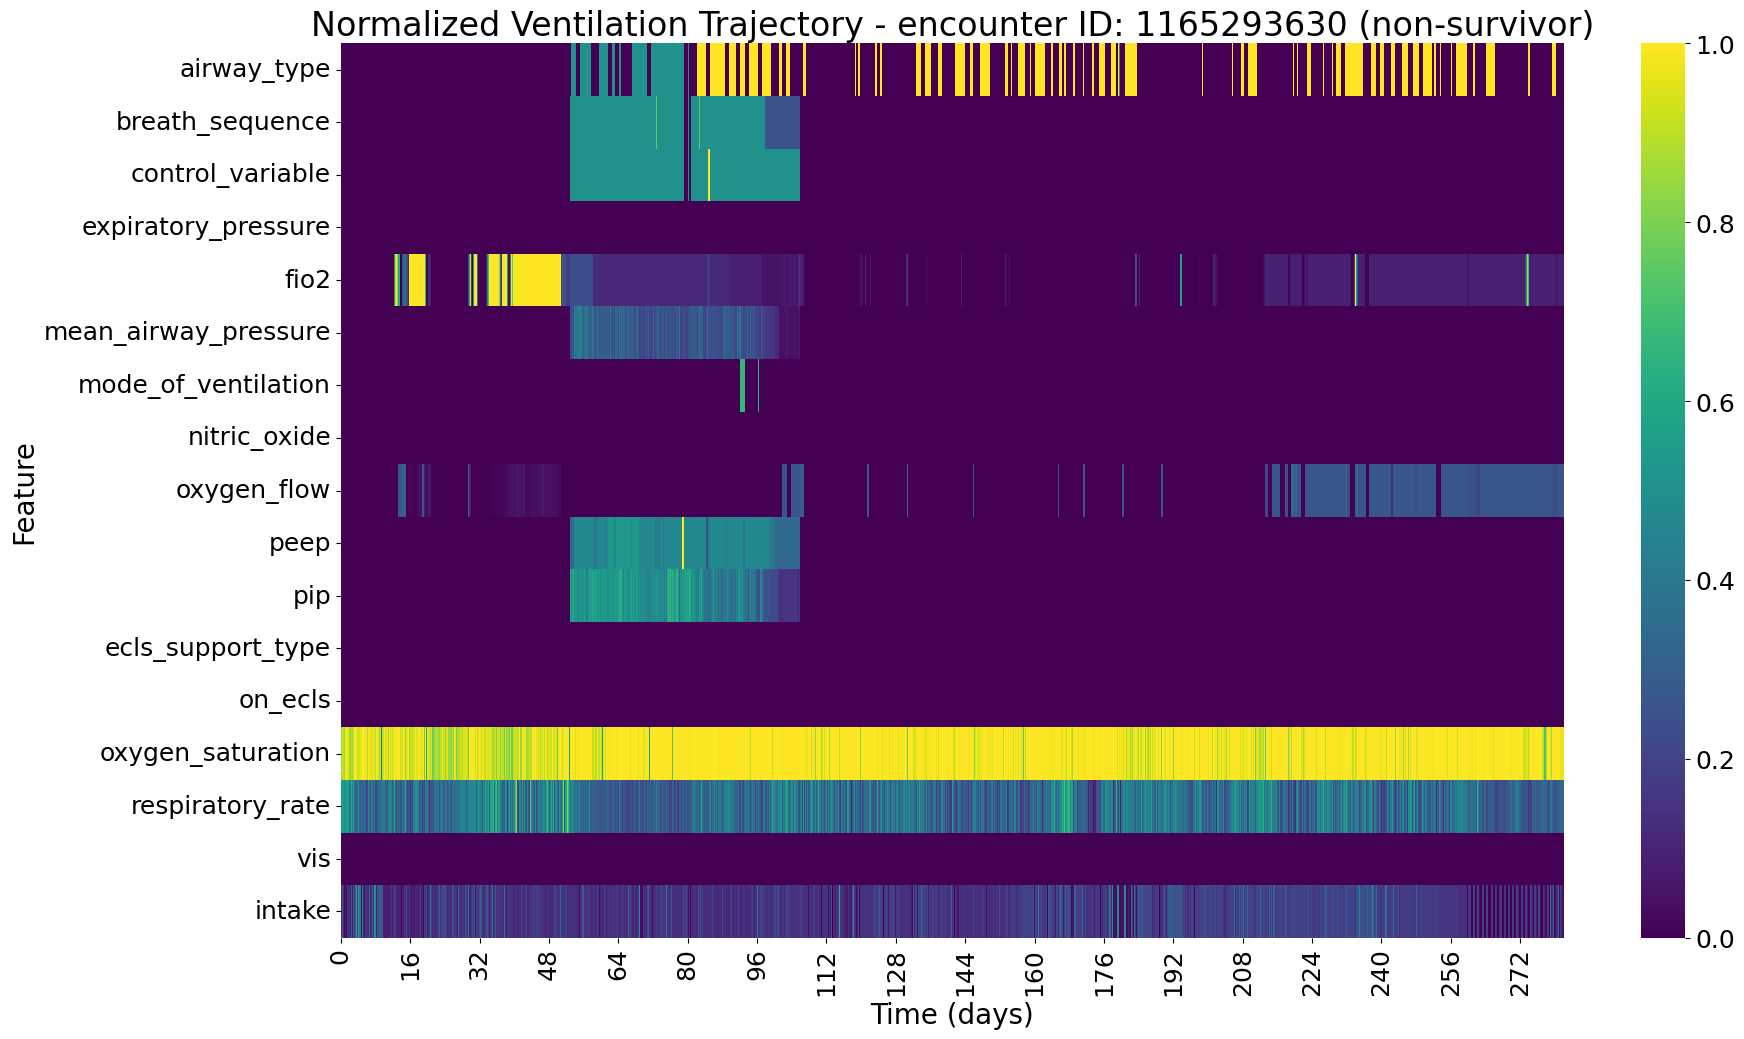

Using example encounter ID: 1165785967
Encounter ID 1165785967 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165785967_non-survivor.png


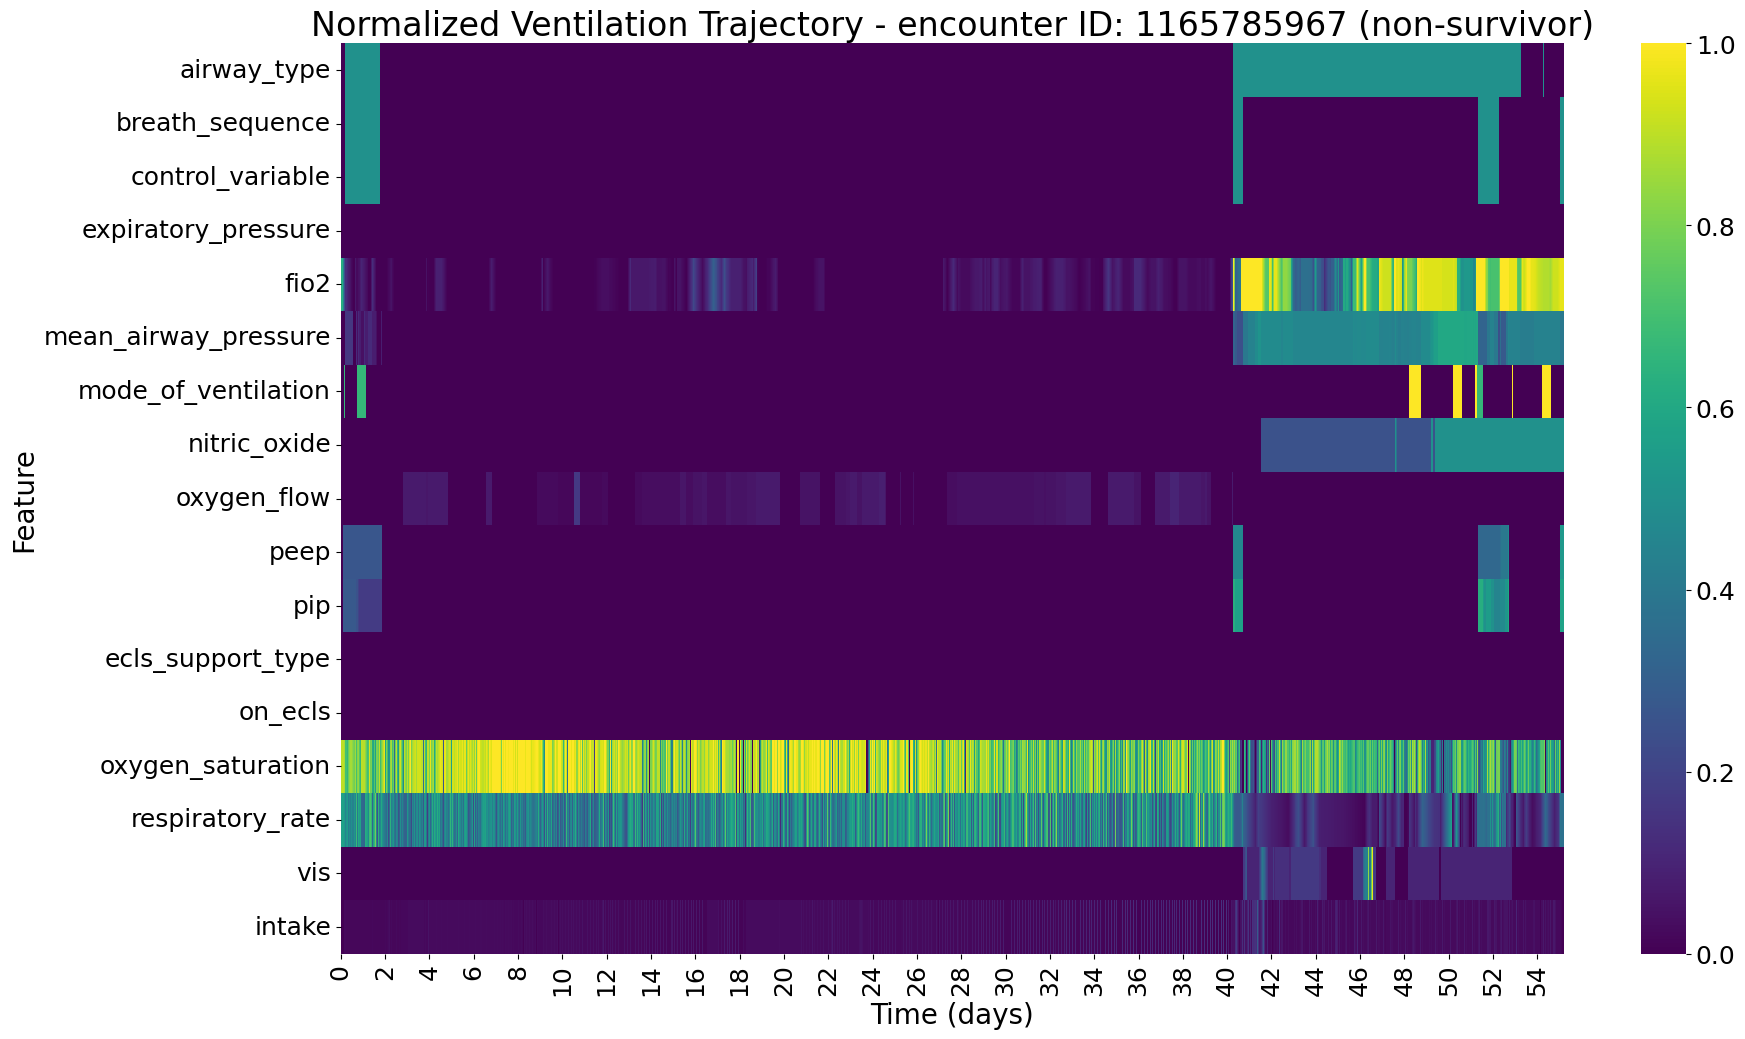

Using example encounter ID: 1165848043
Encounter ID 1165848043 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165848043_non-survivor.png


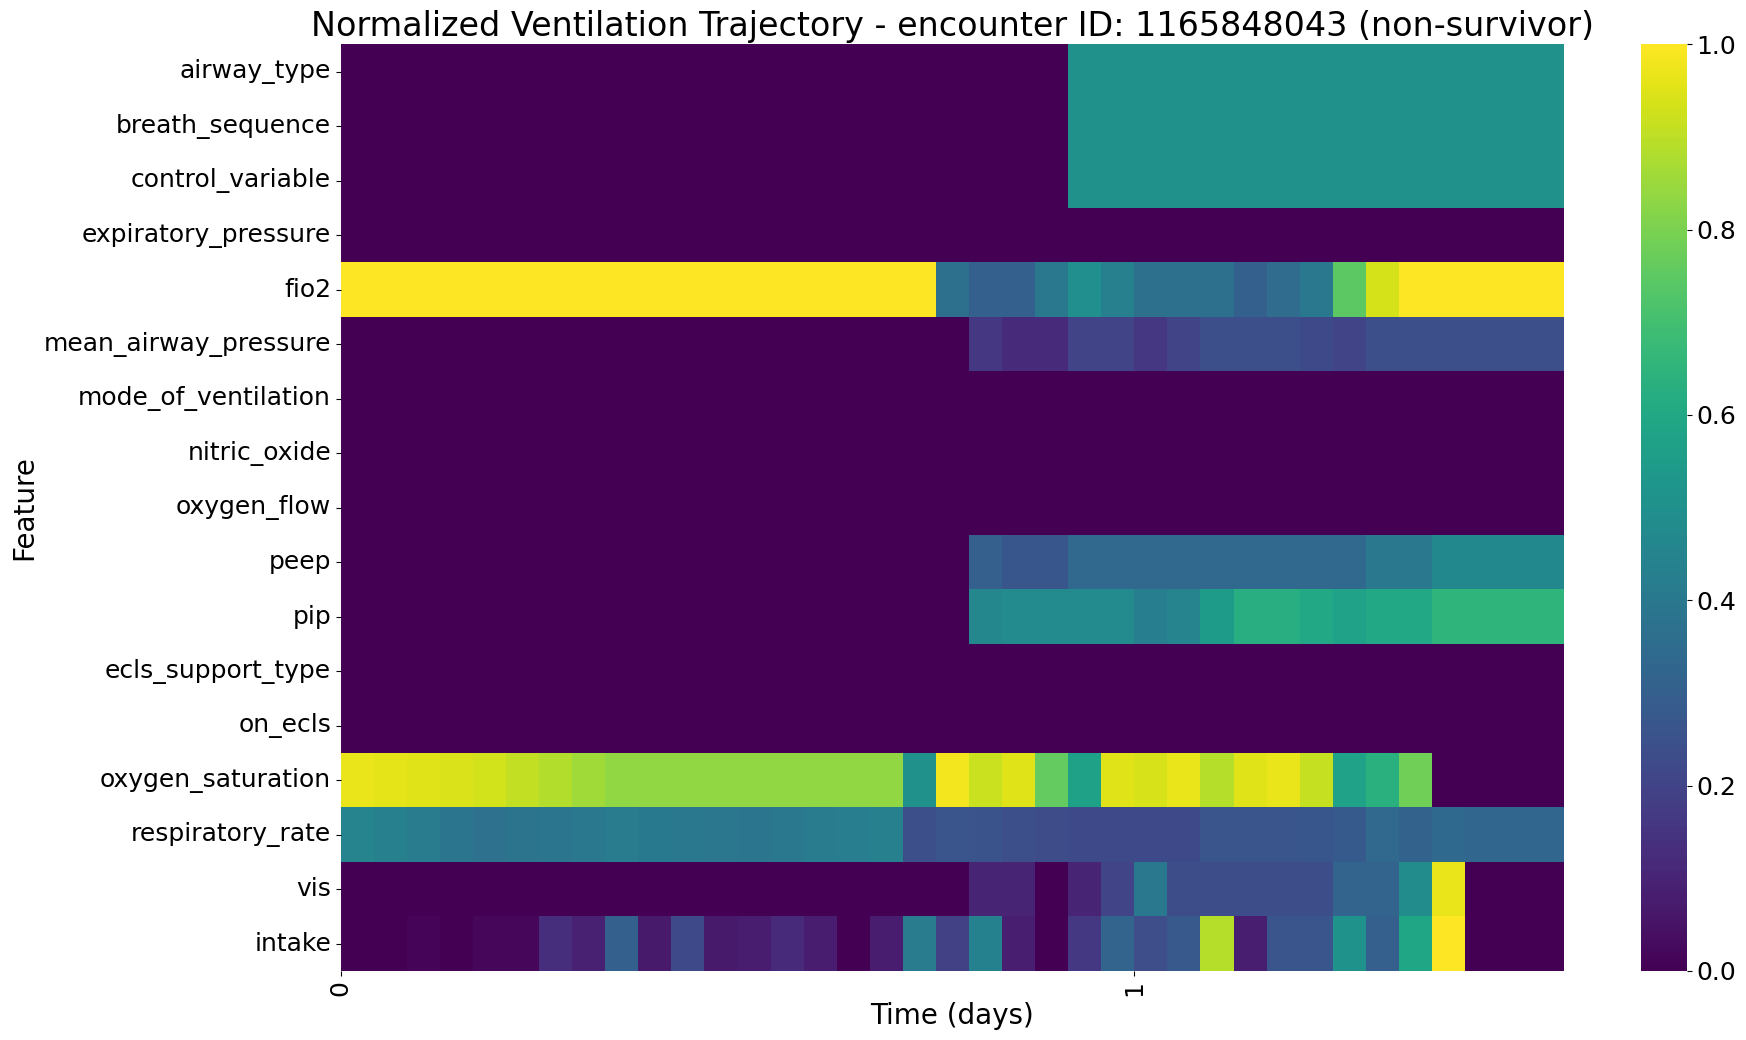

Using example encounter ID: 1165852978
Encounter ID 1165852978 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1165852978_non-survivor.png


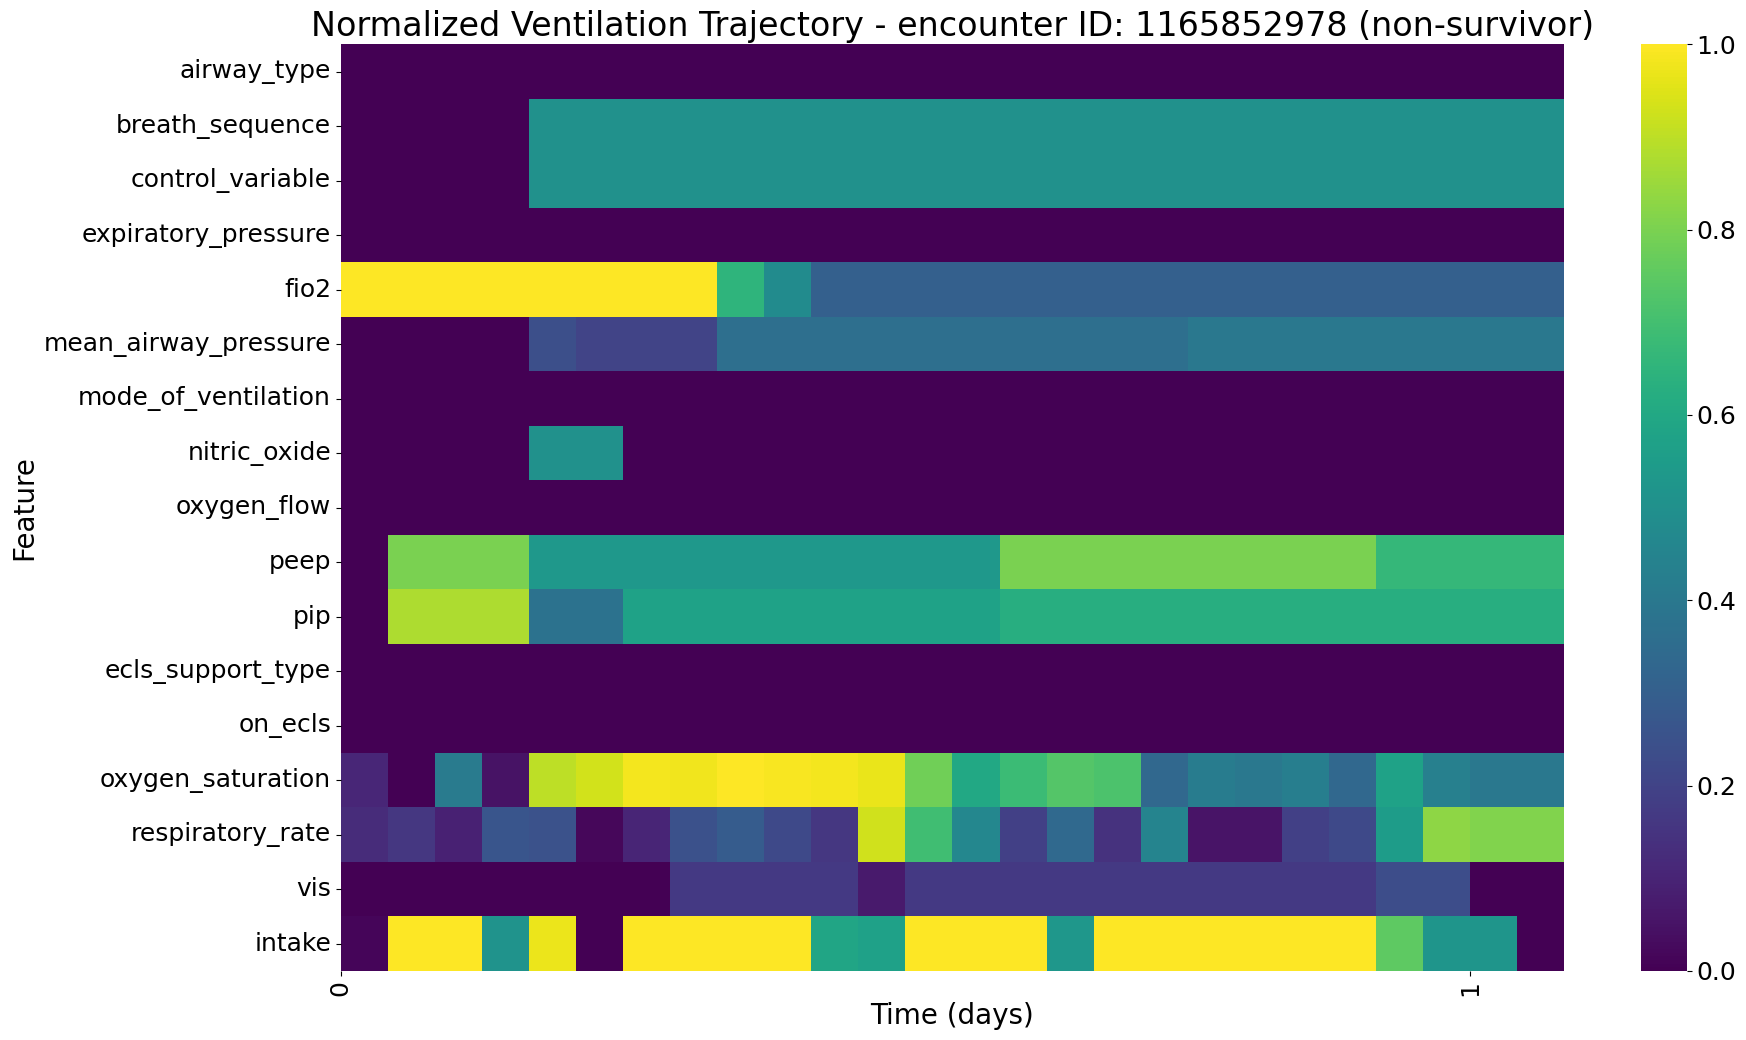

Using example encounter ID: 1166255640
Encounter ID 1166255640 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166255640_non-survivor.png


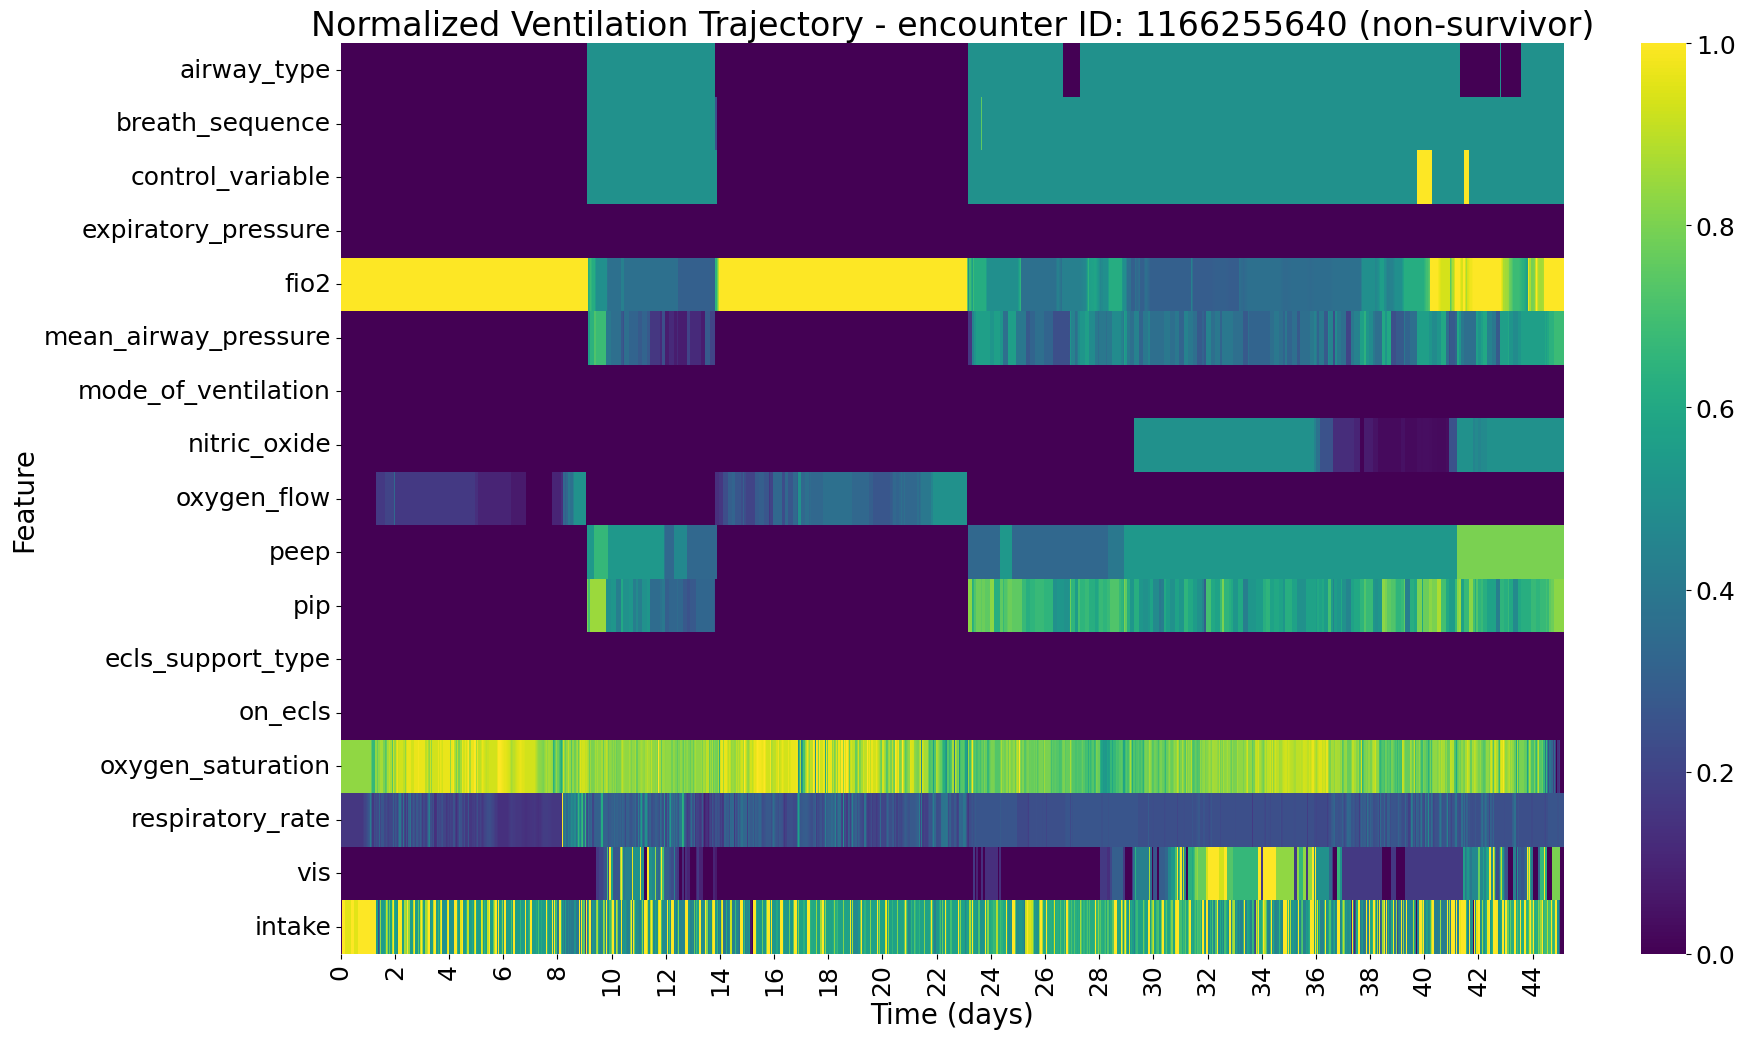

Using example encounter ID: 1166529327
Encounter ID 1166529327 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166529327_non-survivor.png


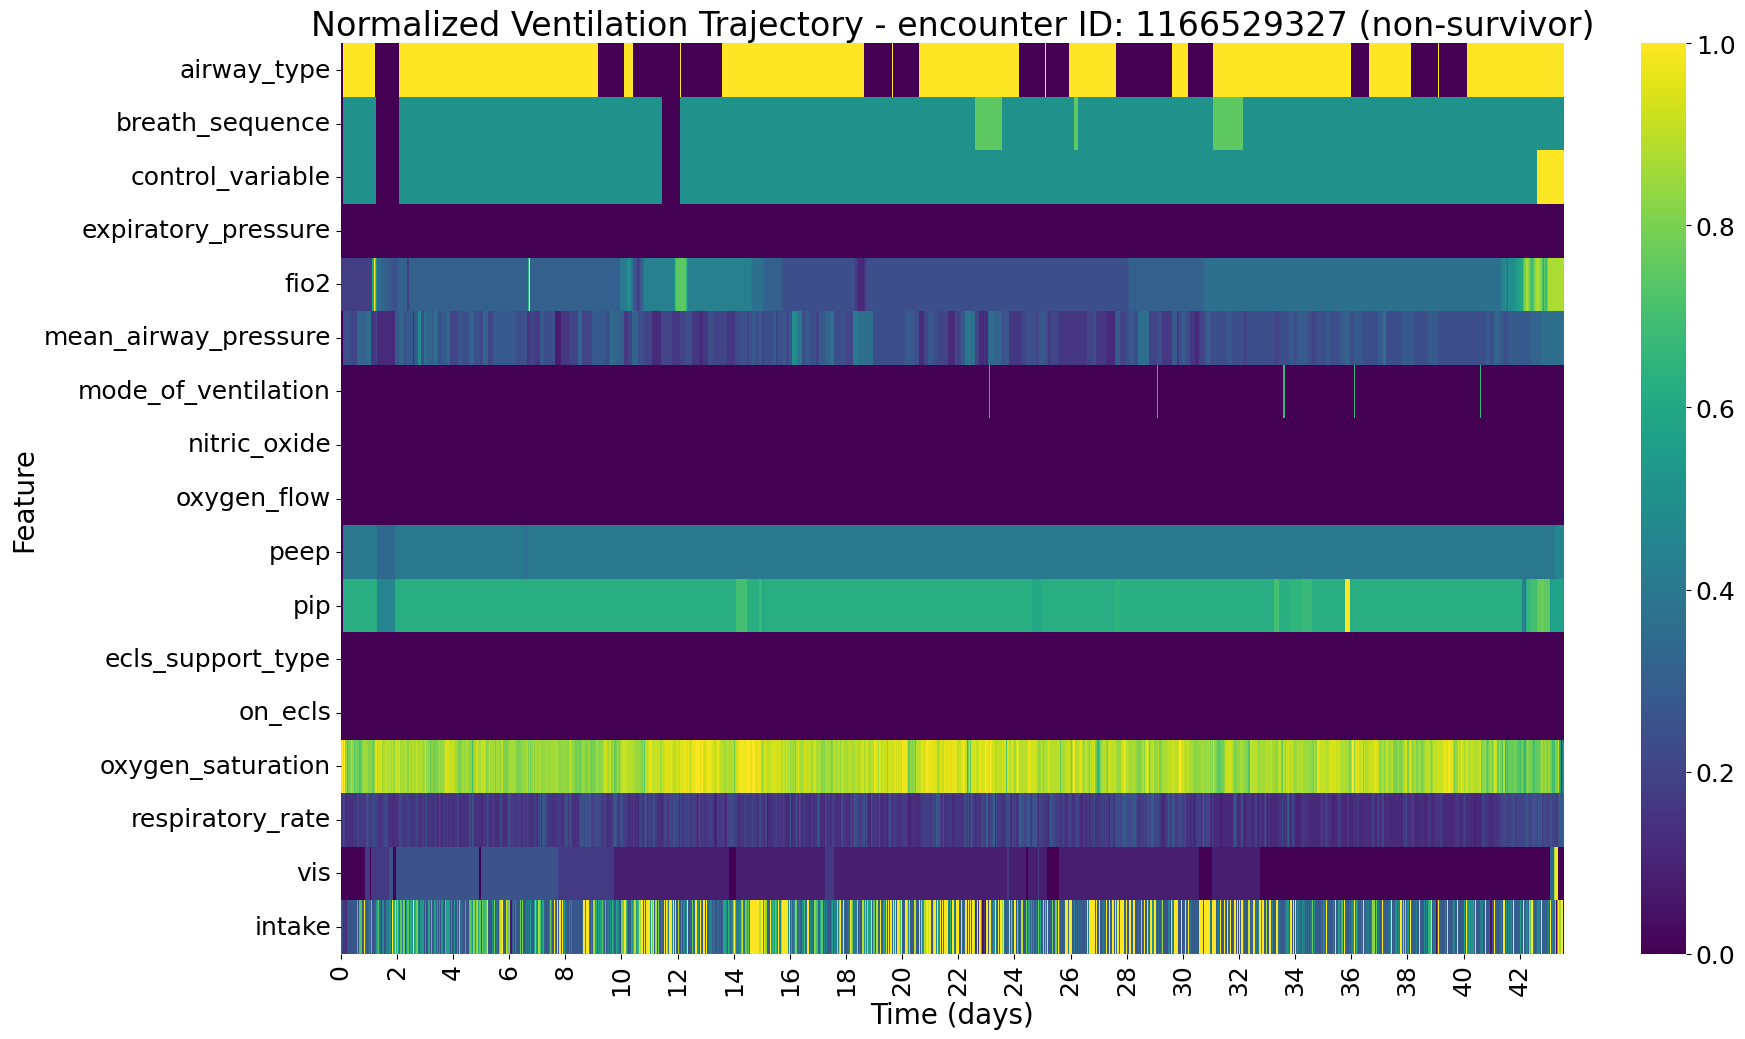

Using example encounter ID: 1166747967
Encounter ID 1166747967 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166747967_non-survivor.png


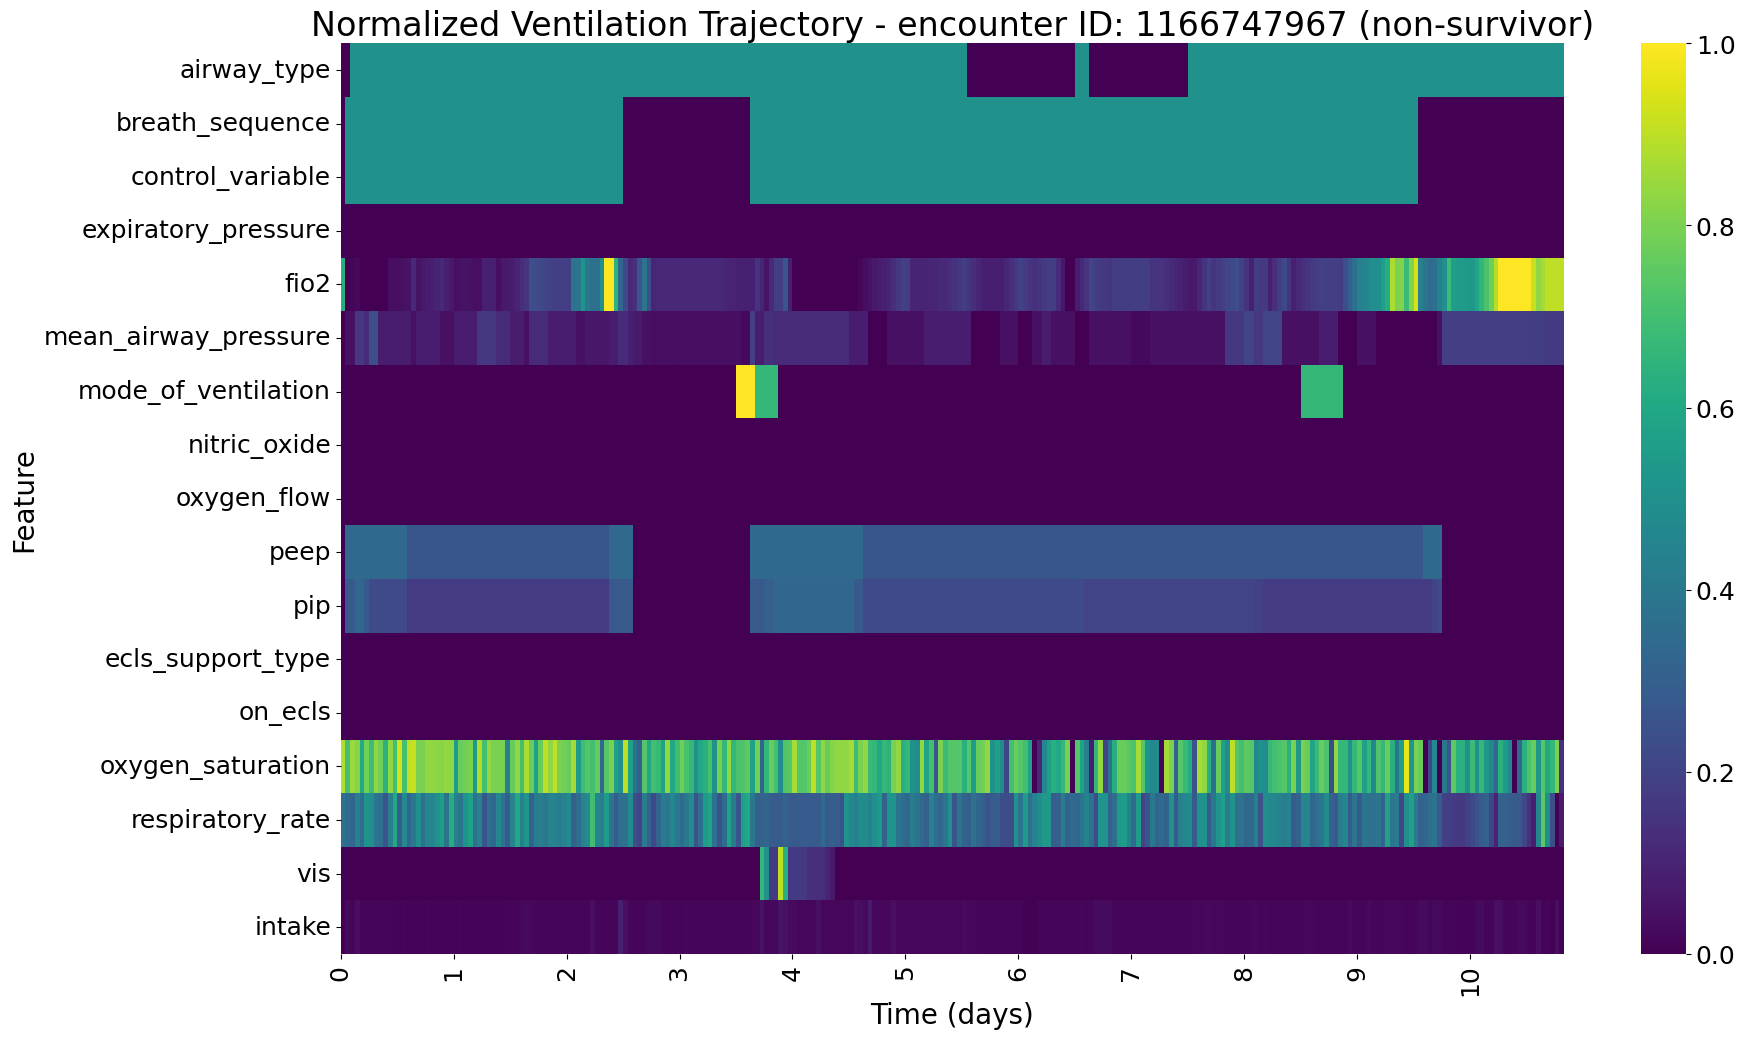

Using example encounter ID: 1166923550
Encounter ID 1166923550 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166923550_non-survivor.png


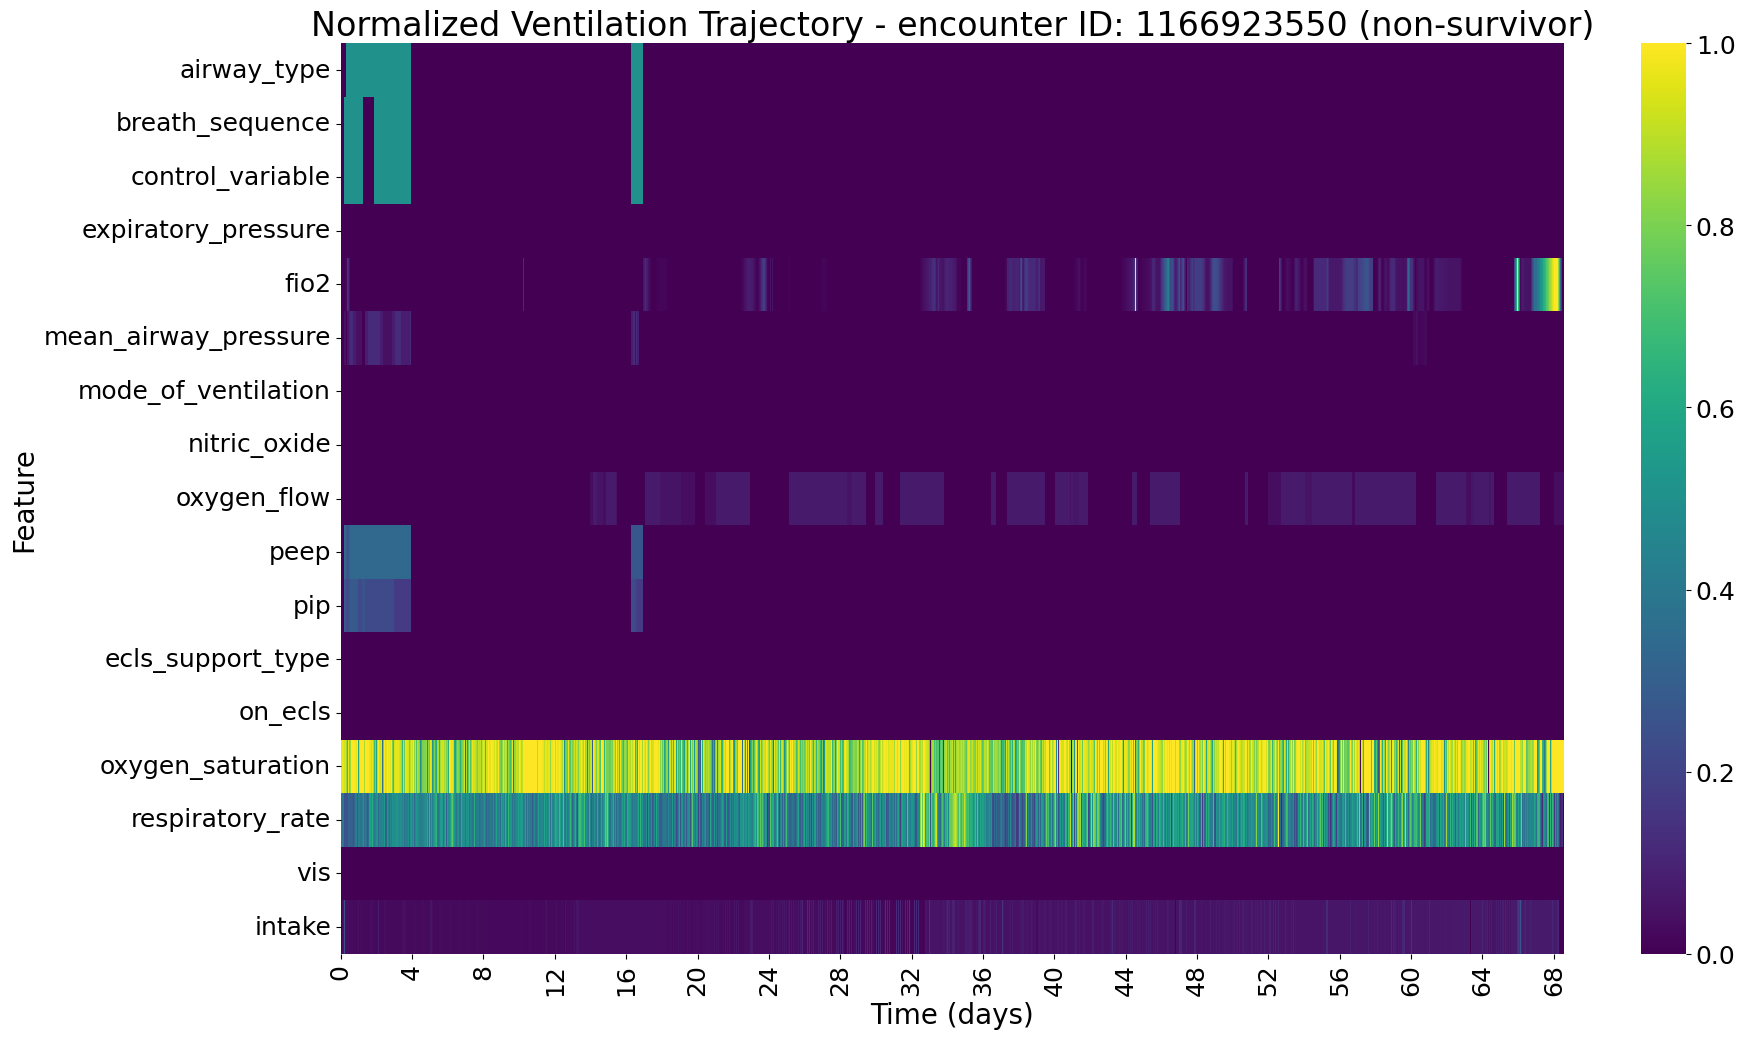

Using example encounter ID: 1166950914
Encounter ID 1166950914 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1166950914_non-survivor.png


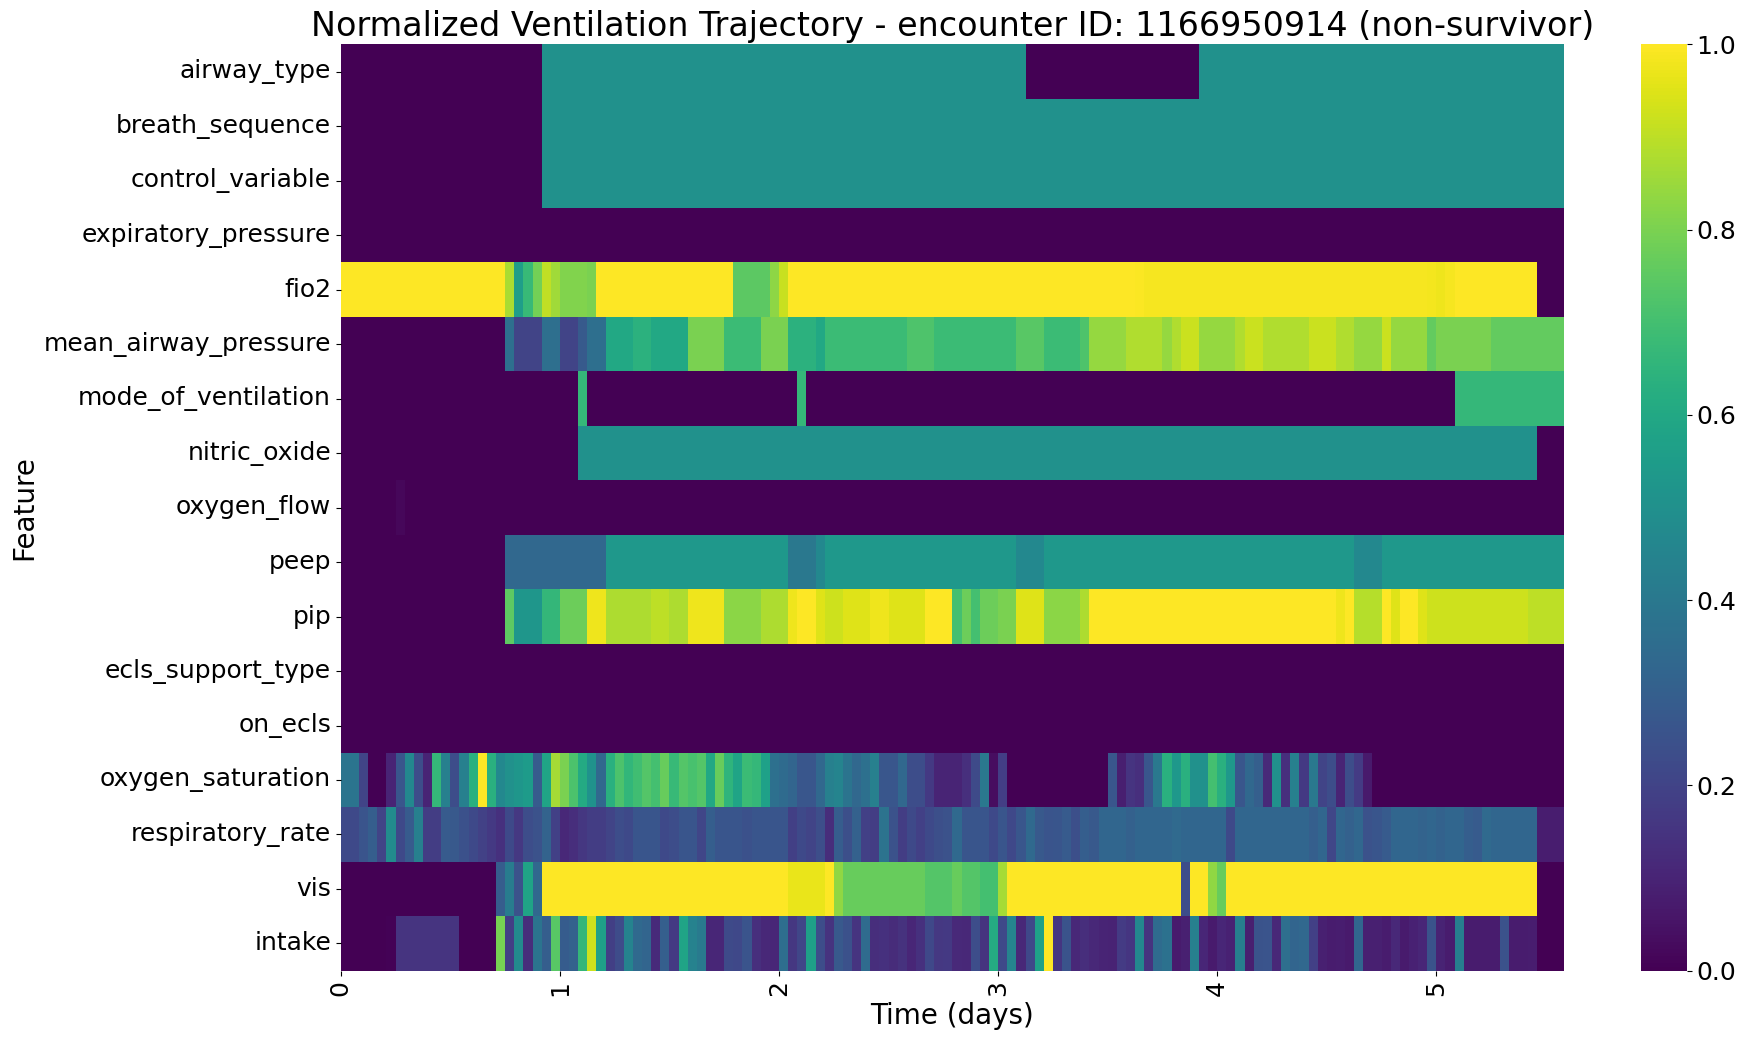

Using example encounter ID: 1167172587
Encounter ID 1167172587 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167172587_non-survivor.png


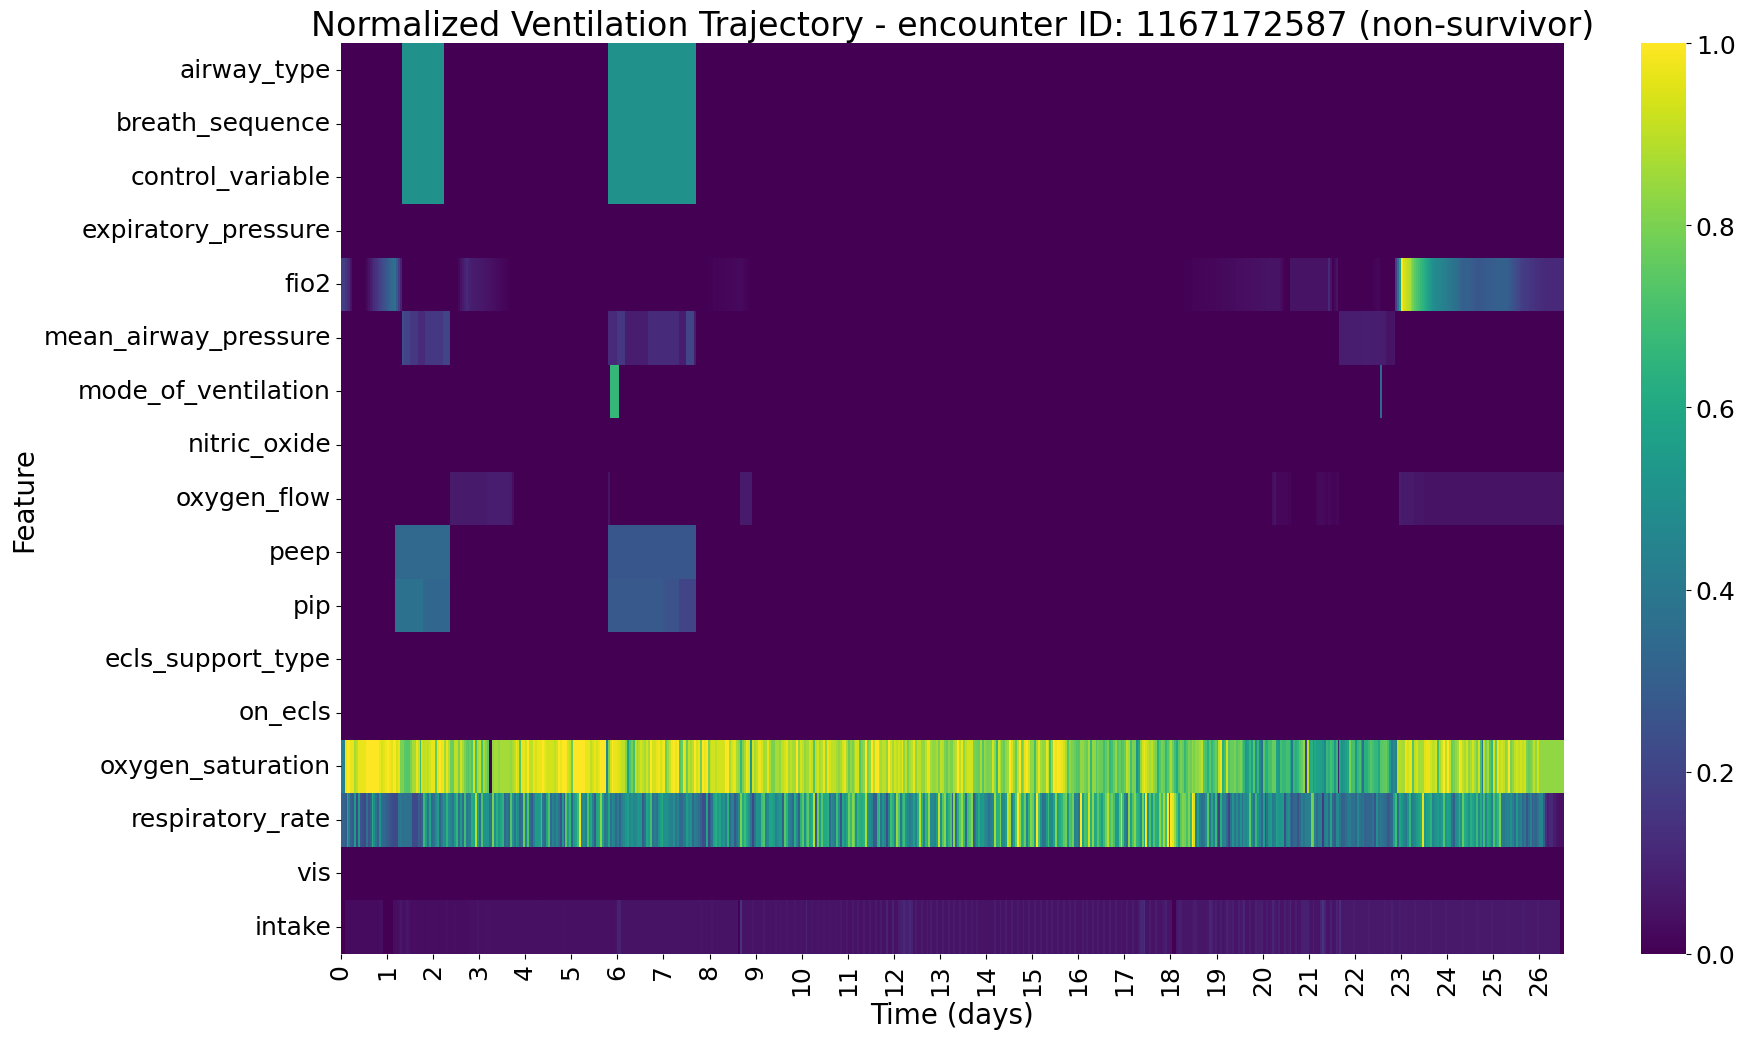

Using example encounter ID: 1167261952
Encounter ID 1167261952 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167261952_non-survivor.png


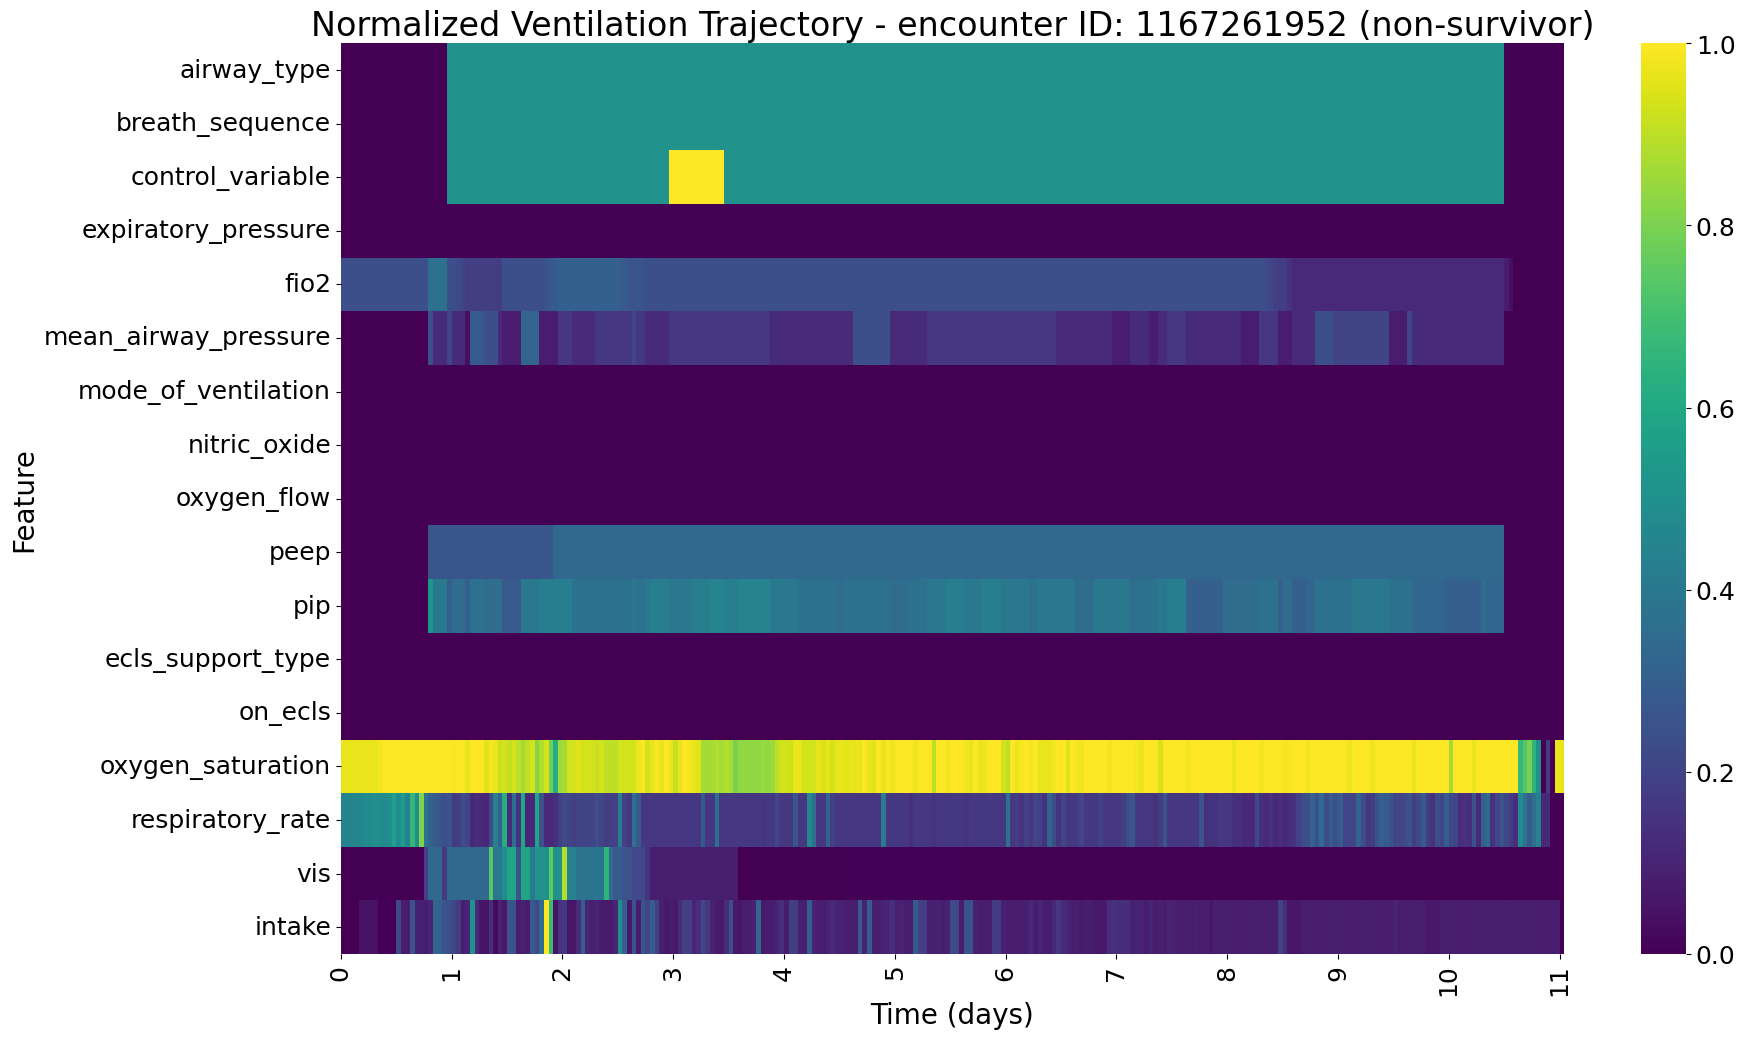

Using example encounter ID: 1167393205
Encounter ID 1167393205 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167393205_non-survivor.png


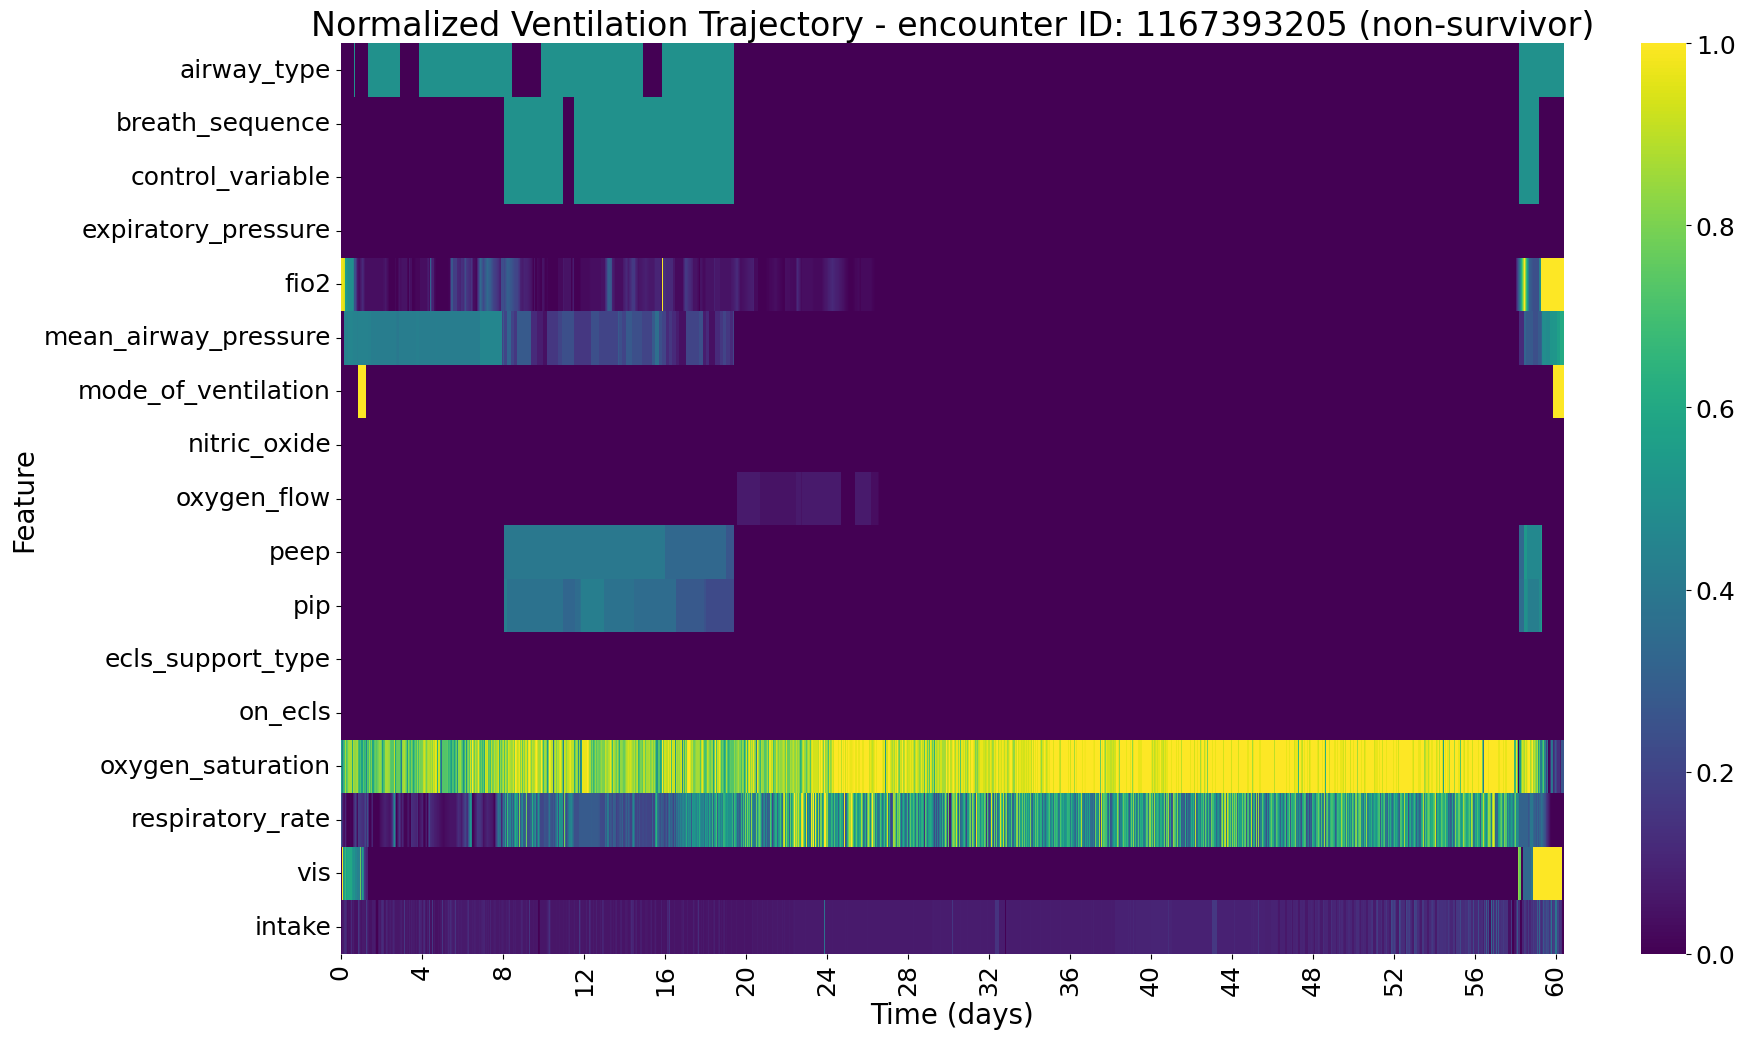

Using example encounter ID: 1167393686
Encounter ID 1167393686 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167393686_non-survivor.png


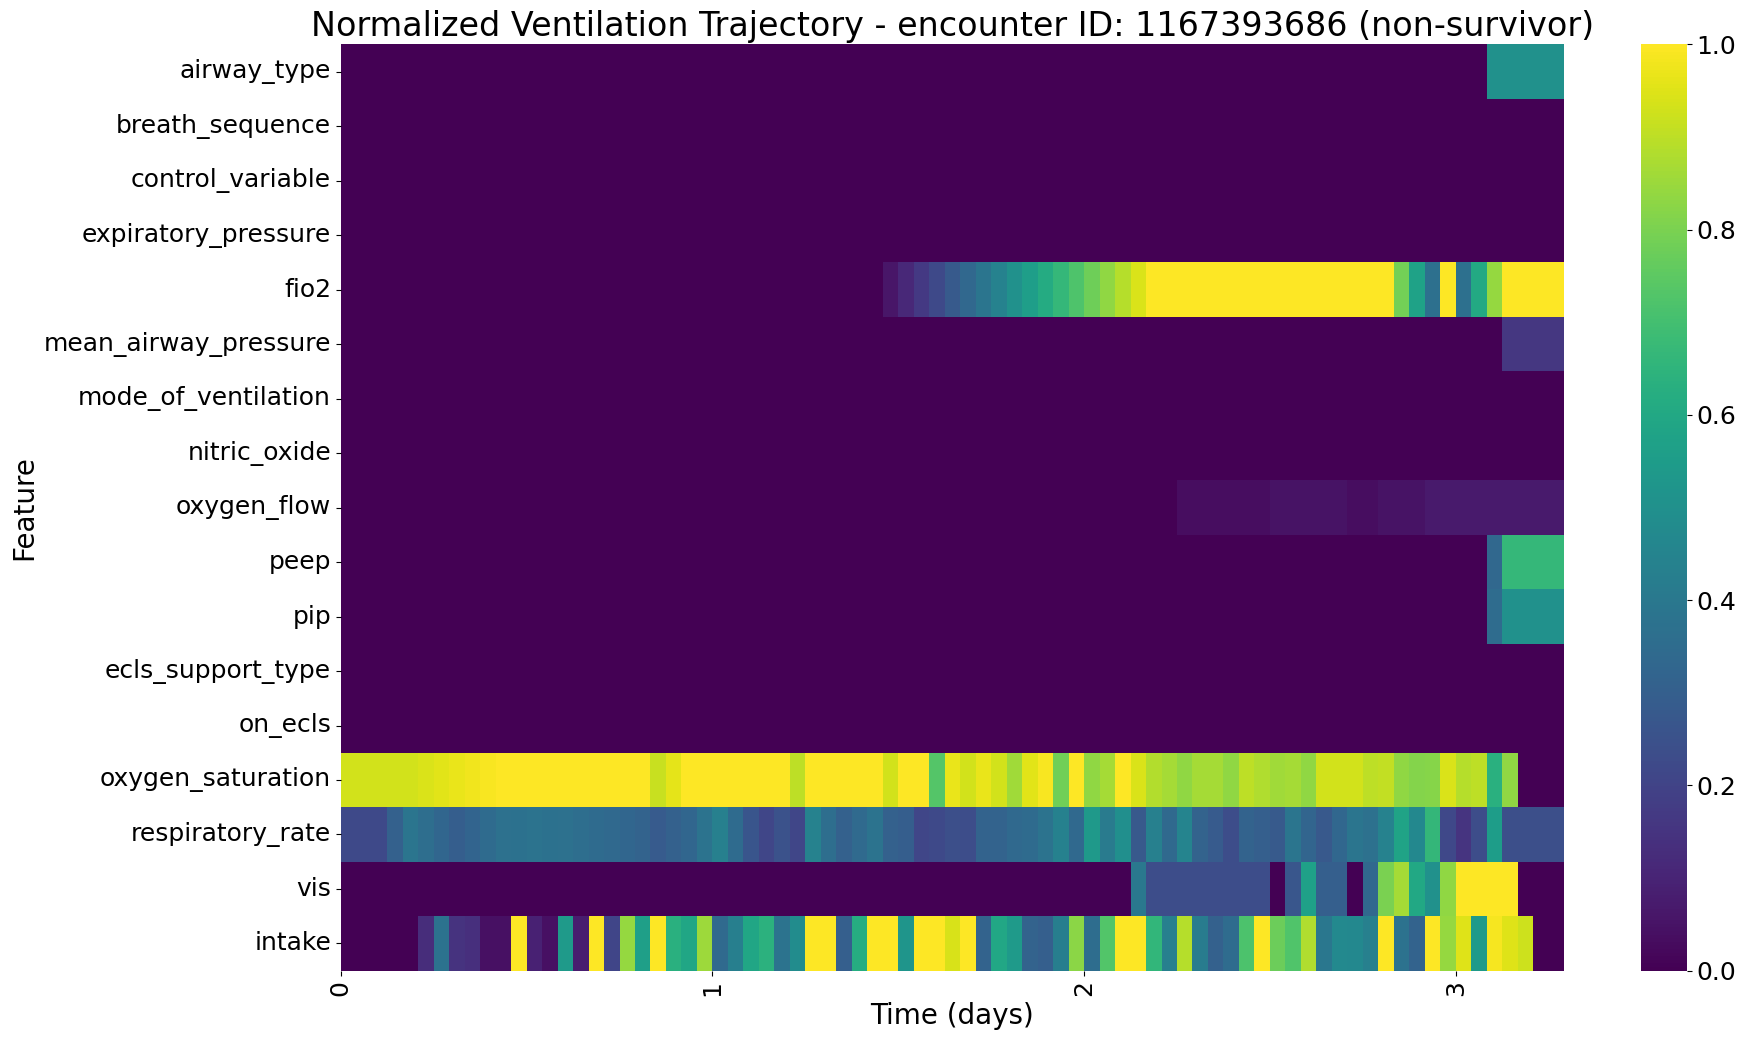

Using example encounter ID: 1167468715
Encounter ID 1167468715 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167468715_non-survivor.png


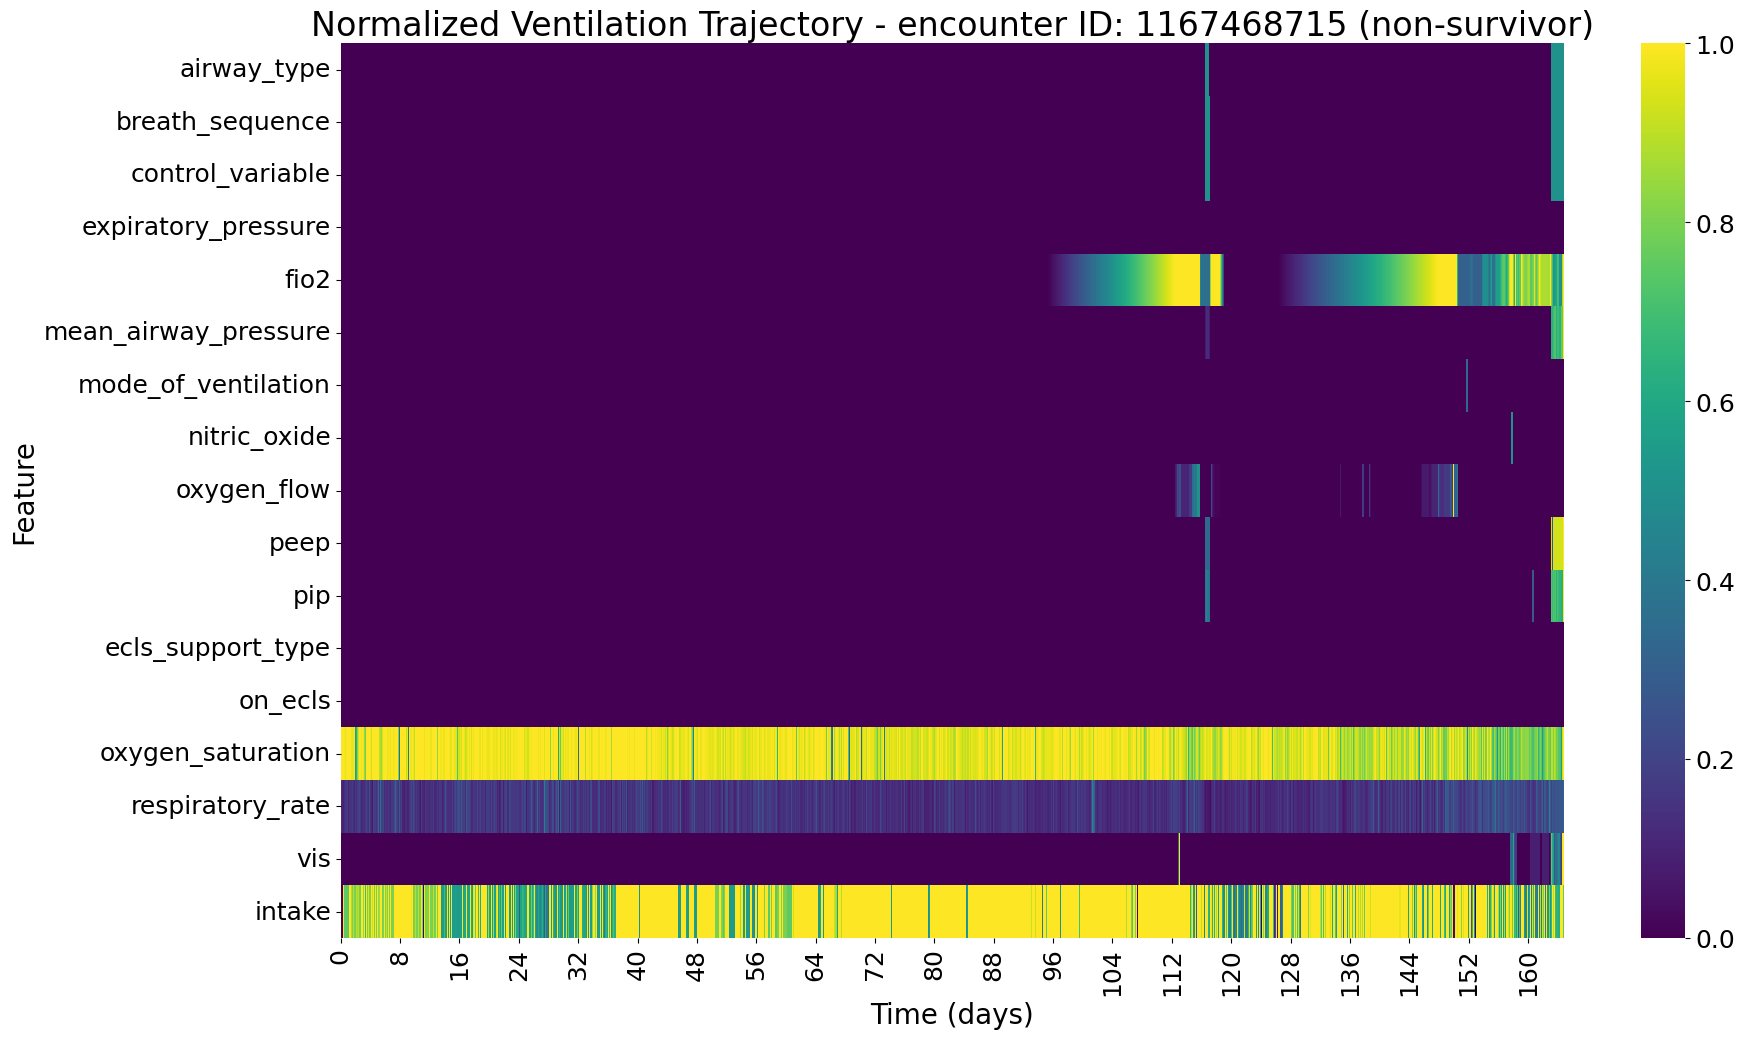

Using example encounter ID: 1167556995
Encounter ID 1167556995 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167556995_non-survivor.png


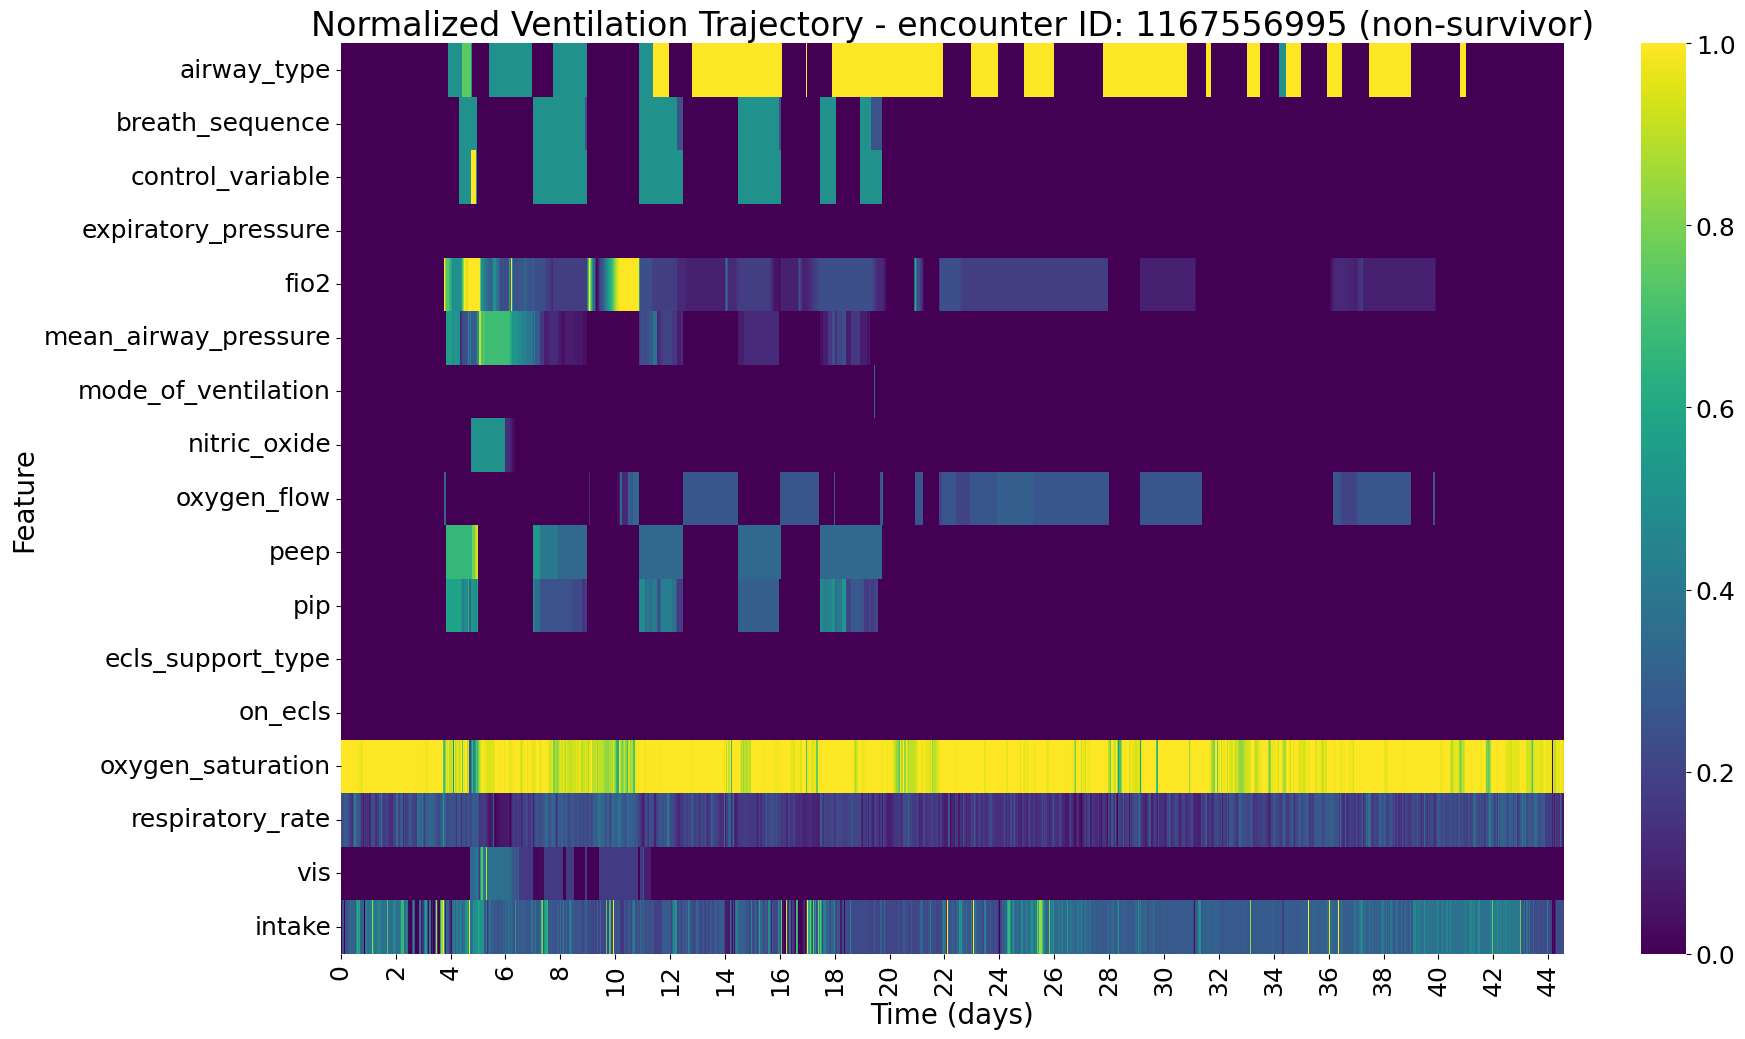

Using example encounter ID: 1167607731
Encounter ID 1167607731 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167607731_non-survivor.png


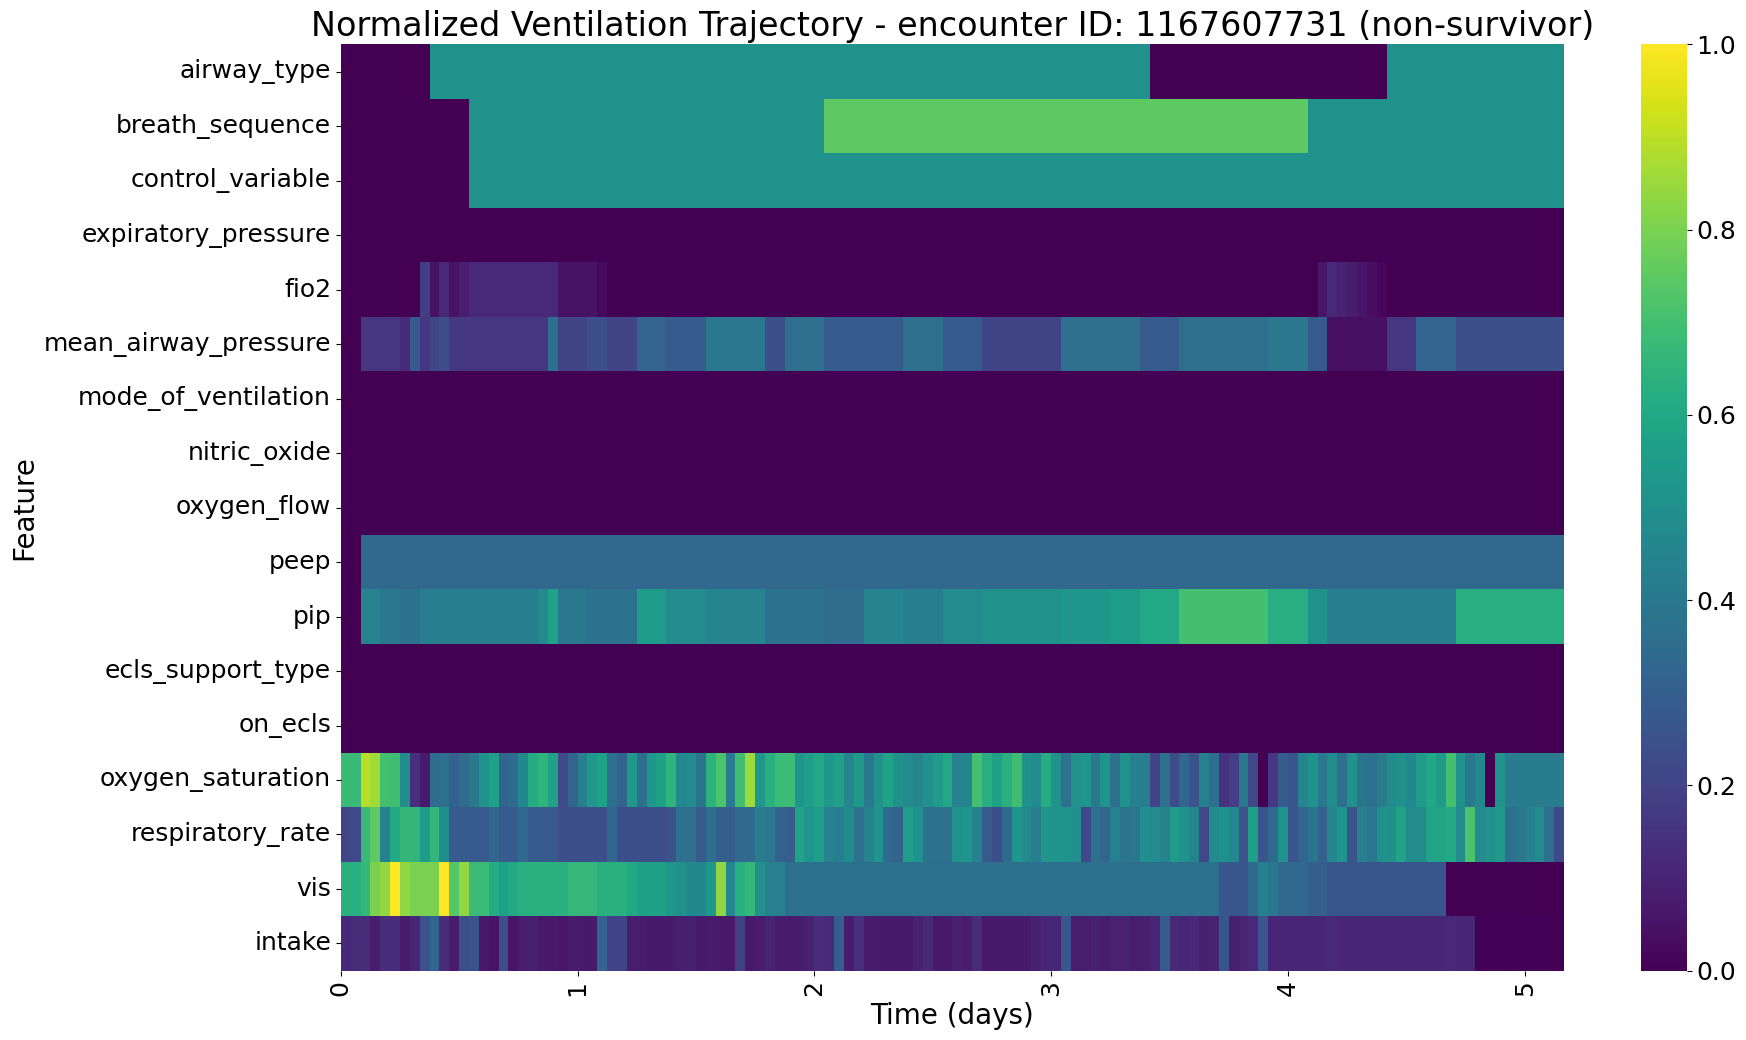

Using example encounter ID: 1167620748
Encounter ID 1167620748 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167620748_non-survivor.png


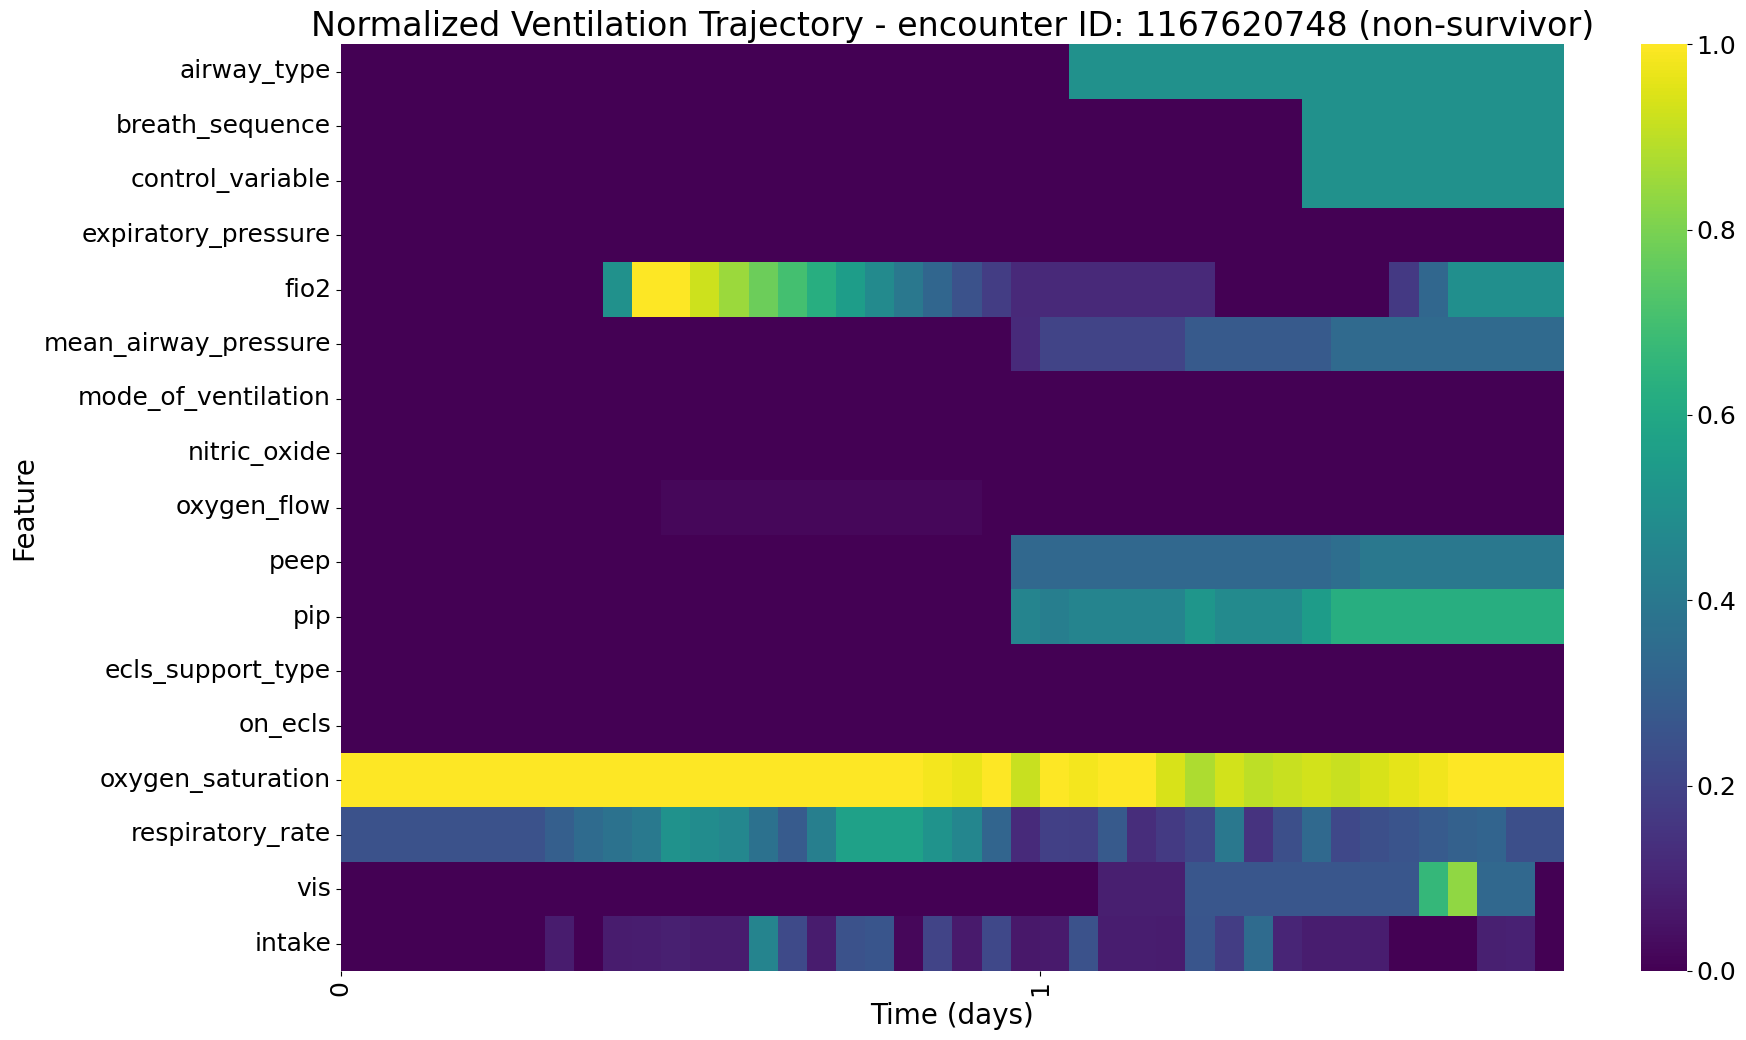

Using example encounter ID: 1167641295
Encounter ID 1167641295 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167641295_non-survivor.png


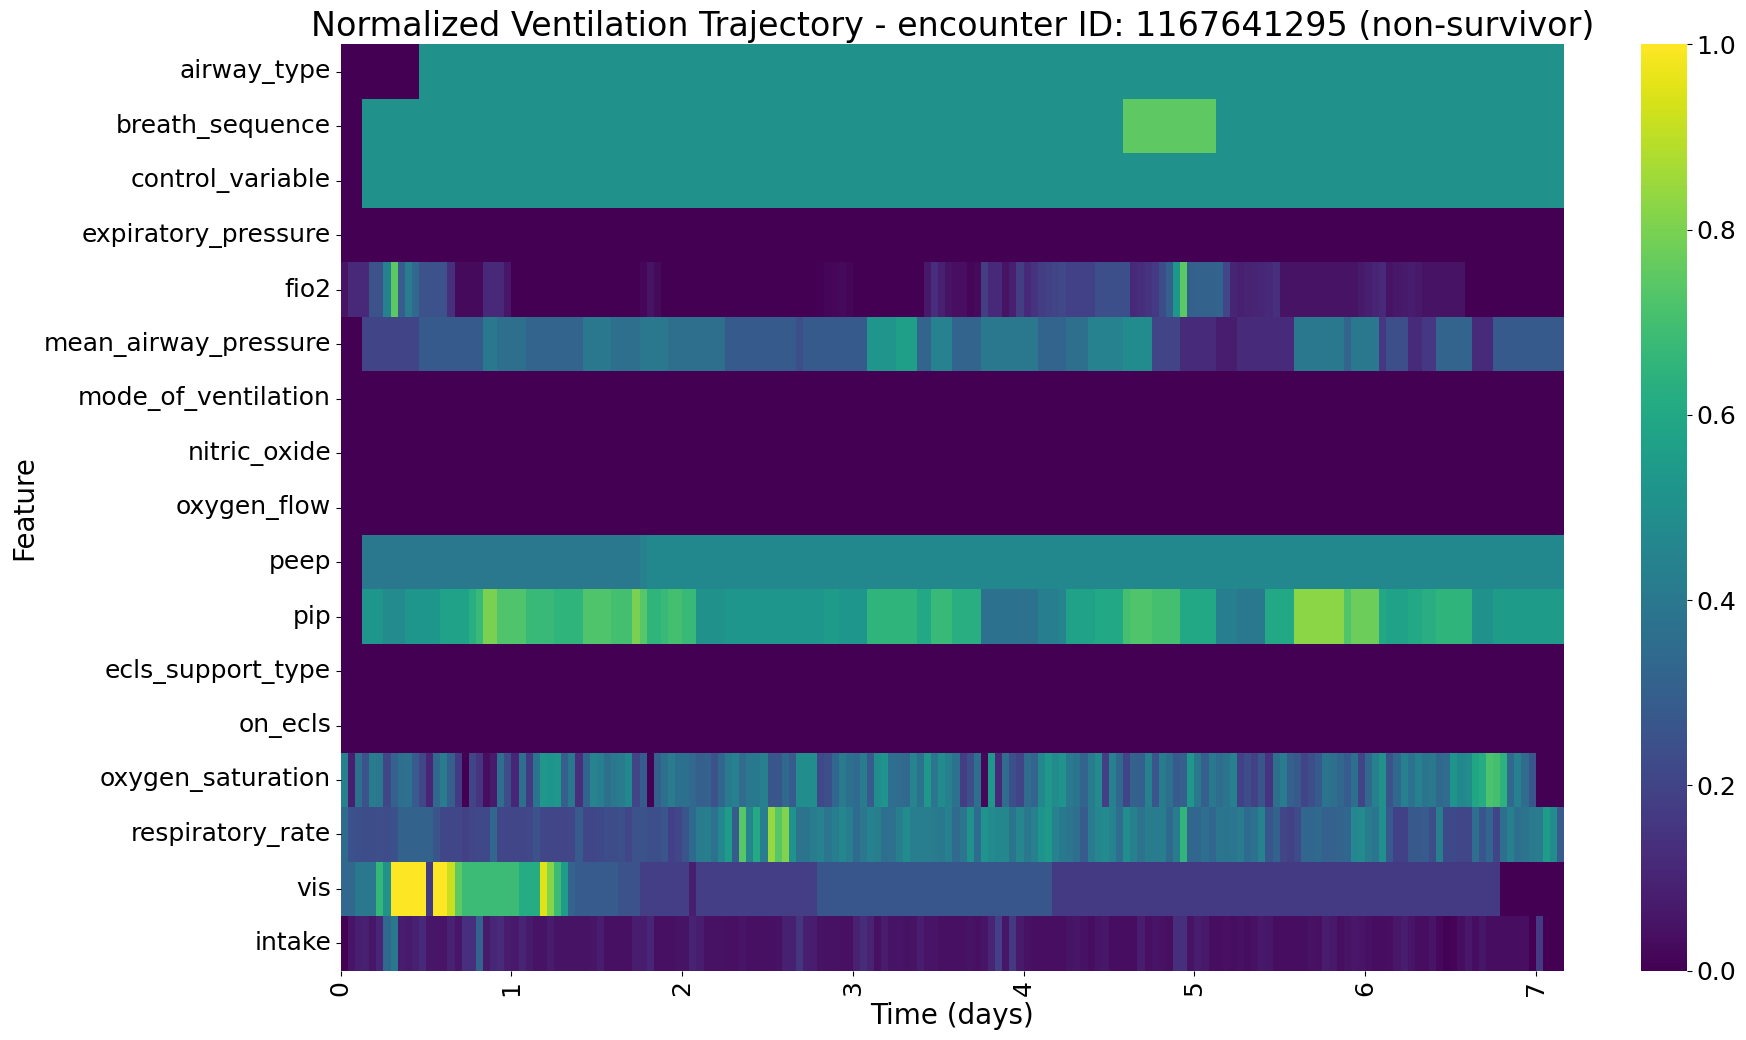

Using example encounter ID: 1167685427
Encounter ID 1167685427 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167685427_non-survivor.png


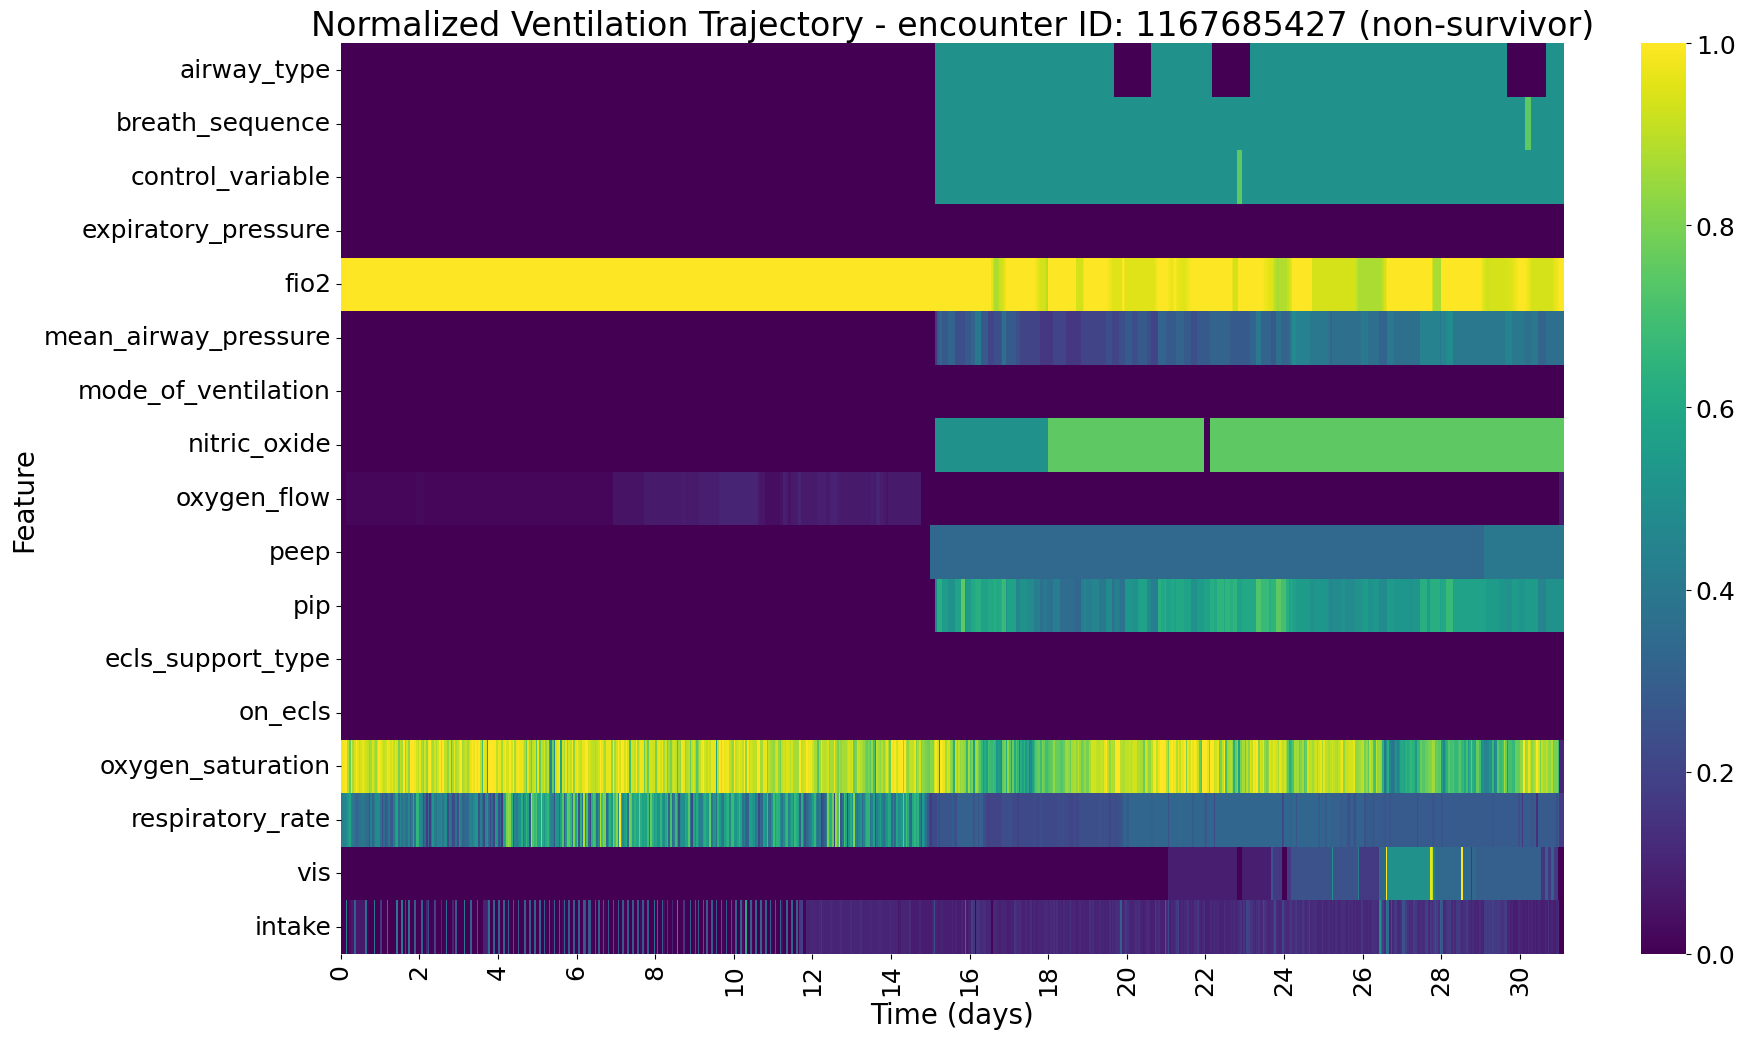

Using example encounter ID: 1167713317
Encounter ID 1167713317 is a non-survivor.
Heatmap saved to /home/jake/Documents/AI_Clinician/experiments/vent_trajectories/encounter_id_1167713317_non-survivor.png


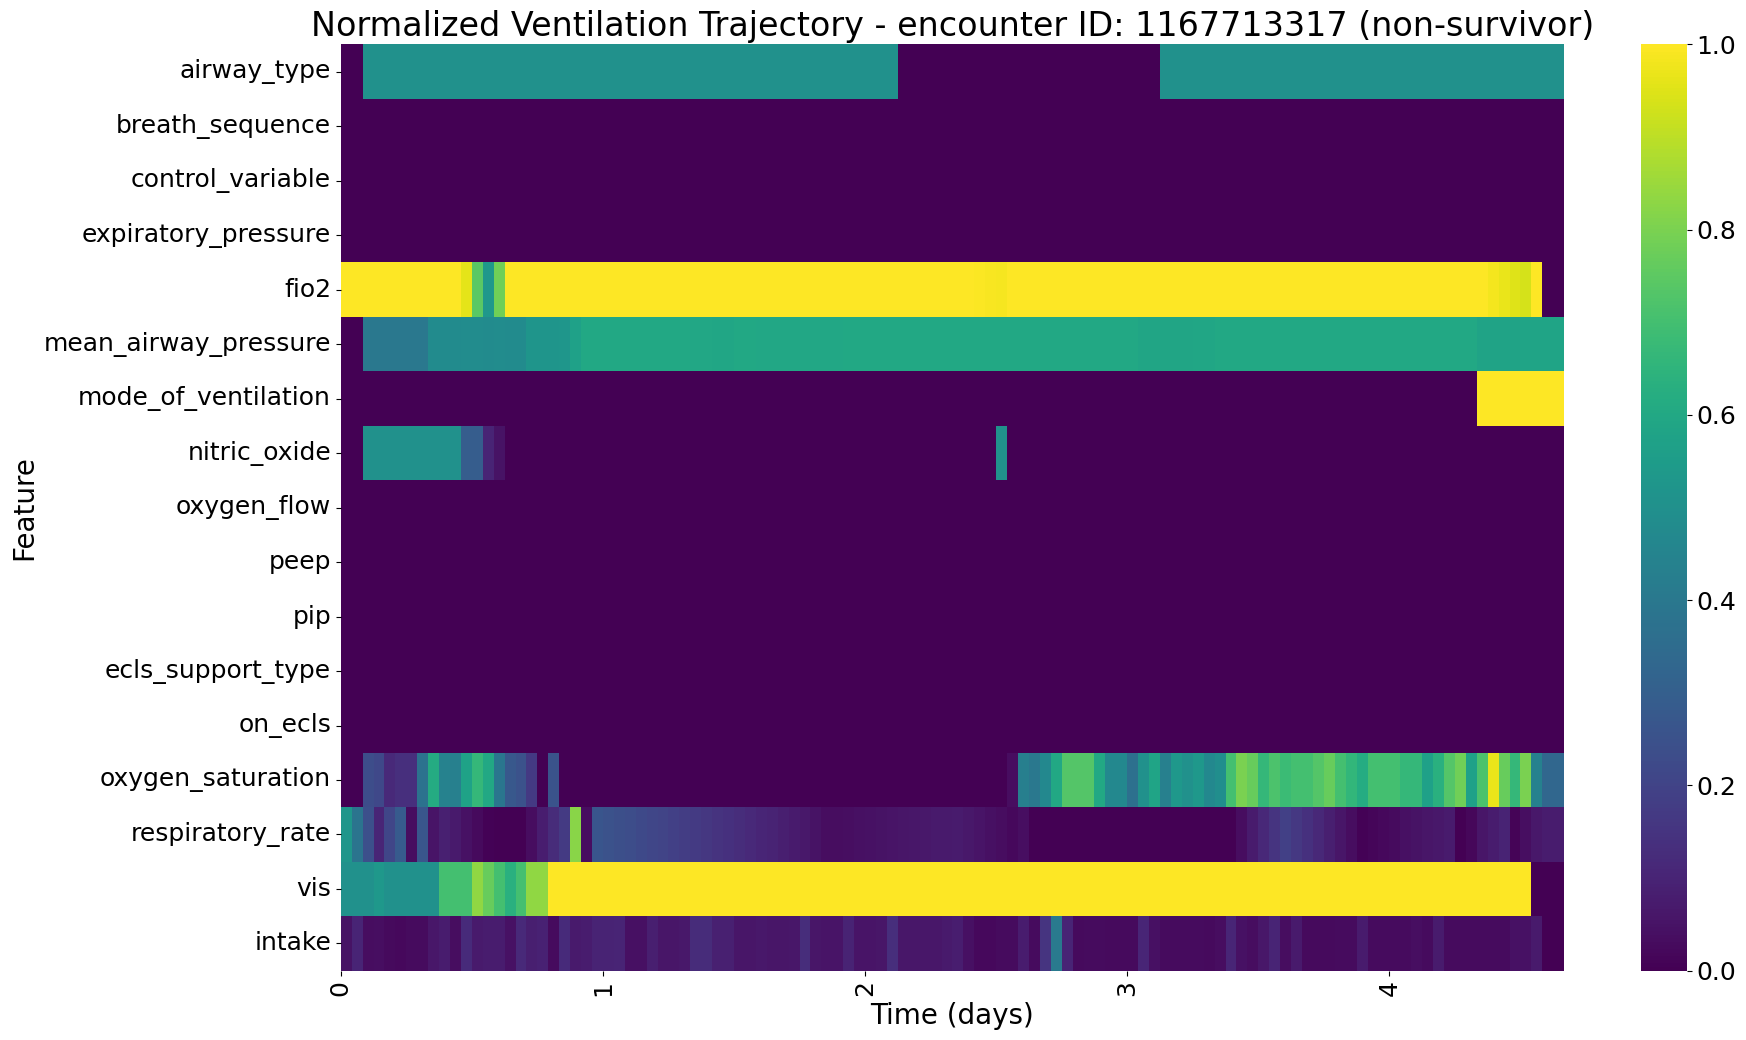

In [60]:
# plot 20 non-survivor encounters 
non_survive_encounter_id = 0
for _ in range(20):
    encounter_id = non_survivor_ids[non_survive_encounter_id]
    plot_encounter_heatmap(training_data, non_survivor_ids, encounter_id, plot_dir=plot_dir)
    non_survive_encounter_id += 1

In [ ]:
# plot 20 non-survivor encounters
non_survive_encounter_id = 0
for _ in range(20):
    encounter_id = non_survivor_ids[non_survive_encounter_id]
    plot_encounter_heatmap(training_data, predictions_df, non_survivor_ids, encounter_id)
    non_survive_encounter_id += 1

Using example encounter ID: 1165293630
Encounter ID 1165293630 is a non-survivor.


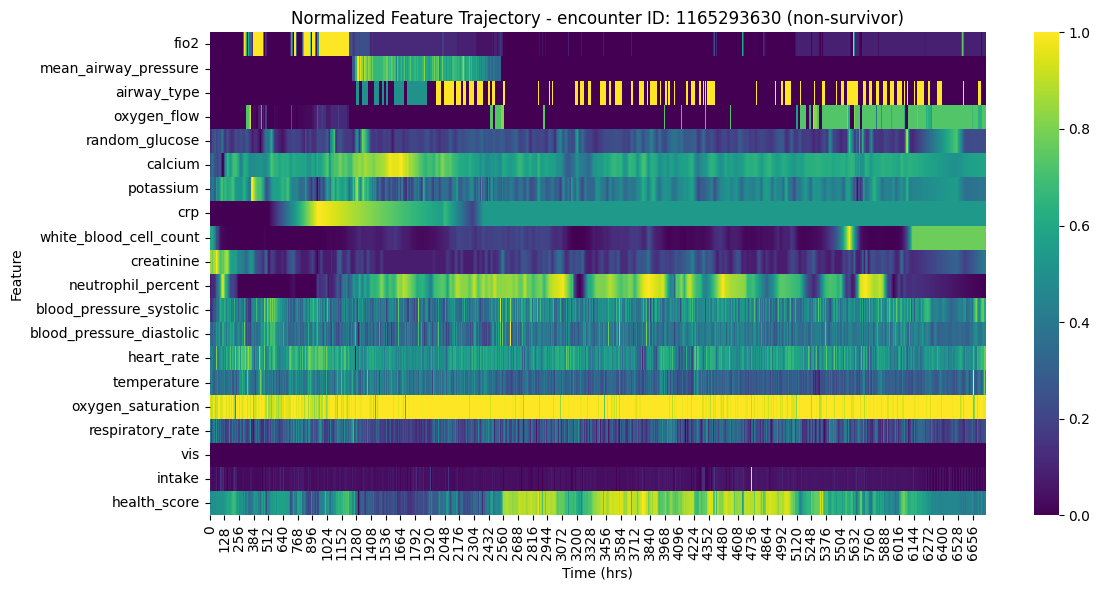

In [47]:
non_survive_encounter_id = 0
encounter_id = non_survivor_ids[non_survive_encounter_id]
example_training_traj = plot_encounter_heatmap(training_data, predictions_df, non_survivor_ids, encounter_id)
non_survive_encounter_id += 1

In [48]:
non_survive_encounter_id = 0
encounter_id = non_survivor_ids[non_survive_encounter_id]
example_training_traj = plot_encounter_heatmap(training_data, predictions_df, non_survivor_ids, encounter_id)
non_survive_encounter_id += 1

np.float64(1.0)

In [18]:
encounter_traj

,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,white_blood_cell_count,creatinine,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,health_score
10936,0.21,0.0,0.0,0.0,135.0,8.1,4.100,0.020000,5.900000,0.63,23.000000,23.0,19.0,122.0,34.30,89.0,36.0,0.0,1.000093
10937,0.25,0.0,0.0,0.0,135.0,8.1,4.100,0.020000,5.900000,0.63,23.000000,23.0,19.0,122.0,34.30,89.0,36.0,0.0,0.998889
10938,0.29,10.0,0.0,0.0,135.0,8.1,4.100,0.030833,5.883333,0.63,24.666667,23.0,19.0,140.0,35.35,87.5,28.0,0.0,0.998305
10939,0.29,9.0,0.0,0.0,135.0,8.1,3.900,0.041667,5.866667,0.63,26.333333,23.0,19.0,134.0,36.40,92.0,38.0,0.0,0.997815
10940,0.25,9.0,0.0,0.0,135.0,8.1,4.015,0.052500,5.850000,0.63,28.000000,25.0,16.0,148.0,36.50,93.0,40.0,5.0,0.998212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13961,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,143.5,36.90,97.0,57.5,0.0,1.931085
13962,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,159.0,36.90,97.0,34.0,0.0,1.930064
13963,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,154.0,36.90,97.0,46.0,0.0,1.930845
13964,1.00,0.0,0.0,0.1,93.0,10.5,4.400,1.050000,10.900000,0.26,30.000000,76.0,56.0,154.0,36.90,97.0,46.0,0.0,1.930845


Using example encounter ID: 1165746083


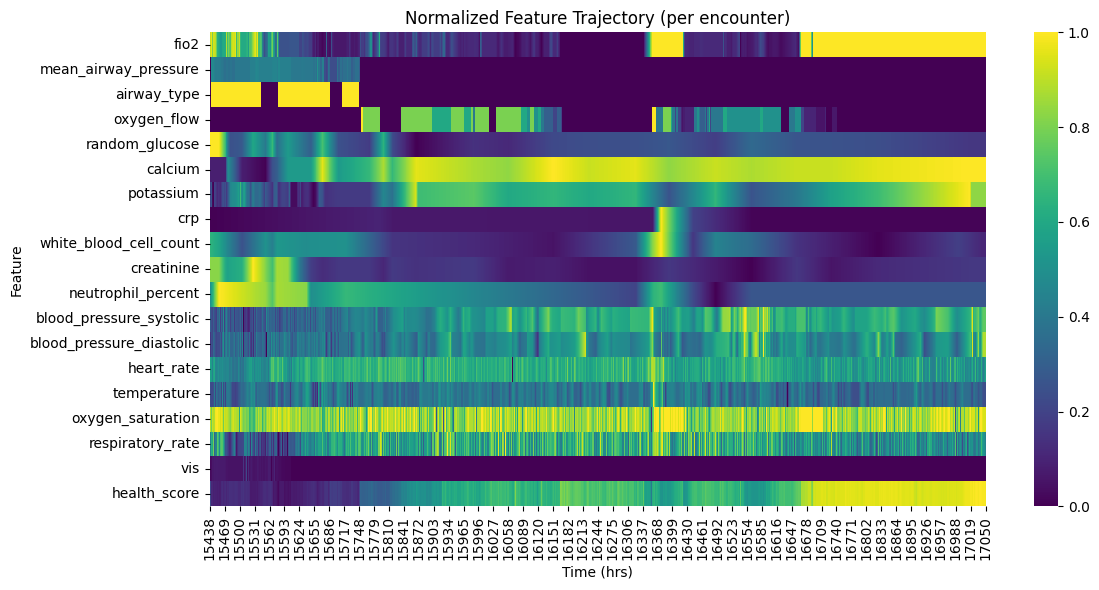

,fio2,mean_airway_pressure,airway_type,oxygen_flow,random_glucose,calcium,potassium,crp,white_blood_cell_count,creatinine,neutrophil_percent,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,temperature,oxygen_saturation,respiratory_rate,vis,health_score
15438,0.9275,0.0,0.0,0.0,232.0,8.2,3.750,0.020000,25.500000,1.04,60.000000,63.0,27.0,153.000000,36.500000,96.555556,48.000000,8.0,0.982561
15439,0.9275,0.0,0.0,0.0,232.0,8.2,3.750,0.020000,25.500000,1.04,60.000000,63.0,27.0,153.000000,36.500000,96.555556,48.000000,8.0,0.981709
15440,0.9700,12.7,1.0,0.0,232.0,8.2,3.825,0.024375,25.411111,1.04,61.222222,67.0,39.0,155.333333,36.466667,89.333333,49.333333,8.0,0.877525
15441,0.9700,14.0,1.0,0.0,232.0,8.2,3.900,0.028750,25.322222,1.04,62.444444,59.0,34.0,150.750000,36.433333,92.500000,66.750000,10.0,0.869072
15442,0.9700,14.0,1.0,0.0,232.0,8.2,3.500,0.033125,25.233333,1.04,63.666667,61.0,40.0,135.333333,36.400000,98.000000,55.000000,13.0,0.869765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17046,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,129.666667,36.500000,98.000000,56.333333,0.0,1.724013
17047,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,133.000000,36.500000,98.000000,57.000000,0.0,1.724013
17048,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,140.333333,36.500000,98.000000,53.666667,0.0,1.724013
17049,1.0000,0.0,0.0,0.0,83.0,10.4,5.900,0.190000,11.300000,0.30,49.000000,106.0,87.0,147.666667,36.500000,98.000000,50.333333,0.0,1.722962


In [20]:
encounter_id = masked_encntr_ids[2]
encounter_traj = plot_encounter_heatmap(encounter_id)
encounter_traj

In [8]:
encounter_id = masked_encntr_ids[0]
print(f"Using example encounter ID: {encounter_id}")

# training featrues 
example_training_traj = training_data[training_data['MASKED_ENCNTR_ID'] == encounter_id]
example_training_traj = example_training_traj[training_features_to_use]
print(f"Training trajectory shape: {example_training_traj.shape}")

# health score
example_health_score_traj = predictions_df[predictions_df['encounter_id'] == encounter_id]
health_score = example_health_score_traj['health_score'].values

print(f"Health score length: {len(health_score)}")


Using example encounter ID: 1165397252
Training trajectory shape: (4165, 18)
Health score length: 4165


In [9]:
# add the health score to the training trajectory dataframe
example_training_traj = example_training_traj.copy()  # avoid SettingWithCopyWarning
example_training_traj['health_score'] = health_score
example_health_score_traj.head()

,encounter_id,time,true_label,predicted_label,predicted_proba,predicted_proba_class_0,predicted_proba_class_1,predicted_proba_class_2,health_score
6771,1165397252,2239-07-20 11:00:00,1.0,1,0.960063,0.022766,0.960063,0.017171,0.994405
6772,1165397252,2239-07-20 12:00:00,1.0,1,0.959974,0.026225,0.959974,0.013801,0.987575
6773,1165397252,2239-07-20 13:00:00,1.0,1,0.948355,0.036605,0.948355,0.015040,0.978434
6774,1165397252,2239-07-20 14:00:00,1.0,1,0.952382,0.033665,0.952382,0.013953,0.980289
6775,1165397252,2239-07-20 15:00:00,1.0,1,0.955195,0.031518,0.955195,0.013287,0.981770


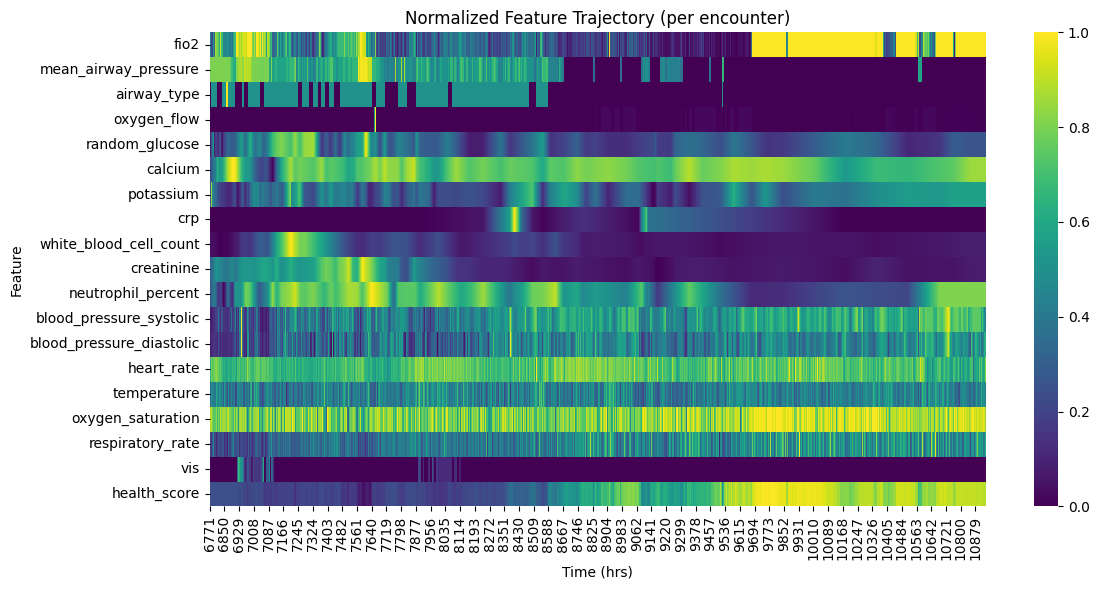

In [10]:
# 1. Min-max normalize each feature
normalized_traj = (example_training_traj - example_training_traj.min()) / (example_training_traj.max() - example_training_traj.min())

# 2. Transpose so features are rows, timepoints are columns
heatmap_data = normalized_traj.T


# 3. Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='viridis', cbar=True)
plt.xlabel("Time (hrs)")
plt.ylabel("Feature")
plt.title("Normalized Feature Trajectory (per encounter)")
plt.tight_layout()
plt.show()